In [1]:
import os
import re
import sys
from glob import glob
os.system('export HF_DATASETS_CACHE="/data/cache/huggingface"')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import scipy.stats as stats
import torch
import datasets
from datetime import datetime, timezone
import numpy as np
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
import h5py
sns.set_theme()
import obspy
import pygmt
from scipy.interpolate import interp1d
import itertools
from collections import defaultdict, deque
from sklearn.cluster import DBSCAN

In [2]:
catalog = datasets.load_dataset("./ncedc_catalog.py", split="train", name="event", cache_dir="/data/cache/huggingface")
# catalog = catalog.filter(lambda x: x["num_stations"] >= 5)
catalog.set_format("pandas")
catalog = catalog.data.to_pandas()

Found cached dataset ncedc_catalog (/data/cache/huggingface/ncedc_catalog/event/1.1.0/7420268f201e0e3e7611f9cdd02087eebffdf5a0387c07bd440775873c74f4eb)


In [3]:
catalog = catalog[catalog["num_stations"] >= 5]
catalog["event_id"] = catalog["event_id"].astype(str)
catalog["magnitude_type"] = catalog["magnitude_type"].astype(str)
catalog["magnitude"] = catalog["magnitude"].astype(float)
catalog["origin_time"] = pd.to_datetime(catalog["origin_time"])
catalog["latitude"] = catalog["latitude"].astype(float)
catalog["longitude"] = catalog["longitude"].astype(float)
catalog["depth_km"] = catalog["depth_km"].astype(float)
catalog.keys()

Index(['event_id', 'num_stations', 'origin_time', 'longitude', 'latitude',
       'depth_km', 'magnitude', 'magnitude_type', 'station_ids',
       'station_location', 'station_dist_azi', 'picks', 'dt_s'],
      dtype='object')

In [4]:
selected_columns = catalog[["event_id", "num_stations", "origin_time", "longitude", "latitude", "depth_km", "magnitude", 'magnitude_type']]
selected_columns

,event_id,num_stations,origin_time,longitude,latitude,depth_km,magnitude,magnitude_type
17,nc71076964,10,2014-01-01 18:04:19.810,-119.092300,37.631500,12.390000,0.37,D
18,nc71076969,10,2014-01-01 18:04:06.760,-119.189697,37.650501,16.809999,0.81,D
19,nc71076974,7,2014-01-09 09:25:04.300,-122.261200,38.085701,5.510000,0.90,D
24,nc71077004,5,2014-01-08 01:24:58.790,-121.139999,36.618301,0.440000,0.65,D
28,nc71077154,5,2014-01-23 01:12:01.850,-119.019798,37.633999,0.920000,-0.16,D
...,...,...,...,...,...,...,...,...
97425,nc73321871,6,2019-12-31 19:18:33.500,-122.297203,38.538700,3.930000,0.94,D
97427,nc73321881,5,2019-12-31 19:39:06.930,-120.621002,36.048000,3.900000,0.42,D
97428,nc73321886,10,2019-12-31 19:49:30.080,-122.240799,38.009300,3.790000,0.98,D
97431,nc73321901,12,2019-12-31 20:30:27.030,-121.040199,36.450298,0.900000,2.40,D


In [5]:
selected_columns.iloc[27]


event_id                          nc71080754
num_stations                               7
origin_time       2014-03-10 12:41:35.510000
longitude                           -125.388
latitude                           40.618698
depth_km                               24.66
magnitude                                2.8
magnitude_type                             D
Name: 121, dtype: object

In [6]:
num_stas = catalog['num_stations'].values
sta_locs = catalog['station_location'].values

station_locations = catalog['station_location'].values[0]
station_locations = np.unique(station_locations, axis=0)
for i in tqdm(range(1, len(num_stas))):
    station_locations = np.concatenate([station_locations, np.unique(catalog['station_location'].values[i], axis=0)], axis=0)
    if i % 1000 == 0:
        station_locations = np.unique(station_locations, axis=0)
        
station_locations = np.unique(station_locations, axis=0)

# Print the collected station locations
print(station_locations.shape)
station_locations[:10]

 32%|███▏      | 14792/46422 [00:00<00:01, 24040.86it/s]

100%|██████████| 46422/46422 [00:01<00:00, 23907.71it/s]

(1229, 3)


array([[-1.243544e+02,  4.054410e+01, -1.700000e-01],
       [-1.243426e+02,  4.028840e+01, -5.000000e-02],
       [-1.243375e+02,  4.047560e+01, -3.800000e-01],
       [-1.243343e+02,  4.287220e+01, -8.200000e-01],
       [-1.242945e+02,  4.049760e+01, -7.500000e-01],
       [-1.242877e+02,  4.032500e+01, -4.000000e-02],
       [-1.242843e+02,  4.032200e+01, -4.000000e-02],
       [-1.242660e+02,  4.025670e+01, -8.900000e-01],
       [-1.242637e+02,  4.057620e+01, -2.000000e-02],
       [-1.242260e+02,  4.221240e+01, -1.010000e+00]], dtype=float32)

In [7]:
event_locations = catalog[['longitude', 'latitude', 'depth_km']].values
event_locations[:10]

array([[-119.09230042,   37.63150024,   12.39000034],
       [-119.18969727,   37.65050125,   16.80999947],
       [-122.26119995,   38.08570099,    5.51000023],
       [-121.13999939,   36.61830139,    0.44      ],
       [-119.01979828,   37.63399887,    0.92000002],
       [-119.01979828,   37.63249969,    1.38      ],
       [-120.96279907,   35.5340004 ,   10.15999985],
       [-121.35820007,   36.73020172,   12.63000011],
       [-119.0177002 ,   37.63249969,    2.31999993],
       [-122.82250214,   38.80899811,    2.00999999]])

In [8]:
min_lon, max_lon = station_locations[:, 0].min(), station_locations[:, 0].max()
min_lon, max_lon = min(min_lon, catalog['longitude'].min()), max(max_lon, catalog['longitude'].max())
min_lat, max_lat = station_locations[:, 1].min(), station_locations[:, 1].max()
min_lat, max_lat = min(min_lat, catalog['latitude'].min()), max(max_lat, catalog['latitude'].max())

min_lon, max_lon, min_lat, max_lat

(-127.4718017578125, -114.5238, 31.2450008392334, 43.625)

makecpt [WARNING]: Without inc in -T option, -Z has no effect (ignored)


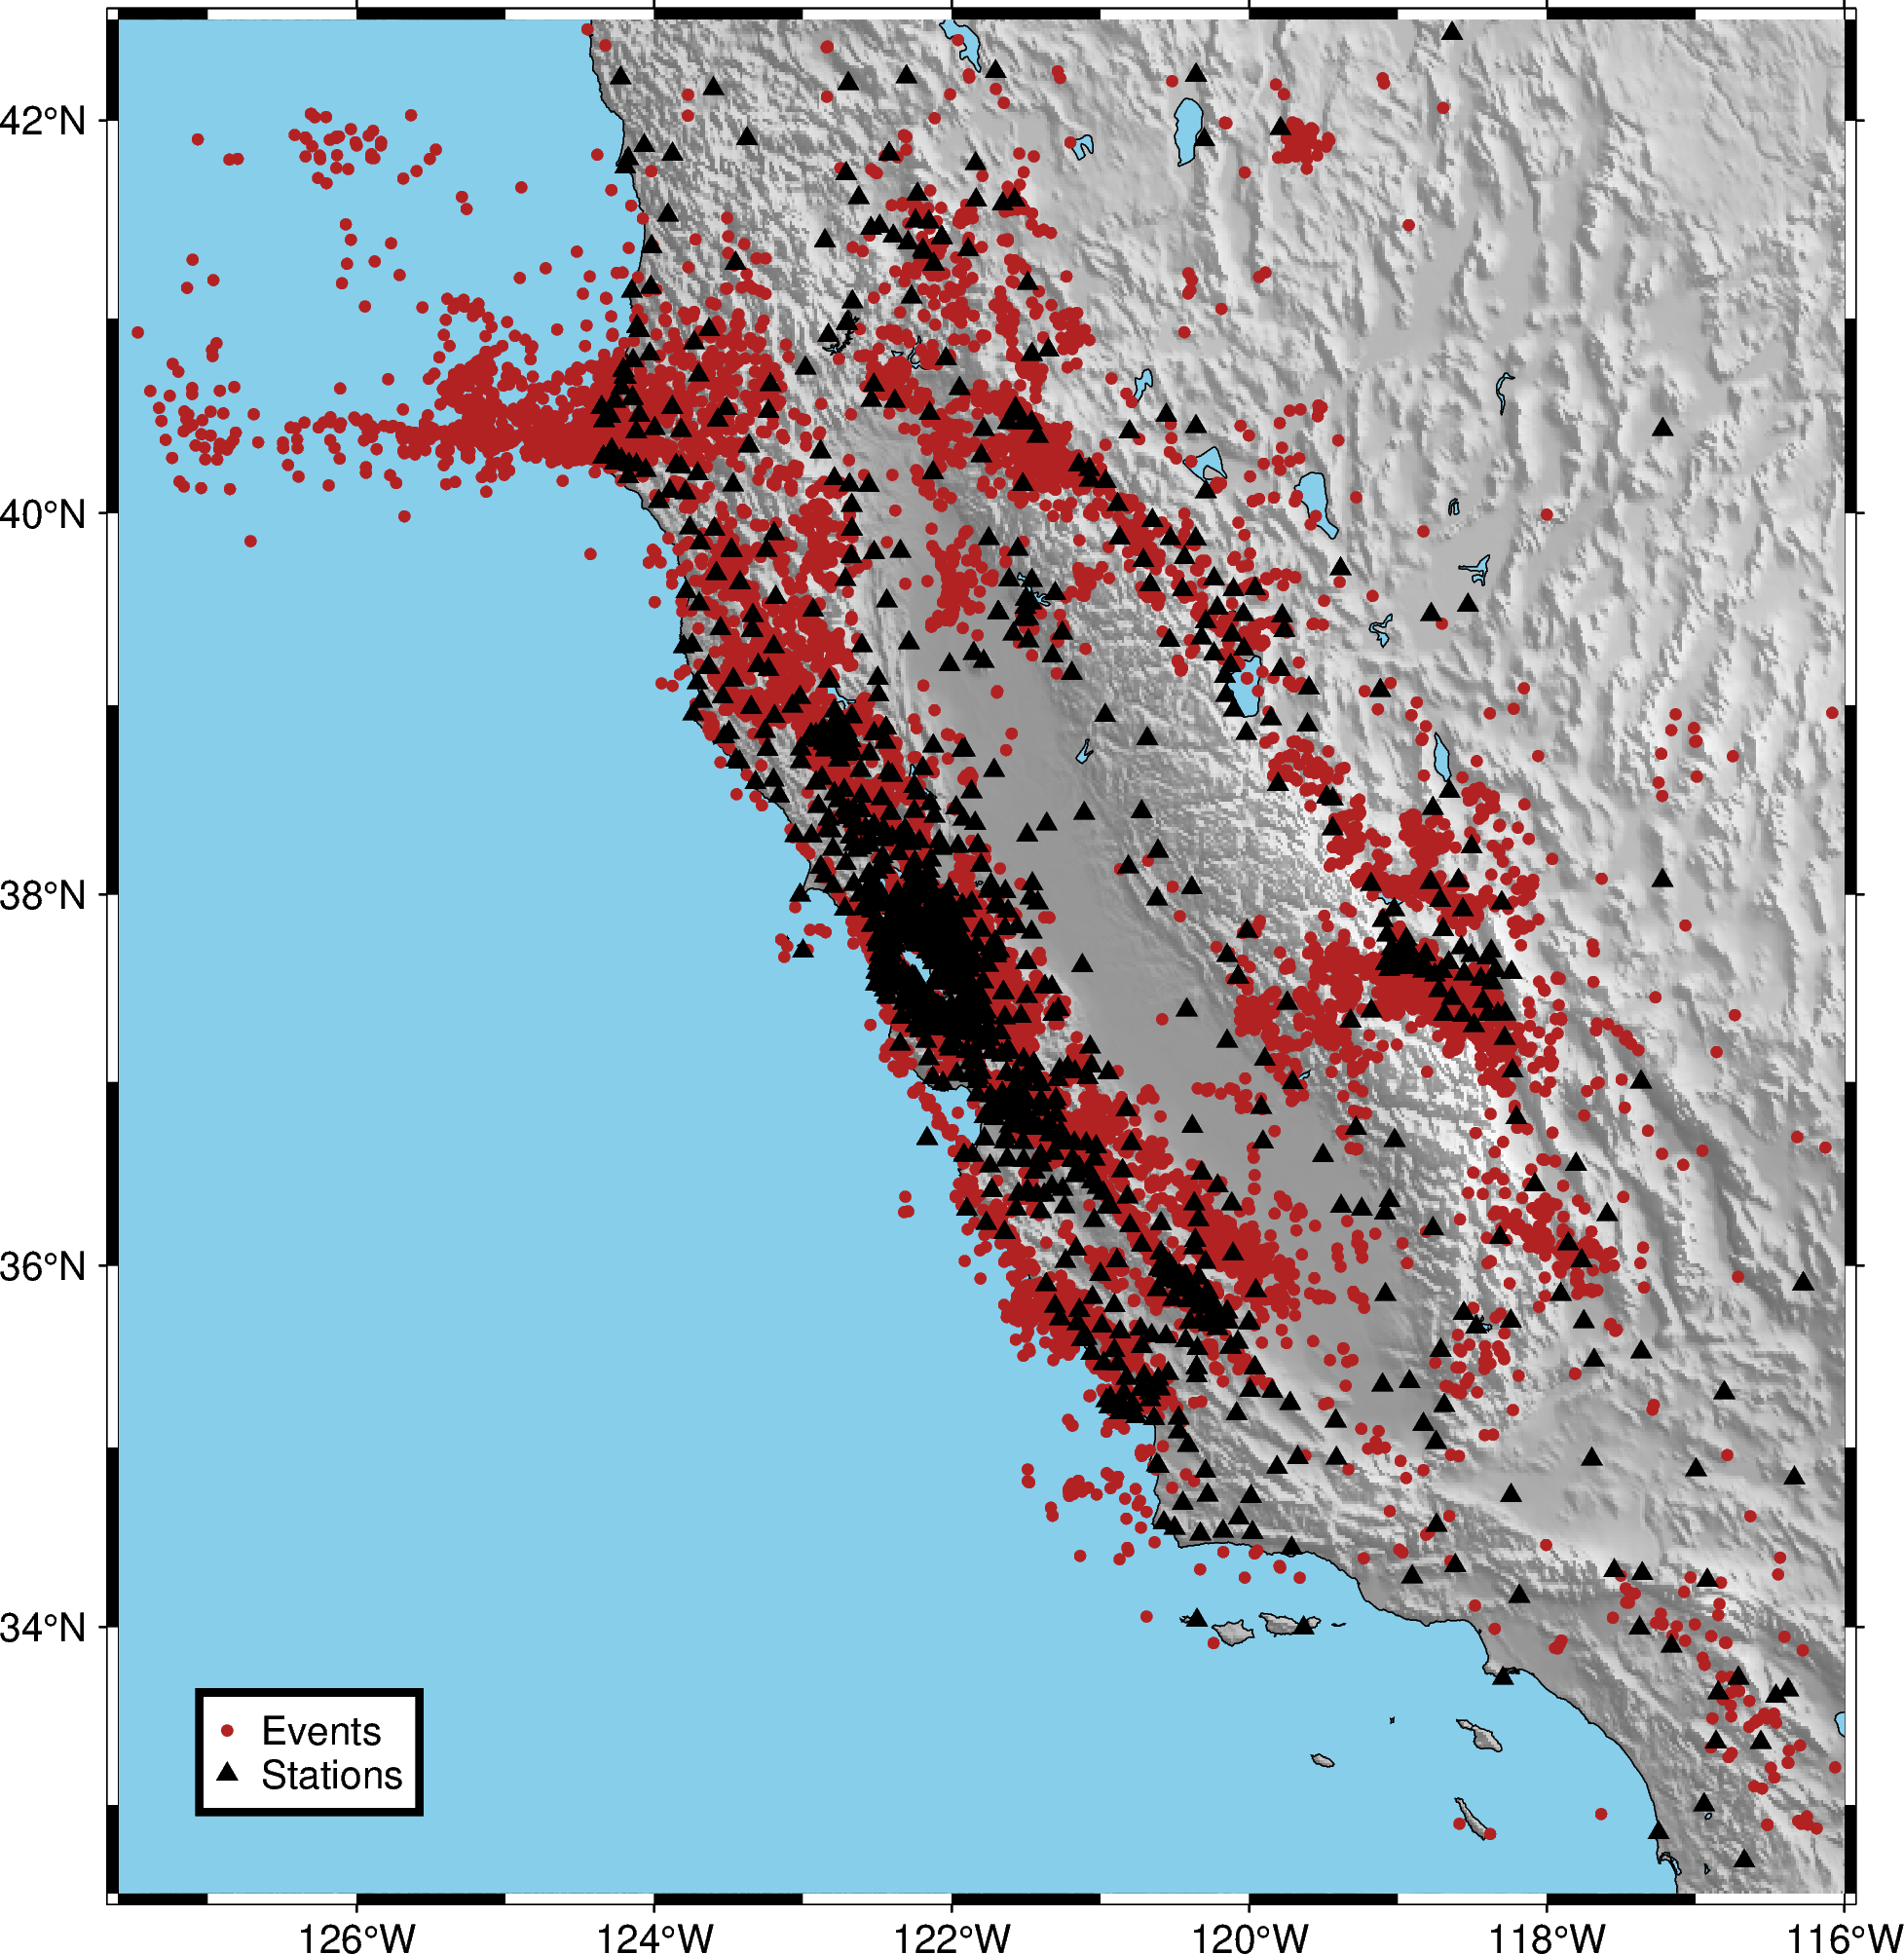

In [9]:
min_lon_lim, max_lon_lim = round(min_lon - 0.1, 1), round(max_lon + 0.1, 1)
min_lat_lim, max_lat_lim = round(min_lat - 0.1, 1), round(max_lat + 0.1, 1)

max_lon_lim=-116.0
min_lat_lim=32.5
max_lat_lim=42.5

# Define the map region
region = f"{min_lon_lim}/{max_lon_lim}/{min_lat_lim}/{max_lat_lim}"

# Create a new figure
fig = pygmt.Figure()

cpt = pygmt.makecpt(cmap="gray", series=[100, 200], continuous=True)

grid = pygmt.datasets.load_earth_relief(region=region, resolution="01m", registration="gridline")
fig.basemap(region=region, projection="M15c", frame=["af"])
# fig.coast(shorelines=True, water="skyblue", land="gray", projection="M15c")

grad = pygmt.grdgradient(grid=grid, azimuth=45, normalize="e0.5")
# fig.grdimage(grid=grid, cmap="geo", shading=True)
fig.grdimage(grid=grid, cmap="gray", transparency=75, projection="M15c", shading=grad)
fig.coast(shorelines=True, water="skyblue", projection="M15c")

# Plot the events as circles
fig.plot(
    data=event_locations[:, :2],
    style="c0.1c",
    fill="#B22222",
    label="Events",
)

# Plot the stations as triangles
fig.plot(
    data=station_locations[:, :2],
    style="t0.2c",
    fill="black",
    pen="black",
    label="Stations",
)

fig.legend(position="JBL+jBL+o0.7c", box="+gwhite+p2p,black")

# Show the figure
fig.show()


In [10]:
epicentral_distances = []

for i, (event_loc, station_loc) in enumerate(zip(event_locations, sta_locs)):
    event_loc_rad = np.radians(event_loc)
    station_loc_rad = np.radians(station_loc)
    dlon = event_loc_rad[0] - station_loc_rad[:, 0]
    dlat = event_loc_rad[1] - station_loc_rad[:, 1]
    a = np.sin(dlat / 2)**2 + np.cos(event_loc_rad[1]) * np.cos(station_loc_rad[:, 1]) * np.sin(dlon / 2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a)) * 6371
    epicentral_distances.append(c)
    if c.max() > 5000:
        print(i, c.max())
    
epicentral_distances = np.concatenate(epicentral_distances, axis=0)

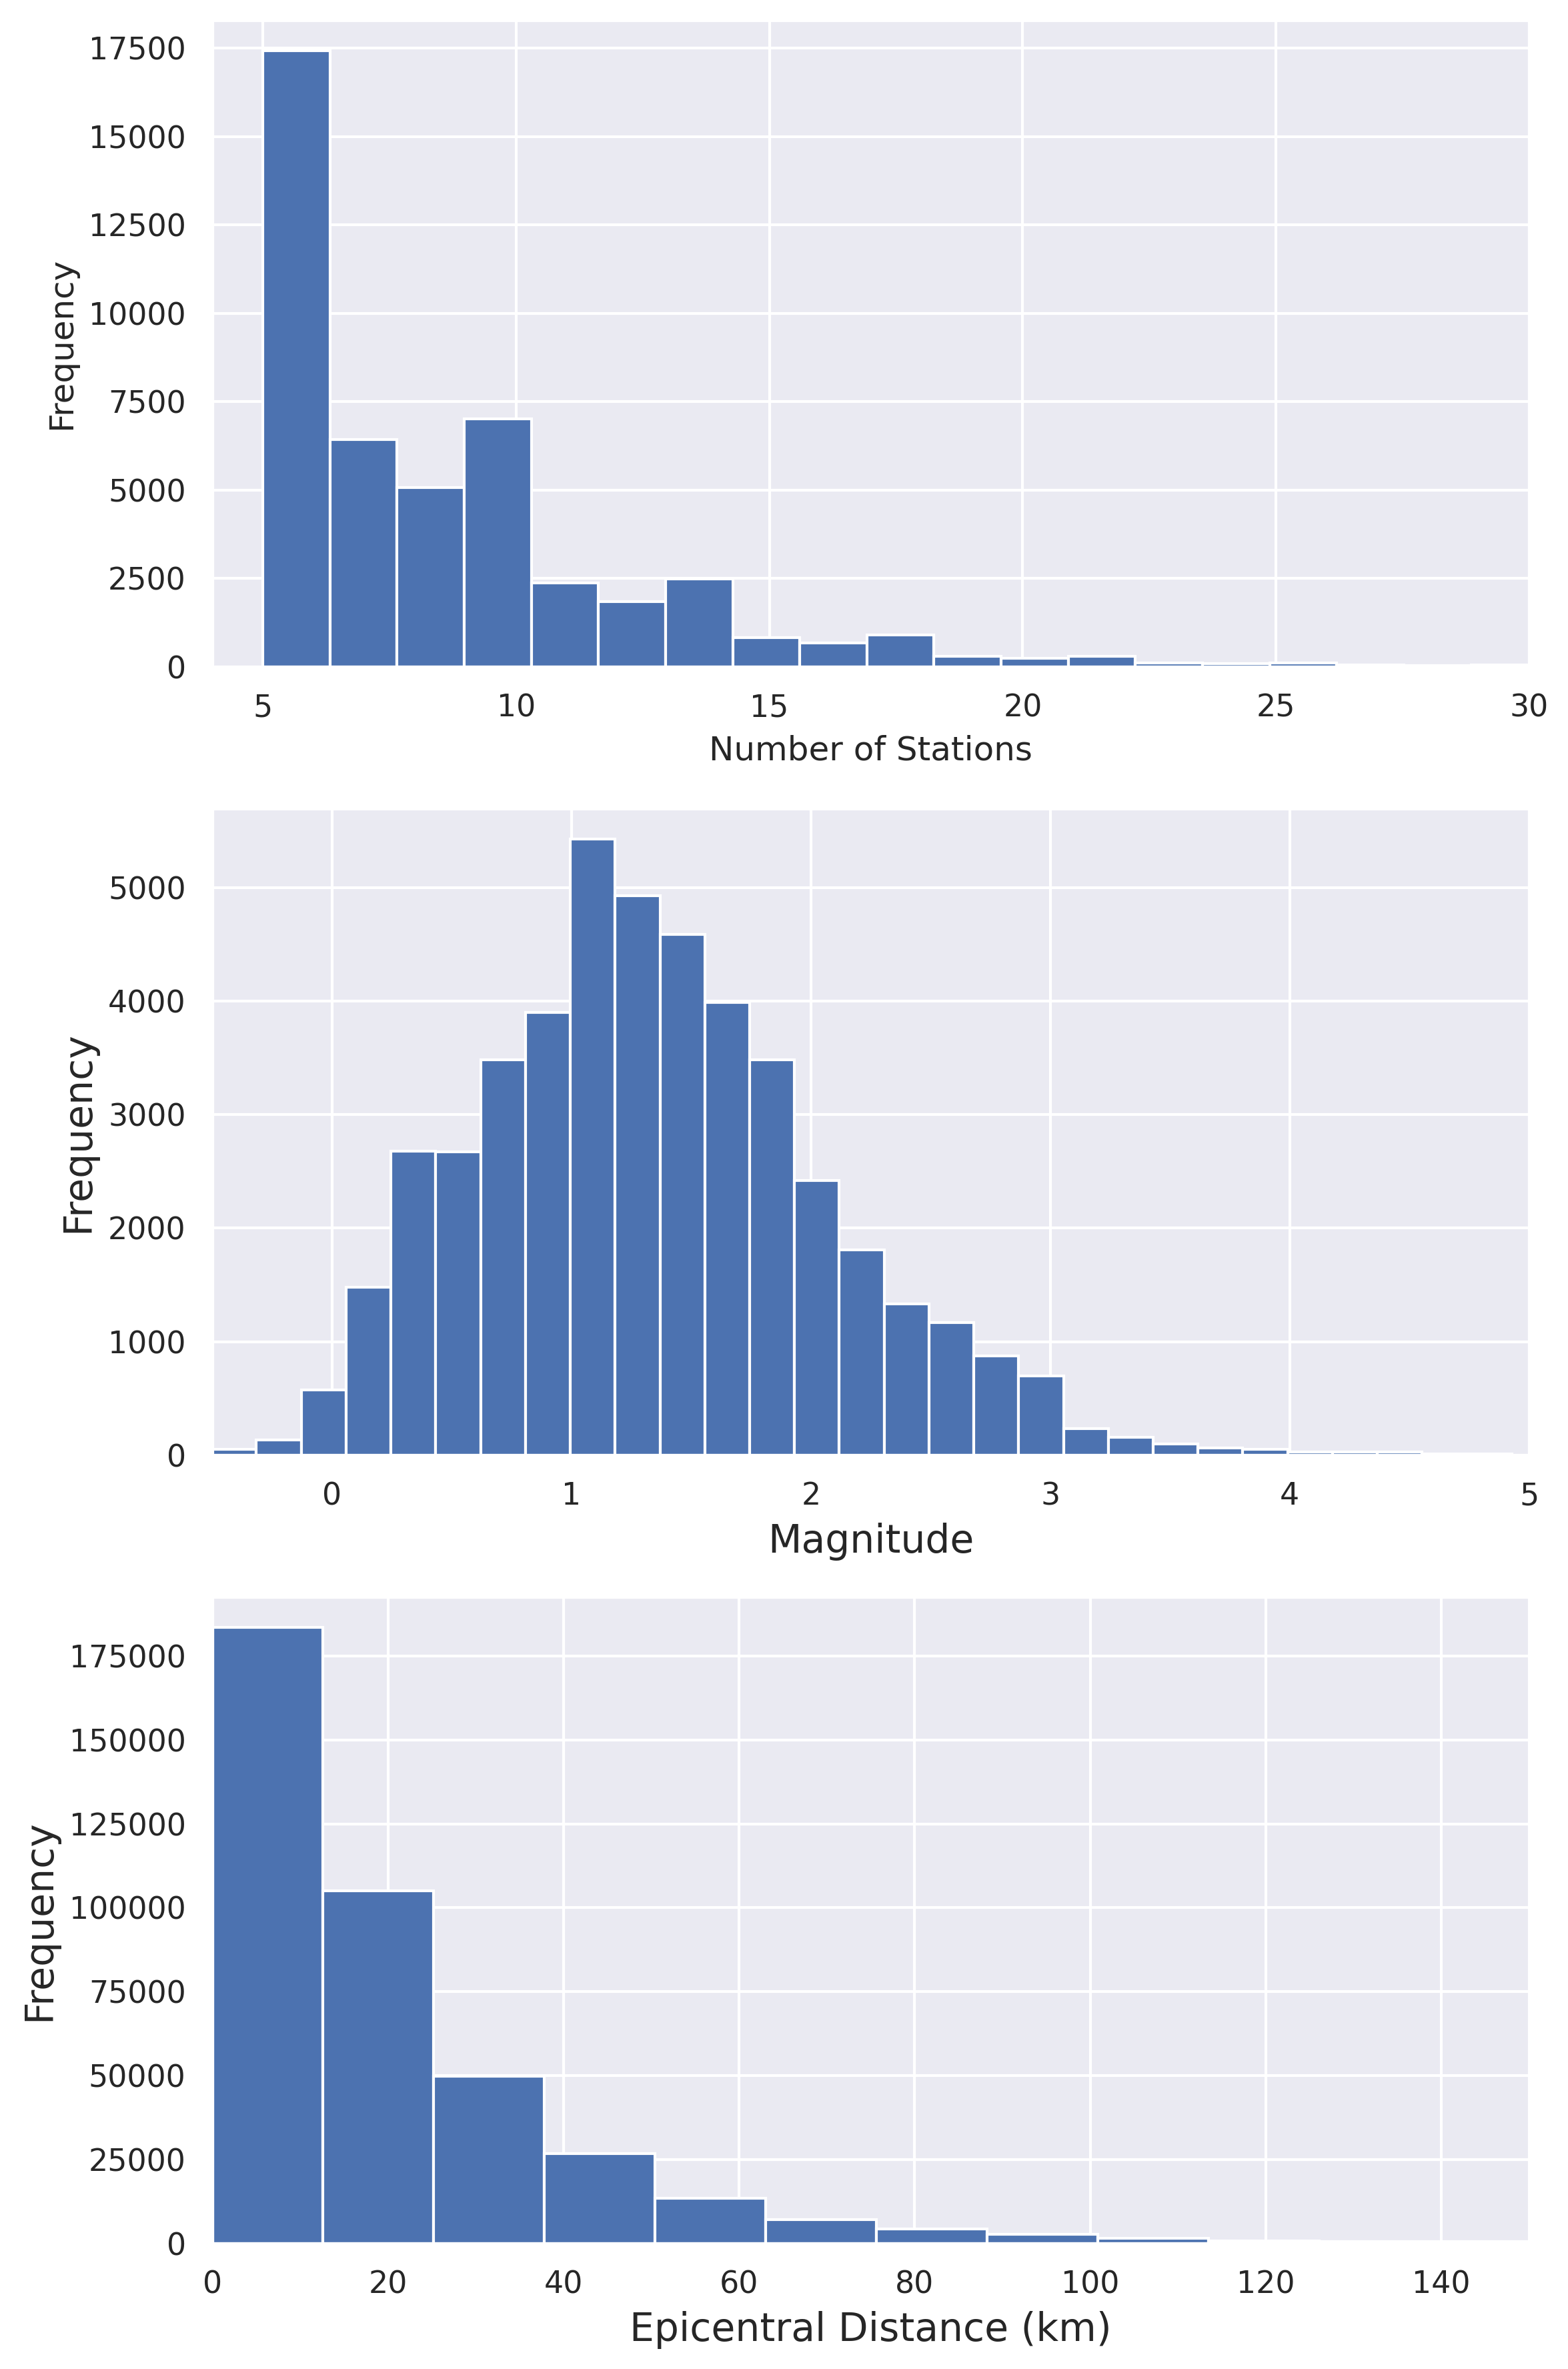

In [11]:
# Create a figure with two subplots
fig, axes = plt.subplots(3, 1, figsize=(8, 12), dpi=300)

# Plot the histogram for the "num_stations" column
axes[0].hist(catalog["num_stations"], bins=40, color="C0")
axes[0].set_xlim(4, 30)  # Set x-axis range
axes[0].set_xlabel("Number of Stations")
axes[0].set_ylabel("Frequency")
#axes[0].set_title("Stations per event distribution", fontsize=16)

# Plot the histogram for the "magnitude" column
axes[1].hist(catalog["magnitude"], bins=40, color="C0")
axes[1].set_xlabel("Magnitude", fontsize=14)
axes[1].set_ylabel("Frequency", fontsize=14)
#axes[1].set_title("Magnitude distribution", fontsize=16)
axes[1].set_xlim(-0.5, 5)  # Set x-axis range

# Plot the histogram for the "epicentral_distance"
axes[2].hist(epicentral_distances, bins=40, color="C0")
axes[2].set_xlabel("Epicentral Distance (km)", fontsize=14)
axes[2].set_ylabel("Frequency", fontsize=14)
#axes[2].set_title("Epicentral distance distribution", fontsize=16)
axes[2].set_xlim(0, 150)  # Set x-axis range

# Adjust the spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()


In [12]:
catalog_test = datasets.load_dataset("./ncedc_catalog.py", split="test", name="event", cache_dir="/data/cache/huggingface")
catalog_test.set_format("pandas")
catalog_test = catalog_test.data.to_pandas()

Found cached dataset ncedc_catalog (/data/cache/huggingface/ncedc_catalog/event/1.1.0/7420268f201e0e3e7611f9cdd02087eebffdf5a0387c07bd440775873c74f4eb)


## Metrics for Ridgecrest

In [2]:
import csv
import json
import os
import sys
import re
import h5py
from glob import glob
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import obspy
from collections import OrderedDict
from tqdm.notebook import tqdm
import fsspec
import itertools
from collections import defaultdict, deque
from sklearn.cluster import DBSCAN

import datasets
import torch
import torch.nn as nn
import torch.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler, BatchSampler

In [20]:
pick_dir = "/home/wanghy/tests/EQNet/test_eqnet_mseed_21/picks_eqnet"
event_dir = "/home/wanghy/tests/EQNet/test_eqnet_mseed_21/events_eqnet"
catalog_dir = "/home/wanghy/tests/QuakeFlow/slurm/Ridgecrest/obspy/events.csv"
catalog_pred_dir = "/home/wanghy/tests/EQNet/test_eqnet_mseed_21/catalog_pred.csv"
station_info_dir = "/home/wanghy/tests/QuakeFlow/slurm/Ridgecrest/obspy/stations.json"
valid_station_dir = "/home/wanghy/tests/QuakeFlow/slurm/Ridgecrest/obspy/stations_valid.csv"

event_dt_bar = 3 # s
dbscan_epsilon = 8
time_space_weight = [1, 0.25, 0.25, 1]
#time_space_weight = [1, 3.3, 3.3, 1]

sample_rate = 100
feature_scale = 16
degree2km = 111.32

In [4]:
catalog=pd.read_csv(catalog_dir)
catalog

,event_id,time,magnitude,latitude,longitude,depth_km,x_km,y_km,z_km
0,ci38456239,2019-07-05T23:58:13.630+00:00,2.14,35.72067,-117.53800,1.99,-3076.340,1738.811,1.99
1,ci38456231,2019-07-05T23:57:05.660+00:00,1.92,35.73133,-117.53417,9.67,-2729.137,2922.199,9.67
2,ci38456223,2019-07-05T23:55:52.650+00:00,1.94,35.72167,-117.56783,6.94,-5775.602,1851.110,6.94
3,ci38456215,2019-07-05T23:54:37.210+00:00,1.37,35.73350,-117.55717,3.25,-4809.783,3163.486,3.25
4,ci38456207,2019-07-05T23:54:17.480+00:00,1.02,35.77350,-117.59550,3.09,-8273.507,7604.221,3.09
...,...,...,...,...,...,...,...,...,...
18939,11061972,2019-07-08T00:13:25.840+00:00,3.01,35.83017,-117.66483,4.28,-14532.342,13899.683,4.28
18940,11061971,2019-07-08T00:09:16.000+00:00,1.46,35.87933,-117.65283,2.51,-13439.776,19353.368,2.51
18941,11061969,2019-07-08T00:06:11.100+00:00,1.57,36.16383,-117.38050,8.92,11112.315,50918.394,8.92
18942,11061966,2019-07-08T00:01:42.160+00:00,1.62,35.87250,-117.69900,4.71,-17610.214,18602.516,4.71


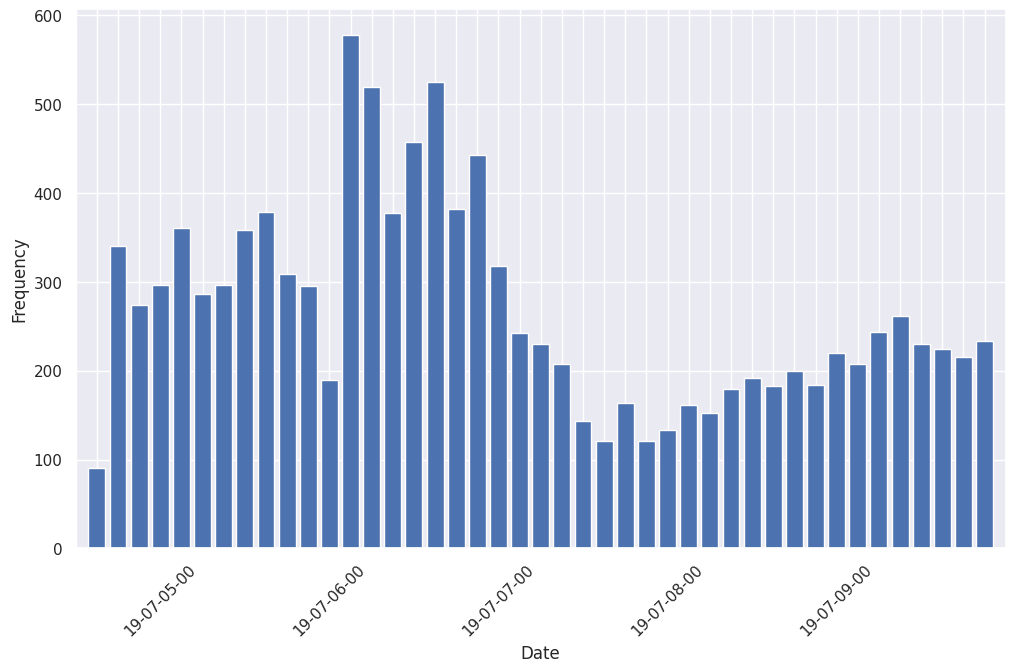

In [5]:
catalog = pd.read_csv(catalog_dir)
# sort by time, acending order
catalog = catalog.sort_values(by=['time'], ascending=True)
catalog['time'] = pd.to_datetime(catalog['time'])
# select rows with 'ci' in 'event_id'
catalog = catalog[catalog['event_id'].str.contains('ci')]
groups = catalog.groupby(pd.Grouper(key='time', freq='3H', origin=pd.to_datetime('2019-07-04 00:00:00.000000+00:00')))
counts_catalog = groups.size()

# 绘制直方图
plt.figure(figsize=(12, 7))
plt.bar(counts_catalog.index.strftime('%Y-%m-%d-%H'), counts_catalog.values, color='C0')
plt.xlim(left=4, right=len(counts_catalog))
plt.xticks(ticks=np.arange(4, len(counts_catalog), 1), labels=[idx[2:] if idx.endswith('00') else '' for idx in counts_catalog.index.strftime('%Y-%m-%d-%H')[4:len(counts_catalog)]], rotation=45)
plt.xlabel('Date')
plt.ylabel('Frequency')
plt.show()

In [6]:
def average_location(locations):
    # 将经纬度从度数转换为弧度
    locations = np.radians(locations)

    # 将经纬度转换为笛卡尔坐标
    x = np.cos(locations[:, 1]) * np.cos(locations[:, 0])
    y = np.cos(locations[:, 1]) * np.sin(locations[:, 0])
    z = np.sin(locations[:, 1])

    # 计算平均的笛卡尔坐标
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    z_mean = np.mean(z)

    # 将平均的笛卡尔坐标转换回经纬度
    lon = np.arctan2(y_mean, x_mean)
    hyp = np.sqrt(x_mean * x_mean + y_mean * y_mean)
    lat = np.arctan2(z_mean, hyp)

    # 将经纬度从弧度转换为度数
    return np.degrees([lon, lat])

In [21]:
# 获取csv_dir下所有的CSV文件的路径
event_files = [os.path.join(event_dir, f) for f in os.listdir(event_dir) if f.endswith(".csv")]

num_event_picks = 0
empty_files = 0

dbscan = DBSCAN(eps=dbscan_epsilon, min_samples=1)

station_info = json.load(open(station_info_dir, "r"))

events = []
for pick in tqdm(event_files):
    # skip the empty pick file
    if os.path.getsize(pick) == 0:
        empty_files += 1
        continue
    df = pd.read_csv(pick)
    
    stations = df["station_id"].values
    time_stamps = pd.to_datetime(df["event_original_time"])
    assert type(time_stamps) == pd.core.series.Series
    hypoparameters = np.zeros((len(df),8))
    hypoparameters[:,0] = df["event_index"].values
    hypoparameters[:,1] = df["event_location_x"].values
    hypoparameters[:,2] = df["event_location_y"].values
    hypoparameters[:,3] = df["event_location_z"].values
    hypoparameters[:,4] = df["event_longitude"].values
    hypoparameters[:,5] = df["event_latitude"].values
    hypoparameters[:,6] = df["epicentral_distance"].values
    hypoparameters[:,7] = df["magnitude"].values
    
    
    labels = dbscan.fit_predict(hypoparameters[:,:4]*np.array(time_space_weight)[None,:]) # weighted
    classes, counts = np.unique(labels, return_counts=True)
    if len(df) > 5 and len(classes) > 1:
        if classes[0] == -1:
            classes = classes[1:]
            counts = counts[1:]
        classes = classes[counts>1]
        
    for c in classes:
        cluster_picks = hypoparameters[labels==c]
        time_stamp = time_stamps[labels==c]
        time_stamp = time_stamp.iloc[np.argsort(cluster_picks[:,6])][:30]
        cluster_picks = cluster_picks[np.argsort(cluster_picks[:,6])][:80]
        info = {}
        info["event_id"] = f'{num_event_picks}'
        info["time"] = time_stamp.median()
        info["magnitude"] = np.median(cluster_picks[:10,7])
        #avg_center = average_location(cluster_picks[:,4:6])
        avg_center = np.median(cluster_picks[:10,4:6], axis=0)
        x_pred = avg_center[0]*np.cos(np.radians(avg_center[1])) * degree2km
        y_pred = avg_center[1] * degree2km
        z_pred = np.median(cluster_picks[:10,3])
        info["latitude"] = avg_center[1]
        info["longitude"] = avg_center[0]
        info["depth_km"] = z_pred
        info["x_km"] = x_pred
        info["y_km"] = y_pred
        info["z_km"] = z_pred
        
        events.append(pd.DataFrame(info, index=[0]))
        num_event_picks += 1
        
events = pd.concat(events, ignore_index=True)
events = events.sort_values(by="time", ascending=True)
events['time'] = events['time'].apply(lambda x: x.strftime('%Y-%m-%dT%H:%M:%S.%fZ'))
events.to_csv(catalog_pred_dir, index=False)
print(f"empty files: {empty_files}")

  0%|          | 0/144 [00:00<?, ?it/s]

empty files: 0


In [25]:
catalog_pred = pd.read_csv(catalog_pred_dir)
catalog_pred

,event_id,time,magnitude,latitude,longitude,depth_km,x_km,y_km,z_km
0,21469,2019-07-04T00:01:59.268499Z,1.218750,35.873312,-118.127735,15.153750,-10655.621424,3993.417091,15.153750
1,21491,2019-07-04T00:05:26.092499Z,1.468750,35.603924,-117.345745,9.860000,-10620.956190,3963.428797,9.860000
2,21492,2019-07-04T00:05:48.504999Z,1.015625,36.294151,-117.934132,13.530000,-10581.364373,4040.264923,13.530000
3,21493,2019-07-04T00:05:51.123500Z,1.109375,36.445623,-117.597588,8.780000,-10530.646113,4057.126797,8.780000
4,21494,2019-07-04T00:06:13.488999Z,1.531250,35.948074,-117.226753,4.485000,-10564.361802,4001.739636,4.485000
...,...,...,...,...,...,...,...,...,...
38902,34970,2019-07-09T23:58:51.984999Z,0.888672,36.205526,-117.756840,4.241250,-10577.446910,4030.399193,4.241250
38903,34971,2019-07-09T23:59:07.068999Z,1.027344,35.780338,-117.528000,8.188750,-10613.949536,3983.067258,8.188750
38904,34972,2019-07-09T23:59:09.902000Z,0.871094,35.722029,-117.417004,8.523750,-10611.697459,3976.576238,8.523750
38905,34973,2019-07-09T23:59:35.401500Z,1.347656,35.683929,-117.407784,7.351875,-10615.936039,3972.335026,7.351875


In [23]:
catalog_pred[catalog_pred["time"]<="2019-07-04T15:00:00.000000Z"]

,event_id,time,magnitude,latitude,longitude,depth_km,x_km,y_km,z_km
0,21469,2019-07-04T00:01:59.268499Z,1.218750,35.873312,-118.127735,15.153750,-10655.621424,3993.417091,15.153750
1,21491,2019-07-04T00:05:26.092499Z,1.468750,35.603924,-117.345745,9.860000,-10620.956190,3963.428797,9.860000
2,21492,2019-07-04T00:05:48.504999Z,1.015625,36.294151,-117.934132,13.530000,-10581.364373,4040.264923,13.530000
3,21493,2019-07-04T00:05:51.123500Z,1.109375,36.445623,-117.597588,8.780000,-10530.646113,4057.126797,8.780000
4,21494,2019-07-04T00:06:13.488999Z,1.531250,35.948074,-117.226753,4.485000,-10564.361802,4001.739636,4.485000
...,...,...,...,...,...,...,...,...,...
410,10464,2019-07-04T14:53:25.624999Z,1.437500,35.906960,-117.303635,15.360000,-10576.788496,3997.162735,15.360000
411,10466,2019-07-04T14:56:39.661499Z,1.269531,36.038054,-117.449913,18.469999,-10572.405963,4011.756117,18.469999
412,10467,2019-07-04T14:57:23.839000Z,1.441406,35.940432,-117.888363,19.172501,-10625.012985,4000.888845,19.172501
413,10468,2019-07-04T14:58:06.083000Z,1.023438,36.015011,-117.995743,14.485000,-10624.646565,4009.191006,14.485000


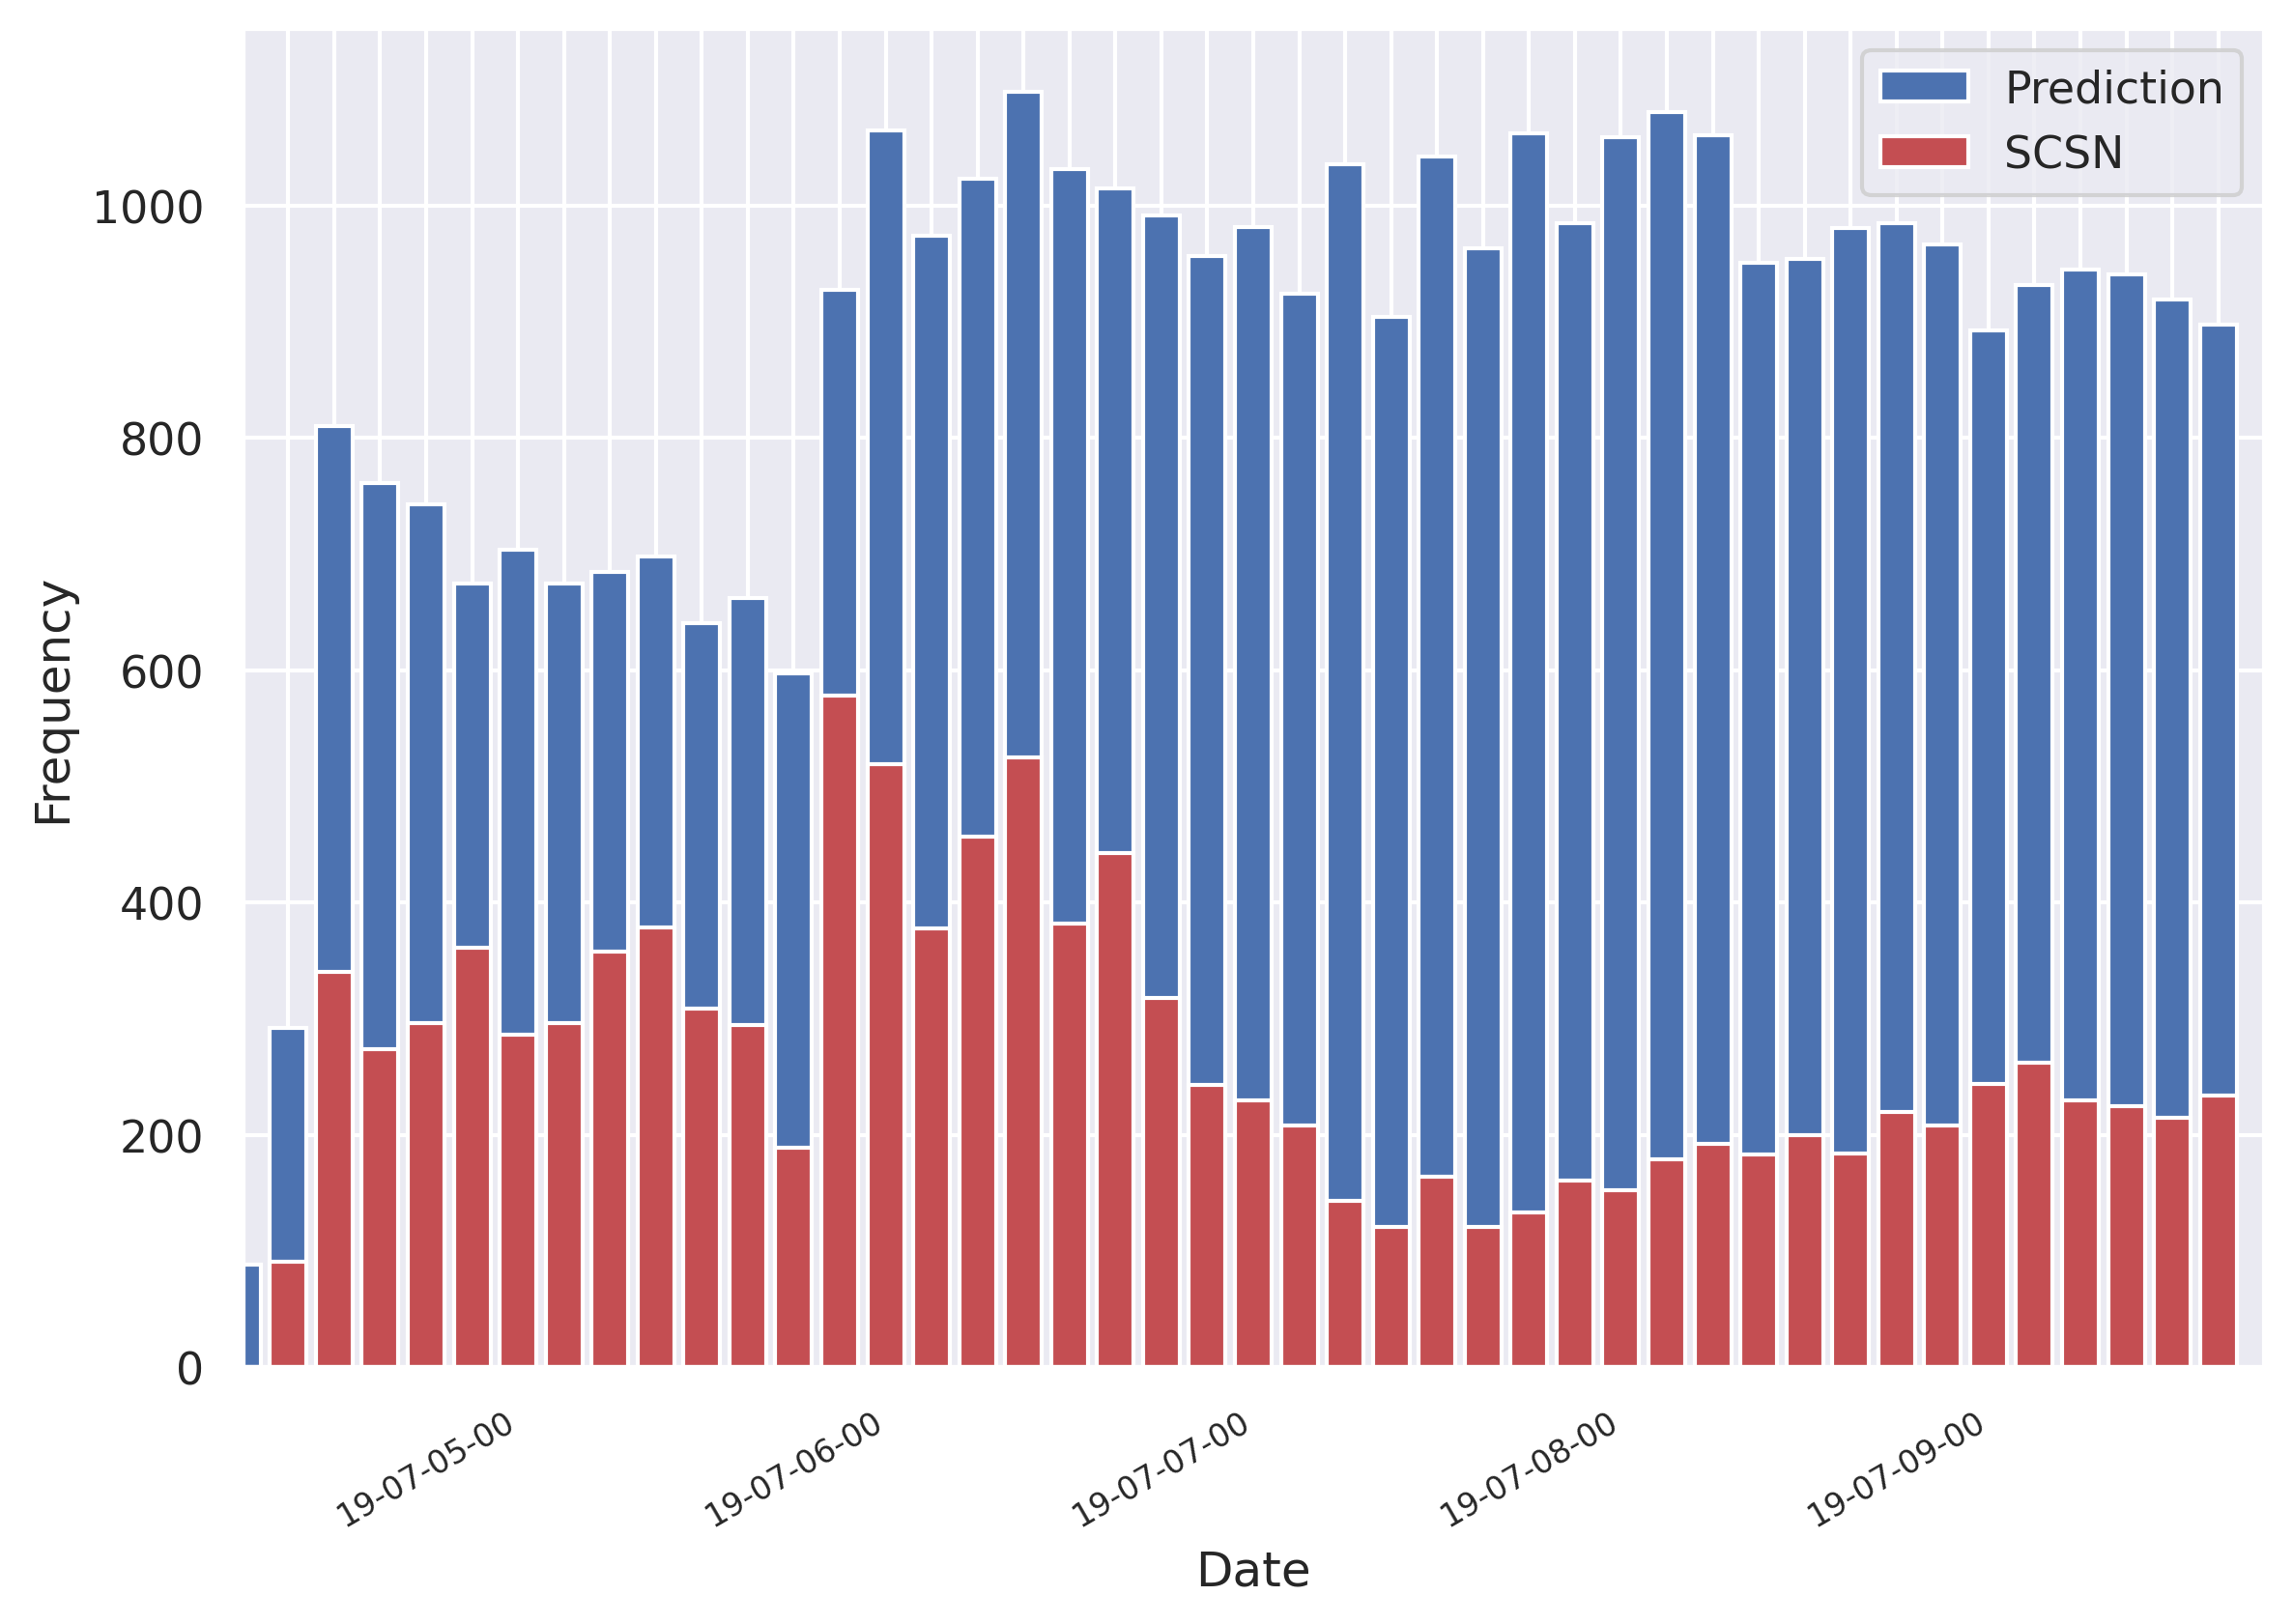

In [26]:
catalog_pred['time'] = pd.to_datetime(catalog_pred['time'])
groups_pred = catalog_pred.groupby(pd.Grouper(key='time', freq='3H', origin=pd.to_datetime('2019-07-04 00:00:00.000000+00:00')))
counts_pred = groups_pred.size()

# 绘制直方图
plt.figure(figsize=(9, 6), dpi=300)
plt.bar(counts_pred.index.strftime('%Y-%m-%d-%H'), counts_pred.values, color='C0', label='Prediction')
plt.bar(counts_catalog.index.strftime('%Y-%m-%d-%H'), counts_catalog.values, color='C3', label='SCSN')
plt.xlim(left=4, right=len(counts_catalog))
plt.xticks(ticks=np.arange(4, len(counts_catalog), 1), labels=[idx[2:] if idx.endswith('00') else '' for idx in counts_catalog.index.strftime('%Y-%m-%d-%H')[4:len(counts_catalog)]],
           rotation=30, fontsize=8)
plt.xlabel('Date')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [27]:
catalog = pd.read_csv(catalog_dir)
catalog_pred = pd.read_csv(catalog_pred_dir)

catalog['time'] = pd.to_datetime(catalog['time'])
catalog = catalog.sort_values(by='time', ascending=True)
catalog_pred['time'] = pd.to_datetime(catalog_pred['time'])
catalog_pred = catalog_pred.sort_values(by='time', ascending=True)
catalog['proj_x'] = catalog['longitude'] * degree2km * np.cos(np.radians(catalog['latitude']))
catalog['proj_y'] = catalog['latitude'] * degree2km

# select rows with 'ci' in 'event_id'
catalog = catalog[catalog['event_id'].str.contains('ci')]

In [28]:
time_res = []
x_res = []
y_res = []
z_res = []
magnitude_res = []
x = []
y = []
z = []
lon_preds = []
lat_preds = []
lon_res = []
lat_res = []

iterrows_pred = catalog_pred.iterrows()

for _, row in catalog.iterrows():
    while True:
        try:
            index, row_pred = next(iterrows_pred)
            time_diff = (row_pred['time'].timestamp() - row['time'].timestamp())
            if time_diff > event_dt_bar:
                # undo the next() call
                iterrows_pred = itertools.chain([(index, row_pred)], iterrows_pred)
                break
            else:
                x_diff = row_pred['x_km'] - row['proj_x']
                y_diff = row_pred['y_km'] - row['proj_y']
                z_diff = row_pred['z_km'] - row['z_km']
                lon_diff = row_pred['longitude'] - row['longitude']
                lat_diff = row_pred['latitude'] - row['latitude']
                magnitude_diff = row_pred['magnitude'] - row['magnitude']
                if np.isnan(magnitude_diff):
                    print(row_pred['magnitude'], row['magnitude'], row['event_id'], index)
                if (abs(time_diff)<=event_dt_bar) and (abs(lon_diff)<0.3) and (abs(lat_diff)<0.3) and (abs(z_diff)<10):
                    time_res.append(time_diff)
                    x_res.append(x_diff)
                    y_res.append(y_diff)
                    z_res.append(z_diff)
                    magnitude_res.append(magnitude_diff)
                    x.append(row_pred['x_km'])
                    y.append(row_pred['y_km'])
                    z.append(row_pred['z_km'])
                    lon_preds.append(row_pred['longitude'])
                    lat_preds.append(row_pred['latitude'])
                    lon_res.append(row_pred['longitude'] - row['longitude'])
                    lat_res.append(row_pred['latitude'] - row['latitude'])
                    break
        except StopIteration:
            break

time_res = np.array(time_res)
x_res = np.array(x_res)
y_res = np.array(y_res)
z_res = np.array(z_res)
magnitude_res = np.array(magnitude_res)
x = np.array(x)
y = np.array(y)
z = np.array(z)
lon_preds = np.array(lon_preds)
lat_preds = np.array(lat_preds)
lon_res = np.array(lon_res)
lat_res = np.array(lat_res)

1.92578125 nan ci38471359 16741
1.78125 nan ci38471359 16742
1.8125 nan ci38471359 16743
1.59375 nan ci38471383 16754
1.1328125 nan ci38471391 16755
2.09375 nan ci38471391 16756
1.53515625 nan ci38471391 16757
1.9453125 nan ci38471415 16777
1.359375 nan ci38471415 16778
1.734375 nan ci38471415 16779
2.03125 nan ci38471415 16780
1.875 nan ci38471415 16781


In [29]:
num_event_picks = len(catalog_pred)
num_event_picks_label = len(catalog)

true_positives = len(time_res)
false_positives = num_event_picks - true_positives
false_negatives = num_event_picks_label - true_positives

precision = true_positives / (true_positives + false_positives)
recall = true_positives / (true_positives + false_negatives)
f1 = 2 * (precision * recall) / (precision + recall)

# the distribution of time-space residual
res_event_time = time_res
res_event_x = x_res
res_event_y = y_res
res_event_z = z_res
event_z = z
res_magnitude = magnitude_res

miu_t = res_event_time.mean()
miu_x = res_event_x.mean()
miu_y = res_event_y.mean()
miu_z = res_event_z.mean()
# because the magnitude may lost in the catalog, so we need to exclude the nan value
miu_m = res_magnitude[~np.isnan(res_magnitude)].mean()
sigma_t = res_event_time.std()
sigma_x = res_event_x.std()
sigma_y = res_event_y.std()
sigma_z = res_event_z.std()
sigma_m = res_magnitude[~np.isnan(res_magnitude)].std()

picks: 36411, picks_label: 11530
TP: 9223, FP: 27188, FN: 2307
precision: 0.2533, recall: 0.7999, f1: 0.3848
miu_t: -0.0377, miu_x: 5.3813, miu_y: 5.7655, miu_z: 1.9346, miu_m: -0.5690
sigma_t: 0.6949, sigma_x: 18.3002, sigma_y: 13.0493, sigma_z: 2.8462, sigma_m: 0.5190

picks: 36411, picks_label: 11530
TP: 9256, FP: 27155, FN: 2274
precision: 0.2542, recall: 0.8028, f1: 0.3861
miu_t: -0.0554, miu_x: 3.4888, miu_y: 3.3495, miu_z: 1.6522, miu_m: -0.5774
sigma_t: 0.6948, sigma_x: 16.9962, sigma_y: 11.5395, sigma_z: 2.8670, sigma_m: 0.5224


picks: 38907, picks_label: 11530
TP: 9354, FP: 29553, FN: 2176
precision: 0.2404, recall: 0.8113, f1: 0.3709
miu_t: -0.1383, miu_x: 4.9674, miu_y: 3.0562, miu_z: 1.6303, miu_m: -0.3229
sigma_t: 0.7237, sigma_x: 16.8284, sigma_y: 11.9526, sigma_z: 3.0965, sigma_m: 0.5103


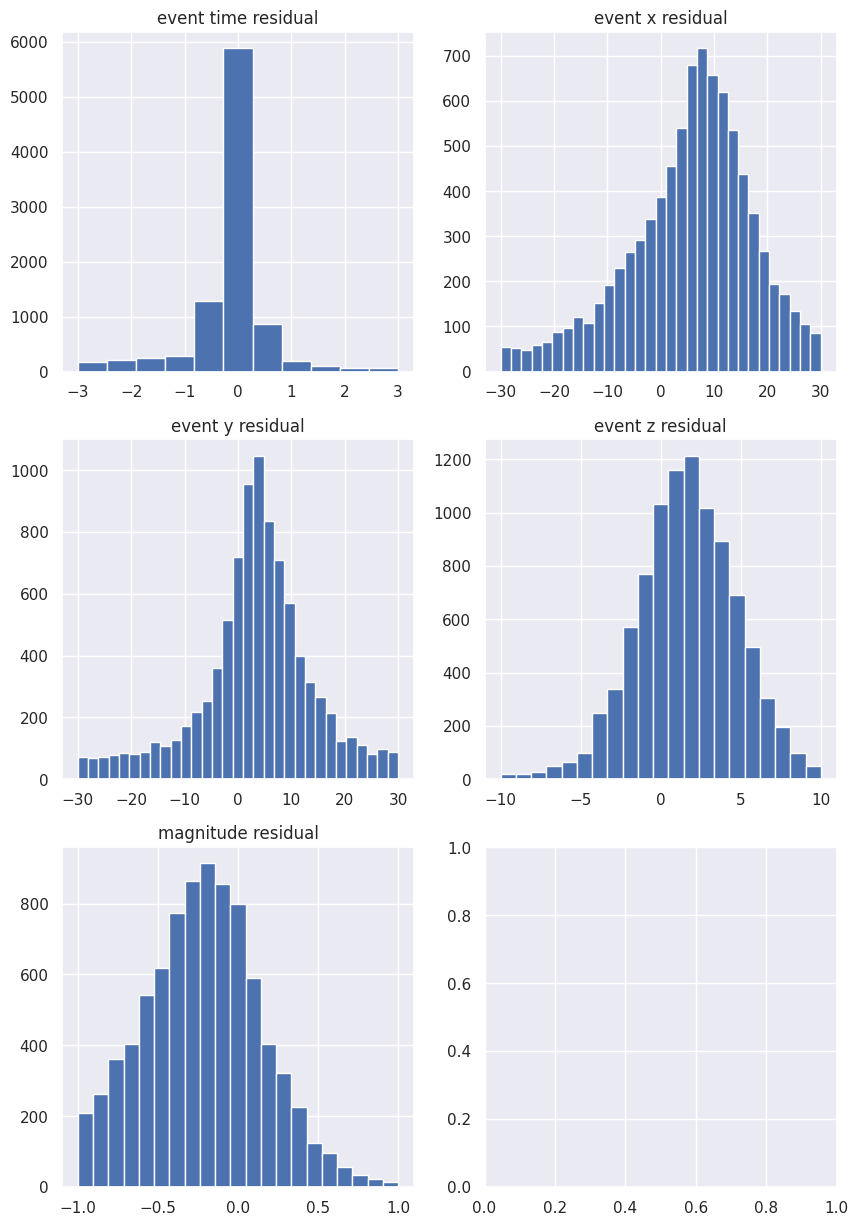

In [30]:
print(f"picks: {num_event_picks}, picks_label: {num_event_picks_label}")
print(f"TP: {true_positives}, FP: {false_positives}, FN: {false_negatives}")
print(f"precision: {precision:.4f}, recall: {recall:.4f}, f1: {f1:.4f}")
print(f"miu_t: {miu_t:.4f}, miu_x: {miu_x:.4f}, miu_y: {miu_y:.4f}, miu_z: {miu_z:.4f}, miu_m: {miu_m:.4f}")
print(f"sigma_t: {sigma_t:.4f}, sigma_x: {sigma_x:.4f}, sigma_y: {sigma_y:.4f}, sigma_z: {sigma_z:.4f}, sigma_m: {sigma_m:.4f}")

fig, ax = plt.subplots(3, 2, figsize=(10, 15))
ax[0, 0].hist(res_event_time, bins=11, range=(-3, 3))
ax[0, 0].set_title("event time residual")
ax[0, 1].hist(res_event_x, bins=31, range=(-30, 30))
ax[0, 1].set_title("event x residual")
ax[1, 0].hist(res_event_y, bins=31, range=(-30, 30))
ax[1, 0].set_title("event y residual")
ax[1, 1].hist(res_event_z, bins=21, range=(-10, 10))
ax[1, 1].set_title("event z residual")
ax[2, 0].hist(res_magnitude, bins=21, range=(-1, 1))
ax[2, 0].set_title("magnitude residual")
plt.show()

miu_lon: 0.0142, miu_lat: 0.0275
sigma_lon: 0.0906, sigma_lat: 0.1074


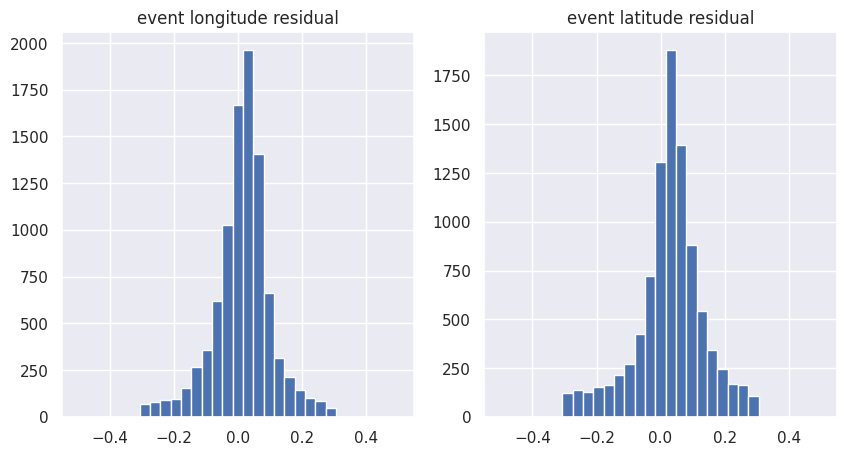

In [31]:
miu_lon = lon_res.mean()
miu_lat = lat_res.mean()
sigma_lon = lon_res.std()
sigma_lat = lat_res.std()
print(f"miu_lon: {miu_lon:.4f}, miu_lat: {miu_lat:.4f}")
print(f"sigma_lon: {sigma_lon:.4f}, sigma_lat: {sigma_lat:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].hist(lon_res, bins=31, range=(-0.5, 0.5))
ax[0].set_title("event longitude residual")
ax[1].hist(lat_res, bins=31, range=(-0.5, 0.5))
ax[1].set_title("event latitude residual")
plt.show()

In [32]:
valid_stations = pd.read_csv(valid_station_dir)
valid_stations

,station_id,network,station,location,instrument,component,sensitivity,latitude,longitude,elevation_m,depth_km,x_km,y_km,z_km
0,CI.CCC..BH,CI,CCC,NaN,BH,ENZ,"[627368000.0, 627368000.0, 627368000.0]",35.524948,-117.364532,670.0,-0.670,12649.964,-19968.158,-0.670
1,CI.CCC..HH,CI,CCC,NaN,HH,ENZ,"[627368000.0, 627368000.0, 627368000.0]",35.524948,-117.364532,670.0,-0.670,12649.964,-19968.158,-0.670
2,CI.CCC..HN,CI,CCC,NaN,HN,ENZ,"[213979.0, 214322.0, 213808.0]",35.524948,-117.364532,670.0,-0.670,12649.964,-19968.158,-0.670
3,CI.CLC..BH,CI,CLC,NaN,BH,ENZ,"[627372967.472856, 627372967.472856, 627372967...",35.815740,-117.597510,775.0,-0.775,-8450.784,12291.142,-0.775
4,CI.CLC..HH,CI,CLC,NaN,HH,ENZ,"[627368612.778848, 627368612.778848, 627368612...",35.815740,-117.597510,775.0,-0.775,-8450.784,12291.142,-0.775
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,ZY.SV05.CC.HN,ZY,SV05,CC,HN,ENZ,"[320889.0, 320889.0, 320889.0]",35.722400,-117.571900,664.0,-0.664,-6143.498,1932.719,-0.664
77,ZY.SV07..HH,ZY,SV07,NaN,HH,ENZ,"[274899000.0, 274899000.0, 274899000.0]",35.697600,-117.603200,664.0,-0.664,-8978.260,-816.520,-0.664
78,ZY.SV07.CC.HH,ZY,SV07,CC,HH,ENZ,"[274899000.0, 274899000.0, 274899000.0]",35.697600,-117.603200,664.0,-0.664,-8978.260,-816.520,-0.664
79,ZY.SV07..HN,ZY,SV07,NaN,HN,ENZ,"[187116.0, 187116.0, 187116.0]",35.697600,-117.603200,664.0,-0.664,-8978.260,-816.520,-0.664


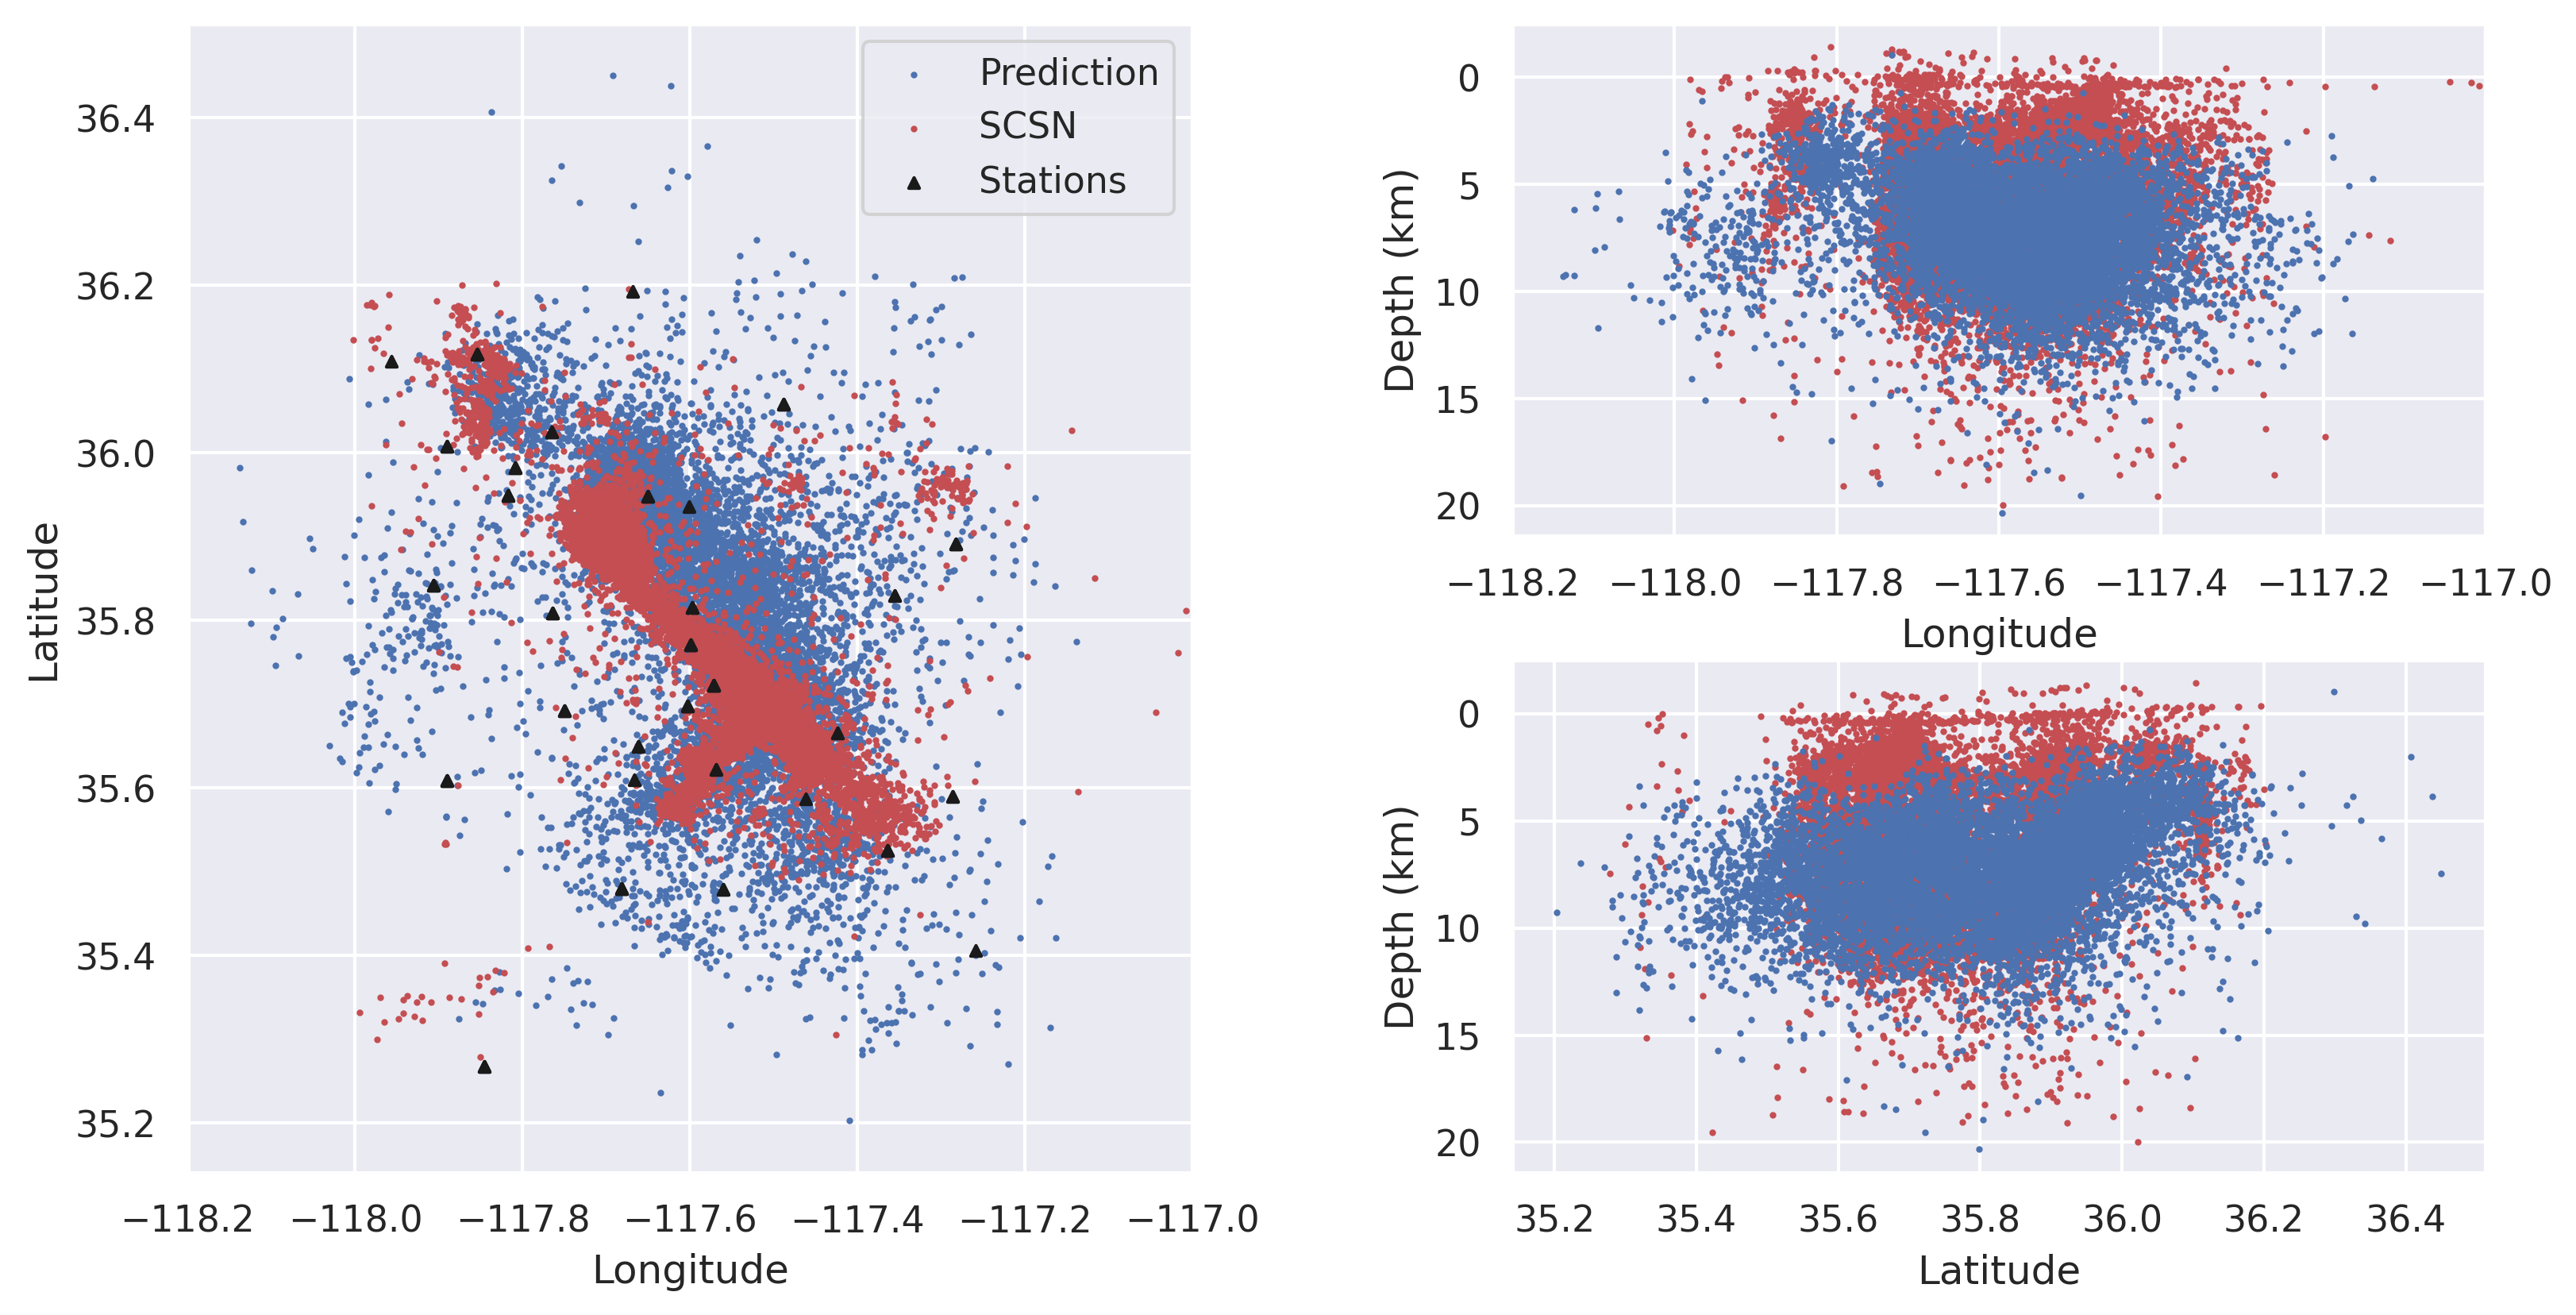

In [33]:
# plot the distribution of the event location
fig = plt.figure(figsize=(14, 8), dpi=300)
axes=[]
axes.append(plt.subplot2grid((14, 13), (0, 0), colspan=8, rowspan=11))
axes.append(plt.subplot2grid((14, 13), (0, 8), colspan=6, rowspan=5))
axes.append(plt.subplot2grid((14, 13), (6, 8), colspan=6, rowspan=5))


#axes[0].scatter(catalog_pred['longitude'], catalog_pred['latitude'], s=1, c='C0', label='Prediction')
axes[0].scatter(lon_preds, lat_preds, s=1, c='C0', label='Prediction')
axes[0].scatter(catalog['longitude'], catalog['latitude'], s=1, c='C3', label='SCSN')
axes[0].scatter(valid_stations['longitude'], valid_stations['latitude'], s=10, marker='^', c='k', label='Stations')
axes[0].set_xlim(-118.2, -117.0)
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].set_aspect("equal")
axes[0].legend()

axes[1].scatter(catalog['longitude'], catalog['depth_km'], s=1, c='C3', label='SCSN')
#axes[1].scatter(catalog_pred['longitude'], catalog_pred['z_km'], s=1, c='C0', label='Prediction')
axes[1].scatter(lon_preds, z, s=1, c='C0', label='Prediction')
# reverse the y axis
axes[1].set_ylim(axes[1].get_ylim()[::-1])
axes[1].set_xlim(-118.2, -117.0)
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Depth (km)')

axes[2].scatter(catalog['latitude'], catalog['depth_km'], s=1, c='C3', label='SCSN')
#axes[2].scatter(catalog_pred['latitude'], catalog_pred['z_km'], s=1, c='C0', label='Prediction')
axes[2].scatter(lat_preds, z, s=1, c='C0', label='Prediction')
# reverse the y axis
axes[2].set_ylim(axes[2].get_ylim()[::-1])
axes[2].set_xlabel('Latitude')
axes[2].set_ylabel('Depth (km)')

plt.show()

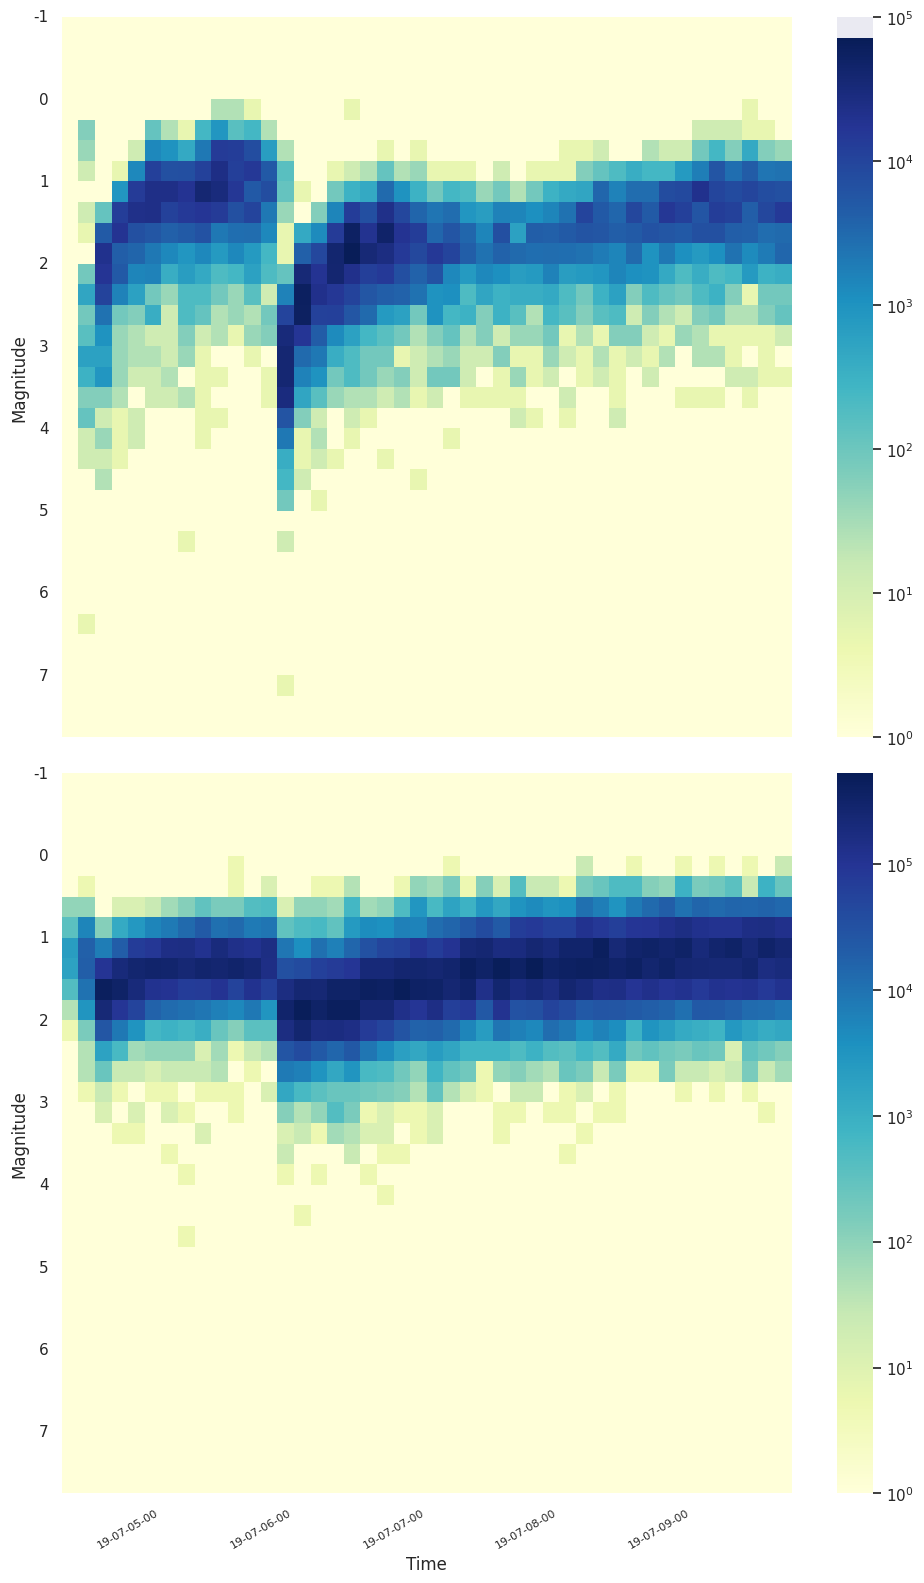

In [34]:
# 假设df1和df2是两个DataFrame，每个DataFrame都有'time'和'magnitude'两列
labels = ['SCSN', 'Prediction']
# 创建两个子图
fig, axes = plt.subplots(2, 1, figsize=(10, 16))
heats=[]
# 对于每个DataFrame，计算热图数据并绘制热图
for df in [catalog, catalog_pred]:
    df['time_bin'] = pd.cut(df['time'], bins=pd.date_range(start='2019-07-04 00:00:00', end='2019-07-10 00:00:00', freq='3H'), include_lowest=True)
    df['magnitude_bin'] = pd.cut(df['magnitude'], bins=np.arange(-1, 8, 0.25), include_lowest=True)
    heatmap_data = df.groupby(['magnitude_bin', 'time_bin']).size().unstack()
    heats.append(np.log1p(heatmap_data))

# 设置标题和标签
axes[0]=sns.heatmap(heats[0], cmap='YlGnBu', ax=axes[0], label=labels[0], xticklabels=False)
axes[1]=sns.heatmap(heats[1], cmap='YlGnBu', ax=axes[1], label=labels[1])
for ax in axes:
    # colorbar
    cbar = ax.collections[0].colorbar
    cbar.set_ticks([0, 1, 2, 3, 4, 5])
    cbar.set_ticklabels([r'$10^0$', r'$10^{1}$', r'$10^{2}$', r'$10^{3}$', r'$10^{4}$', r'$10^{5}$'])
    ax.set_xlim(left=4, right=len(counts_catalog))
    ax.set_ylabel('Magnitude')
    ax.set_yticks(ticks=np.arange(0, 36, 4))
    ax.set_yticklabels(np.arange(-1, 8, 1))

axes[0].set_xlabel('')
axes[1].set_xlabel('Time')
axes[1].set_xticks(ticks=np.arange(4, len(counts_catalog), 1), labels=[idx[2:] if idx.endswith('00') else '' for idx in counts_catalog.index.strftime('%Y-%m-%d-%H')[4:len(counts_catalog)]],
           rotation=30, fontsize=8)

plt.tight_layout()
plt.show()

/tmp/ipykernel_2200878/4180538066.py:55: UserWarning: Tight layout not applied. tight_layout cannot make axes height small enough to accommodate all axes decorations.
  plt.tight_layout()


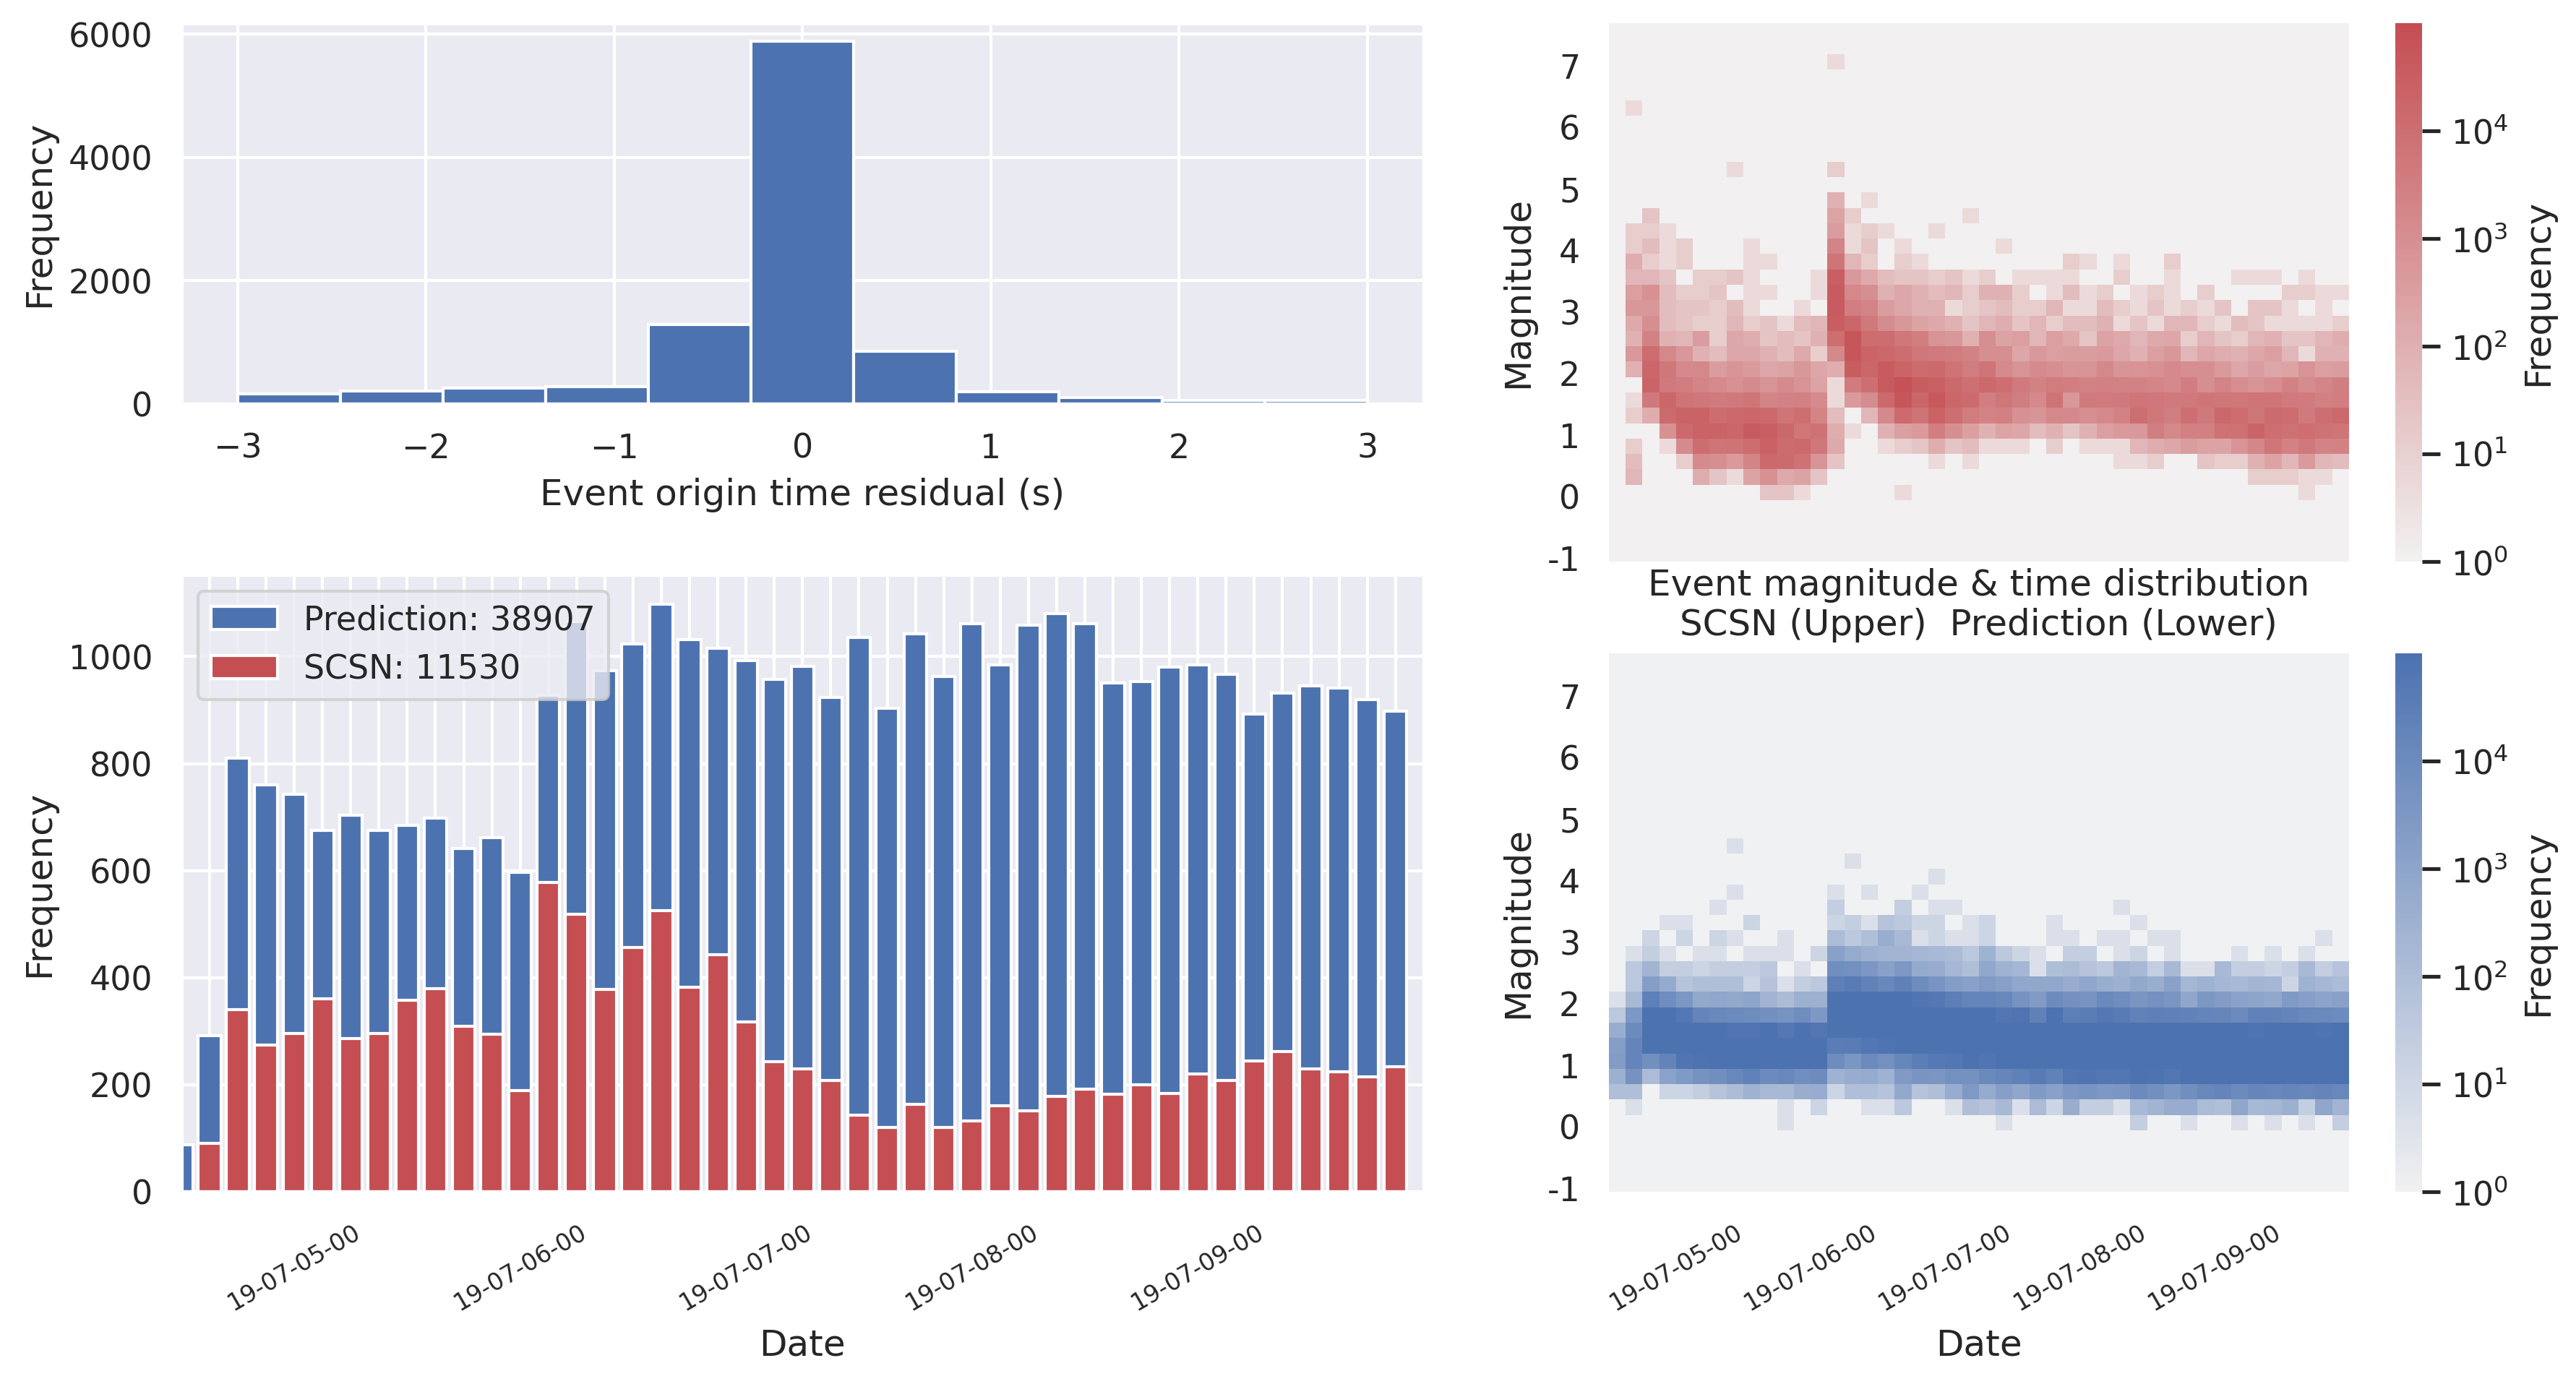

In [35]:
# plot the picks, magnitude and residual of origin time
fig = plt.figure(figsize=(14, 7), dpi=300)
axes=[]
axes.append(plt.subplot2grid((15, 15), (7, 0), colspan=8, rowspan=8))
axes.append(plt.subplot2grid((15, 15), (0, 9), colspan=7, rowspan=7))
axes.append(plt.subplot2grid((15, 15), (8, 9), colspan=7, rowspan=7))
axes.append(plt.subplot2grid((15, 15), (0, 0), colspan=8, rowspan=5))

axes[0].bar(counts_pred.index.strftime('%Y-%m-%d-%H'), counts_pred.values, color='C0', label=f'Prediction: {len(catalog_pred)}')
axes[0].bar(counts_catalog.index.strftime('%Y-%m-%d-%H'), counts_catalog.values, color='C3', label=f'SCSN: {len(catalog)}')
axes[0].set_xlim(left=4, right=len(counts_catalog))
axes[0].set_xticks(ticks=np.arange(4, len(counts_catalog), 1), labels=[idx[2:] if idx.endswith('00') else '' for idx in counts_catalog.index.strftime('%Y-%m-%d-%H')[4:len(counts_catalog)]],
           rotation=30, fontsize=8)
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# axes[1].hist(catalog_pred['magnitude'], bins=26, range=(-0.5, 7), color='C0', label='Prediction', log=True)
# axes[1].hist(catalog['magnitude'], bins=26, range=(-0.5, 7), color='C3', label='SCSN', log=True)
# axes[1].hist(catalog_pred['magnitude'][catalog_pred['magnitude']>=1.81], bins=26, range=(-0.5, 7), color='C0', label='Prediction', log=True)
# 
# axes[1].set_xlabel('Magnitude')
# axes[1].set_ylabel('Frequency')
# axes[1].legend()
# 
# axes[2].hist(res_event_time, bins=11, range=(-3, 3))
# axes[2].set_xlabel('Original Time residual (s)')
# axes[2].set_ylabel('Frequency')
axes[1]=sns.heatmap(heats[0], cmap=sns.light_palette("C3", as_cmap=True), ax=axes[1], label=labels[0], xticklabels=False, vmin=0, vmax=5)
axes[2]=sns.heatmap(heats[1], cmap=sns.light_palette("C0", as_cmap=True), ax=axes[2], label=labels[1], vmin=0, vmax=5)
for i, ax in enumerate(axes[1:3]):
    # colorbar
    cbar = ax.collections[0].colorbar
    cbar.set_ticks([0, 1, 2, 3, 4])
    cbar.set_ticklabels([r'$10^0$', r'$10^{1}$', r'$10^{2}$', r'$10^{3}$', r'$10^{4}$'])
    cbar.set_label(f'Frequency')
    ax.set_xlim(left=4, right=len(counts_catalog))
    ax.set_ylabel('Magnitude')
    ax.set_yticks(ticks=np.arange(0, 36, 4))
    ax.set_yticklabels(np.arange(-1, 8, 1))
    #reverse the y axis
    ax.set_ylim(ax.get_ylim()[::-1])

axes[2].set_title('Event magnitude & time distribution\nSCSN (Upper)  Prediction (Lower)', y=1.00)
axes[1].set_xlabel('')
axes[2].set_xlabel('Date')
axes[2].set_xticks(ticks=np.arange(4, len(counts_catalog), 1), labels=[idx[2:] if idx.endswith('00') else '' for idx in counts_catalog.index.strftime('%Y-%m-%d-%H')[4:len(counts_catalog)]],
           rotation=30, fontsize=8)
#axes[2].set_title('Prediction')

axes[3].hist(res_event_time, bins=11, range=(-3, 3))
axes[3].set_xlabel('Event origin time residual (s)')
axes[3].set_ylabel('Frequency')
#axes[3].legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), ncol=1, fancybox=True, labels=['Prediction', 'SCSN'])
plt.tight_layout()
plt.show()

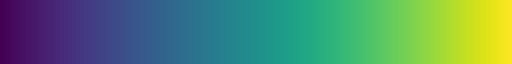

In [ ]:
sns.color_palette("viridis", as_cmap=True)

# NC2020 test dataset predictions

## case study

In [20]:
h5_file = "/home/wanghy/tests/quakeflow_nc/data/NC2020.h5"

In [21]:
nc2020 = h5py.File(h5_file, "r")
nc2020.keys()

<KeysViewHDF5 ['nc71111584', 'nc71111589', 'nc71111594', 'nc71111599', 'nc71111679', 'nc71111684', 'nc71111689', 'nc71111694', 'nc71111699', 'nc71111704', 'nc71111709', 'nc71111714', 'nc71111774', 'nc71111779', 'nc71111874', 'nc71111879', 'nc71111894', 'nc71111899', 'nc71111909', 'nc71111914', 'nc71111919', 'nc71111924', 'nc71111929', 'nc71111934', 'nc71111939', 'nc71111944', 'nc71111974', 'nc71111984', 'nc71111989', 'nc71111999', 'nc71112014', 'nc71112024', 'nc71112029', 'nc71112039', 'nc71112044', 'nc71112049', 'nc71112054', 'nc71112064', 'nc71112069', 'nc71112074', 'nc71112084', 'nc71112089', 'nc71112094', 'nc71112099', 'nc71112104', 'nc71112109', 'nc71112114', 'nc71112119', 'nc71112124', 'nc71112129', 'nc71112134', 'nc71112144', 'nc71112149', 'nc71112154', 'nc71112159', 'nc71112164', 'nc71112169', 'nc71112184', 'nc71112189', 'nc71112194', 'nc71112199', 'nc71112209', 'nc71112214', 'nc71112224', 'nc71112229', 'nc71112234', 'nc71112239', 'nc71112244', 'nc71112249', 'nc71112254', 'nc71

In [22]:
nc2020["nc71111584"].keys()

<KeysViewHDF5 ['NC.MCB..HH', 'NC.MCB..HN']>

In [23]:
event_1 = nc2020["nc71111584"]
station_ids_1 = list(event_1.keys())

In [ ]:
from scipy.interpolate import interp1d
# 暂时取消sns的样式
sns.set_theme(style="ticks")
interval_data = 0.3
start_nt = 1000
end_nt = 5192
tick_t = 1000
models = ["No padding", "Zero padding", "Duplicate padding"]
p_picks = np.zeros((len(models), len(station_ids_1), 8192))
s_picks = np.zeros((len(models), len(station_ids_1), 8192))
event_picks = np.zeros((len(models), len(station_ids_1), 512))

# Interpolate event_picks to 8192
event_picks= event_picks.reshape((len(models)*len(station_ids_1), 512))
event_picks_interpolated = np.zeros((len(models)*len(station_ids_1), 8192))
for i in range(len(models)*len(station_ids_1)):
    f = interp1d(np.arange(512), event_picks[i, :], kind='linear')
    event_picks_interpolated[i, :] = f(np.linspace(0, 511, 8192))

event_picks_interpolated = event_picks_interpolated.reshape((len(models), len(station_ids_1), 8192))


In [ ]:
event_loc_1 = [event_1.attrs["longitude"], event_1.attrs["latitude"], event_1.attrs["depth_km"]]
station_locs_1 = np.array([(event_1[station_id].attrs["longitude"], event_1[station_id].attrs["latitude"], -event_1[station_id].attrs["elevation_m"]/1000) for station_id in station_ids_1])

event_pred_1 = np.random.randn(len(models), len(station_ids_1), 3)/10+event_loc_1

In [ ]:
xlim = round(event_pred_1[:,:,0].min()-0.1, 1), round(event_pred_1[:,:,0].max()+0.1, 1)
ylim = round(event_pred_1[:,:,1].min()-0.1, 1), round(event_pred_1[:,:,1].max()+0.1, 1)
zlim = round(event_pred_1[:,:,2].min()-0.3, 1), round(event_pred_1[:,:,2].max()+0.3, 1)

xlim = round(min(xlim[0], station_locs_1[:,0].min())-0.1, 1), round(max(xlim[1], station_locs_1[:,0].max())+0.1, 1)
ylim = round(min(ylim[0], station_locs_1[:,1].min())-0.1, 1), round(max(ylim[1], station_locs_1[:,1].max())+0.1, 1)
zlim = round(min(zlim[0], station_locs_1[:,2].min())-0.3, 1), round(max(zlim[1], station_locs_1[:,2].max())+0.3, 1)

In [41]:
def case_study_picking(events, station_ids_lists, models, start_nt, end_nt, tick_t, interval_data, p_picks, s_picks, event_picks, legend=True):
    sns.set_theme(style="ticks")
    # Create a figure with three subplots
    fig, axes = plt.subplots(len(station_ids_lists[0]), len(models), figsize=(5*len(models), 3*len(station_ids_lists[0])), dpi=300)
    if len(station_ids_lists[0])==1:
        axes = np.array([axes])
    if len(models)==1:
        axes = axes[:, np.newaxis]

    for icol, (event, station_ids) in enumerate(zip(events, station_ids_lists)):
        for i, station_id in enumerate(station_ids):
            sta = event[station_id]
            data = sta[()][:, :end_nt]
            data -= data.mean()
            data /= max(data.max(), abs(data.min()))

            if len(sta.attrs["component"])>1:
                for j, ch in enumerate(sta.attrs["component"]):
                    axes[i, icol].plot(data[j,:]+(j+0.7)*interval_data, color="C7", alpha=0.8)
                    if icol == 0:
                        axes[i, icol].text(end_nt-300, (j+0.7)*interval_data, ch, fontsize=16)
                    axes[i, icol].text(start_nt+300, 0.12+3.2*interval_data, f"{station_id}", fontsize=16)
                    axes[i, icol].text(start_nt+300, 0.3+3.2*interval_data, f"{sta.attrs['distance_km']:.2f} km", fontsize=16)
            else:
                axes[i, icol].plot(data[2,:]+(0+0.7)*interval_data, color="C7", alpha=0.8)
                if icol == 0:
                    axes[i, icol].text(end_nt-300, 0.7*interval_data, sta.attrs["component"][0], fontsize=16)
                axes[i, icol].text(start_nt+300, 0.12+3.2*interval_data, f"{station_id}", fontsize=16)
                axes[i, icol].text(start_nt+300, 0.3+3.2*interval_data, f"{sta.attrs['distance_km']:.2f} km", fontsize=16)

            for j, (arrival, type) in enumerate(zip(sta.attrs["phase_index"], sta.attrs["phase_type"])):
                if type == "P":
                    axes[i, icol].vlines(arrival, 0.3*interval_data, 3.3*interval_data, color="C3", linewidth=3, label="P pick label")
                elif type == "S":
                    axes[i, icol].vlines(arrival, 0.3*interval_data, 3.3*interval_data, color="C0", linewidth=3, label="S pick label")

            for j, event_id in enumerate(set(sta.attrs["event_id"])): # set去重
                p_arrival = sta.attrs["phase_index"][np.logical_and(sta.attrs["event_id"]==event_id, sta.attrs["phase_type"]=="P")]
                s_arrival = sta.attrs["phase_index"][np.logical_and(sta.attrs["event_id"]==event_id, sta.attrs["phase_type"]=="S")]
                if len(p_arrival) > 0:
                    axes[i, icol].vlines((p_arrival+s_arrival)/2, 0.3*interval_data, 3.3*interval_data, color="C2", linewidth=2, label='Event pick label')

            axes[i, icol].plot(p_picks[icol, i]+0.1, color="red", linewidth=2, label='P probability')
            axes[i, icol].plot(s_picks[icol, i]+0.12, color="blue", linewidth=2, label='S probability')
            axes[i, icol].plot(event_picks[icol, i]+0.14, color="green", linewidth=2, label='Event probability')
    
            axes[i, icol].set_xlim(start_nt, end_nt)
            axes[i, icol].set_xticks([])
            axes[i, icol].set_ylim(0, 4.5*interval_data)
            axes[i, icol].set_yticks([])
            if i==0:
                axes[i, icol].set_title(models[icol], fontsize=16)

        axes[len(station_ids)-1, icol].set_xticks(ticks=np.arange(start_nt, end_nt, tick_t), labels=np.arange(start_nt, end_nt, tick_t)//100)
        axes[len(station_ids)-1, icol].set_xlabel("Time (s)")
    if legend:
        plt.legend(loc="center right", bbox_to_anchor=(0.25, 0.35), fontsize=12)
    plt.tight_layout()

    # Adjust the spacing between subplots
    plt.subplots_adjust(wspace=0, hspace=0)

    # Show the plot
    plt.show()
    sns.set_theme()
    
    return fig, axes

In [35]:
def case_study_location(event_locs, station_locs_lists, models, xlim, ylim, zlim, event_pred, legend=True):
    sns.set_theme(style="ticks")
    # Create a figure with three subplots
    fig= plt.figure(figsize=(5*len(models), 6), dpi=300)
    axes=[]
    for i in range(len(models)):
        axes.append(plt.subplot2grid((6, 5*len(models)), (0, 5*i), colspan=5, rowspan=4))
        axes.append(plt.subplot2grid((6, 5*len(models)), (4, 5*i), colspan=5, rowspan=2))

    for i, (event_loc, station_locs) in enumerate(zip(event_locs, station_locs_lists)):
        axes[i*2].scatter(event_loc[0], event_loc[1], s=150, marker='*', c='C3', label='Event')
        axes[i*2+1].scatter(event_loc[0], event_loc[2], s=150, marker='*', c='C3', label='Event')

        axes[i*2].scatter(station_locs[:,0], station_locs[:,1], s=75, marker='^', c=np.arange(len(station_locs)), cmap="tab20", label='Stations')
        axes[i*2].scatter(event_pred[i, :, 0], event_pred[i, :, 1], s=75, marker='.', c=np.arange(len(station_locs)), cmap="tab20", label='Prediction')
        axes[i*2].scatter(event_pred[i, :, 0].mean(), event_pred[i, :, 1].mean(), s=100, marker='x', c='C2', label='Prediction mean')
        axes[i*2+1].scatter(station_locs[:,0], station_locs[:,2], s=75, marker='^', c=np.arange(len(station_locs)), cmap="tab20", label='Stations')
        axes[i*2+1].scatter(event_pred[i, :, 0], event_pred[i, :, 2], s=75, marker='.', c=np.arange(len(station_locs)), cmap="tab20", label='Prediction')
        axes[i*2+1].scatter(event_pred[i, :, 0].mean(), event_pred[i, :, 2].mean(), s=100, marker='x', c='C2', label='Prediction mean')
        if i!=0:
            axes[i*2].set_yticks([])
            axes[i*2+1].set_yticks([])
        if i==0:
            axes[i*2].set_ylabel("Latitude")
            axes[i*2+1].set_ylabel("Depth (km)")   
        axes[i*2].set_xlim(xlim)
        axes[i*2+1].set_xlim(xlim)
        axes[i*2].set_ylim(ylim)
        axes[i*2+1].set_ylim(zlim)
        # reverse the y axis
        axes[i*2+1].set_ylim(axes[i*2+1].get_ylim()[::-1])
        #axes[i*2].set_aspect("equal")
        axes[i*2].set_xticks([])
        axes[i*2+1].set_xticks(ticks=np.arange(xlim[0], xlim[1], 0.1))
        axes[i*2+1].set_xticklabels(labels=[round(x, 2) for x in np.arange(xlim[0], xlim[1], 0.1)])
        axes[i*2+1].set_xlabel("Longitude")

    if legend:
        plt.legend(loc="center right", bbox_to_anchor=(1.75, 0.35), fontsize=12)
    plt.tight_layout()
    # Adjust the spacing between subplots
    plt.subplots_adjust(wspace=0, hspace=0.1)
    # Show the plot
    plt.show()
    sns.set_theme()
    return fig, axes

In [47]:
interval_data = 0.4
start_nt = 1500
end_nt = 4692
tick_t = 1000
models = ["No padding", "Zero padding", "Duplicate padding"]
p_picks = np.zeros((len(models), len(station_ids_1), 8192))
s_picks = np.zeros((len(models), len(station_ids_1), 8192))
event_picks = np.zeros((len(models), len(station_ids_1), 512))

event_picks= event_picks.reshape((len(models)*len(station_ids_1), 512))
event_picks_interpolated = np.zeros((len(models)*len(station_ids_1), 8192))
for i in range(len(models)*len(station_ids_1)):
    f = interp1d(np.arange(512), event_picks[i, :], kind='linear')
    event_picks_interpolated[i, :] = f(np.linspace(0, 511, 8192))

event_picks_interpolated = event_picks_interpolated.reshape((len(models), len(station_ids_1), 8192))

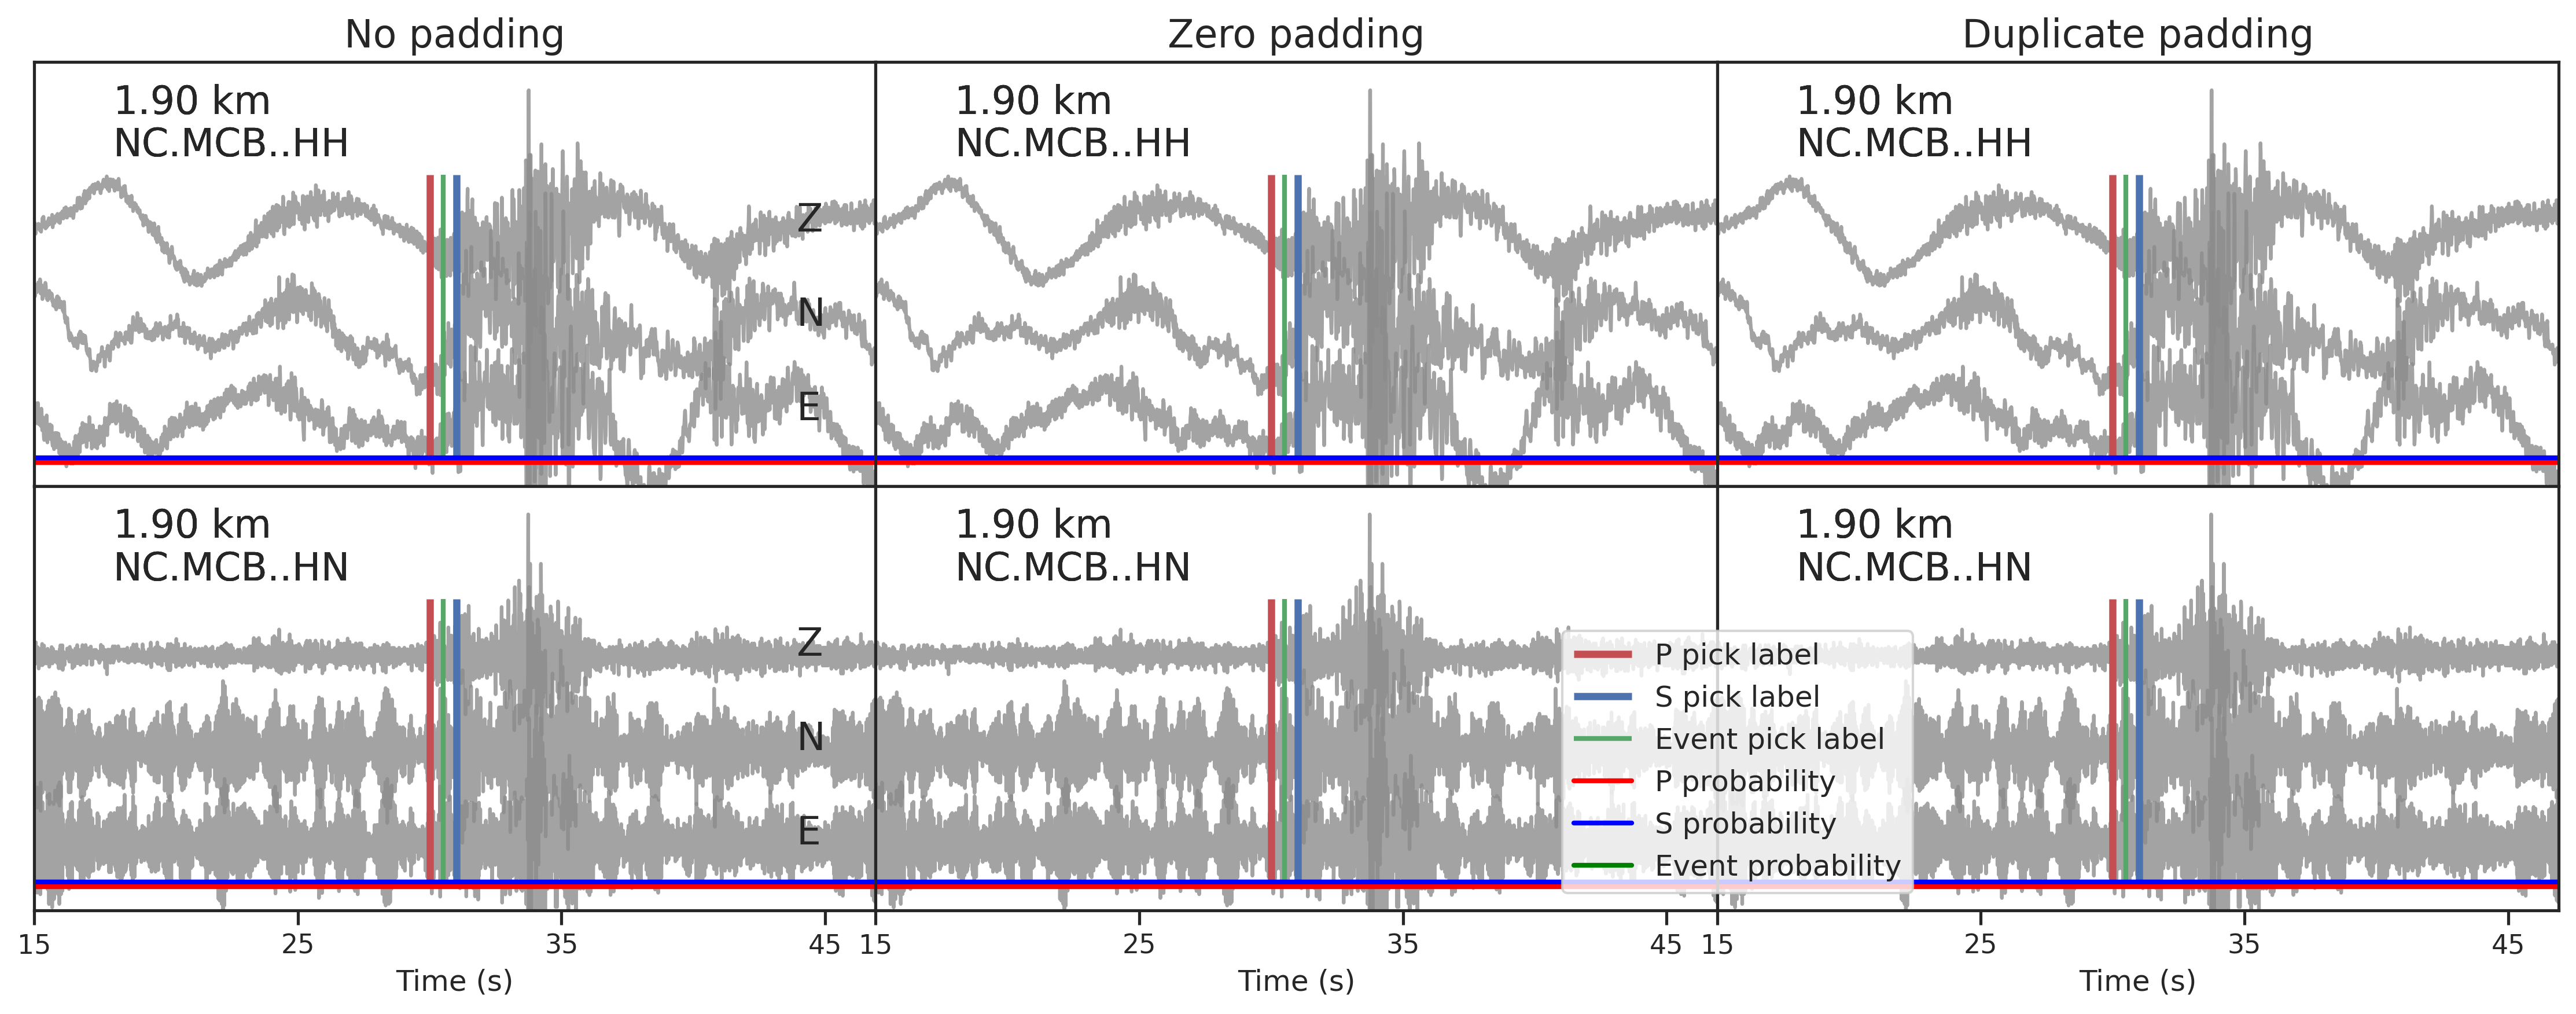

(<Figure size 4500x1800 with 6 Axes>,
 array([[<Axes: title={'center': 'No padding'}>,
         <Axes: title={'center': 'Zero padding'}>,
         <Axes: title={'center': 'Duplicate padding'}>],
        [<Axes: xlabel='Time (s)'>, <Axes: xlabel='Time (s)'>,
         <Axes: xlabel='Time (s)'>]], dtype=object))

In [ ]:
case_study_picking(events=[event_1, event_1, event_1], station_ids_lists=[station_ids_1, station_ids_1, station_ids_1], models=models, start_nt=start_nt, end_nt=end_nt, tick_t=tick_t, interval_data=interval_data, p_picks=p_picks, s_picks=s_picks, event_picks=event_picks)

In [49]:
event_loc_1 = [event_1.attrs["longitude"], event_1.attrs["latitude"], event_1.attrs["depth_km"]]
station_locs_1 = np.array([(event_1[station_id].attrs["longitude"], event_1[station_id].attrs["latitude"], -event_1[station_id].attrs["elevation_m"]/1000) for station_id in station_ids_1])

event_pred_1 = np.random.randn(len(models), len(station_ids_1), 3)/10+event_loc_1

xlim = round(event_pred_1[:,:,0].min()-0.1, 1), round(event_pred_1[:,:,0].max()+0.1, 1)
ylim = round(event_pred_1[:,:,1].min()-0.1, 1), round(event_pred_1[:,:,1].max()+0.1, 1)
zlim = round(event_pred_1[:,:,2].min()-0.3, 1), round(event_pred_1[:,:,2].max()+0.3, 1)

xlim = round(min(xlim[0], station_locs_1[:,0].min())-0.1, 1), round(max(xlim[1], station_locs_1[:,0].max())+0.1, 1)
ylim = round(min(ylim[0], station_locs_1[:,1].min())-0.1, 1), round(max(ylim[1], station_locs_1[:,1].max())+0.1, 1)
zlim = round(min(zlim[0], station_locs_1[:,2].min())-0.3, 1), round(max(zlim[1], station_locs_1[:,2].max())+0.3, 1)

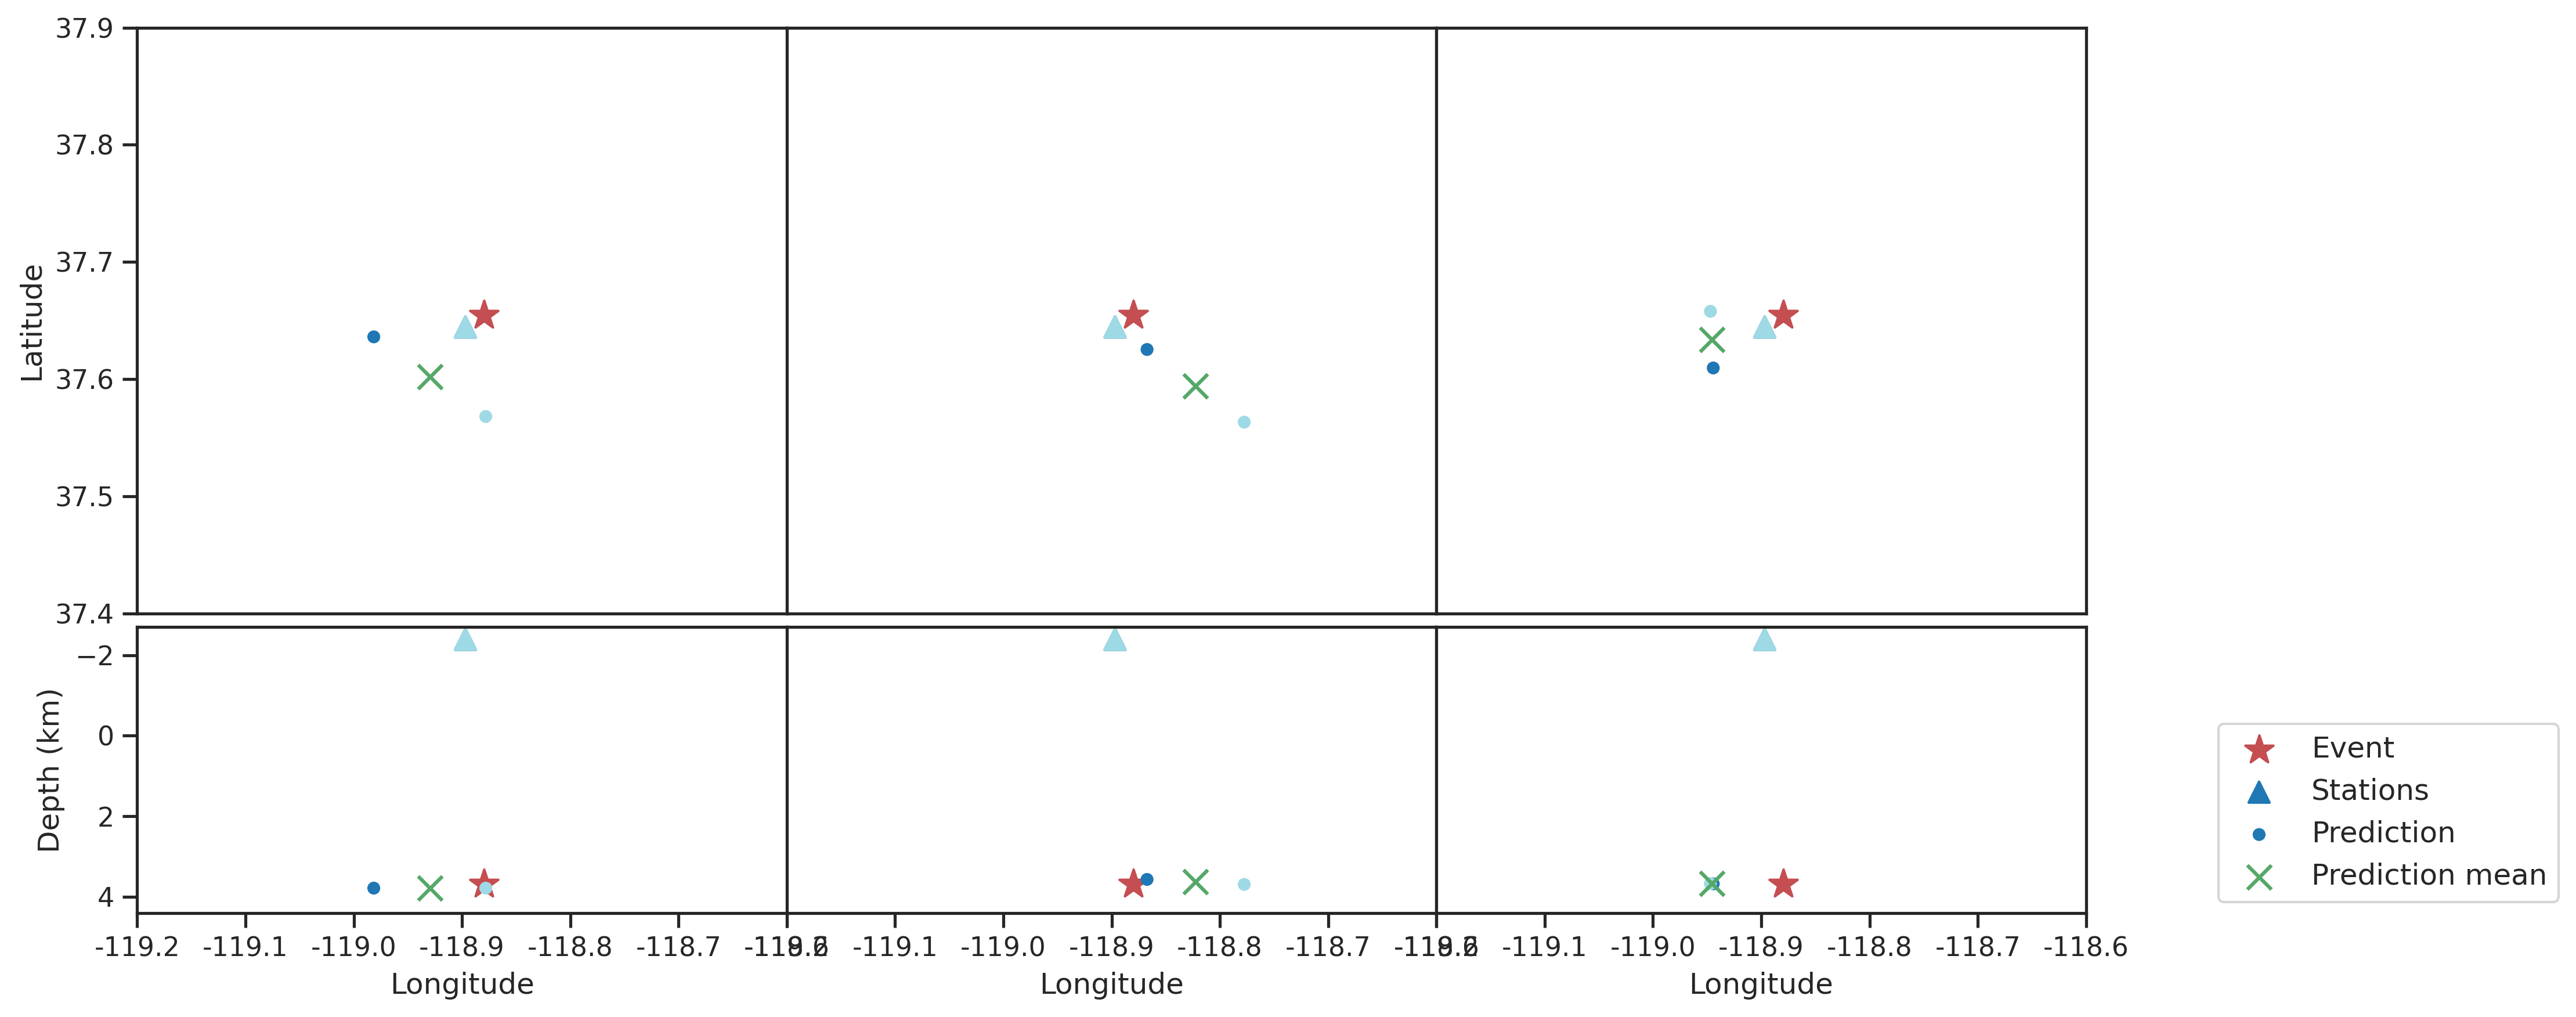

(<Figure size 4500x1800 with 6 Axes>,
 [<Axes: ylabel='Latitude'>,
  <Axes: xlabel='Longitude', ylabel='Depth (km)'>,
  <Axes: >,
  <Axes: xlabel='Longitude'>,
  <Axes: >,
  <Axes: xlabel='Longitude'>])

In [50]:
case_study_location(event_locs=[event_loc_1]*3, station_locs_lists=[station_locs_1]*3, models=models, xlim=xlim, ylim=ylim, zlim=zlim, event_pred=event_pred_1)

In [27]:
selected_events = os.listdir("/home/wanghy/tests/EQNet/test_eqnet_plot_0/cases")
selected_events = sorted([selected_event[10:20] for selected_event in selected_events])
selected_events

['nc71111584',
 'nc71111594',
 'nc71111599',
 'nc71111679',
 'nc71111689',
 'nc71111694',
 'nc71111699',
 'nc71111709',
 'nc71111714',
 'nc71111774',
 'nc71111779',
 'nc71111874',
 'nc71111879',
 'nc71111894',
 'nc71111899']

In [ ]:
# 读取selected_events的数据
def extract_stations(h5file_path: str, output: str, selected_events: list):
    with h5py.File(h5file_path, "r") as fp_in, h5py.File(output, "w") as fp_out:
        for event_id in tqdm(selected_events):
            event = fp_in[event_id]
            fp_in.copy(event, fp_out)


In [ ]:
nc2020.close()
extract_stations(h5file_path=h5_file, output="/home/wanghy/tests/quakeflow_nc/data/case_study.h5", selected_events=selected_events)
nc2020 = h5py.File(h5_file, "r")

  0%|          | 0/15 [00:00<?, ?it/s]

In [28]:
case_study = h5py.File("/home/wanghy/tests/quakeflow_nc/data/case_study.h5", "r")
case_study.keys()

<KeysViewHDF5 ['nc71111584', 'nc71111594', 'nc71111599', 'nc71111679', 'nc71111689', 'nc71111694', 'nc71111699', 'nc71111709', 'nc71111714', 'nc71111774', 'nc71111779', 'nc71111874', 'nc71111879', 'nc71111894', 'nc71111899']>

In [ ]:
!torchrun --standalone /home/wanghy/tests/EQNet/predict.py --model eqnet --backbone=swin2 --head=upernet --batch_size=1 --dataset seismic_network --use-station-location --hdf5-file /home/wanghy/tests/quakeflow_nc/data/case_study.h5 --result_path test_eqnet_case_study --resume /home/wanghy/tests/EQNet/result_eqnet_test_magnitude/model_16.pth --is_pad --save_score --sort=False > test_predict_case.txt 2>&1


In [30]:
pick_score = torch.load('/home/wanghy/tests/EQNet/tests/eqnet/test_eqnet_case_study/picks_eqnet/nc71111584_score.pt').to('cpu')
event_score = torch.load('/home/wanghy/tests/EQNet/tests/eqnet/test_eqnet_case_study/events_eqnet/nc71111584_score.pt').to('cpu')
pick_score, event_score

(tensor([[[1.0000e+00, 1.0000e+00],
          [1.0000e+00, 1.0000e+00],
          [1.0000e+00, 1.0000e+00],
          ...,
          [1.0000e+00, 1.0000e+00],
          [1.0000e+00, 1.0000e+00],
          [1.0000e+00, 1.0000e+00]],
 
         [[2.0044e-12, 1.1967e-12],
          [1.7670e-12, 1.1060e-12],
          [1.3073e-12, 8.5357e-13],
          ...,
          [1.5748e-19, 1.2091e-19],
          [2.2660e-19, 1.7420e-19],
          [2.7384e-19, 2.1063e-19]],
 
         [[1.5736e-10, 8.3933e-11],
          [1.3074e-10, 7.0334e-11],
          [9.1119e-11, 4.9296e-11],
          ...,
          [1.7744e-15, 1.3966e-15],
          [2.3938e-15, 1.8901e-15],
          [2.7398e-15, 2.1659e-15]]]),
 tensor([[6.5000e-02, 9.2208e-02],
         [3.2951e-02, 4.3516e-02],
         [1.2354e-02, 1.5912e-02],
         ...,
         [4.6816e-07, 4.1545e-07],
         [1.2391e-06, 1.1135e-06],
         [2.0304e-06, 1.8306e-06]]))

/tmp/ipykernel_3539895/601417469.py:58: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


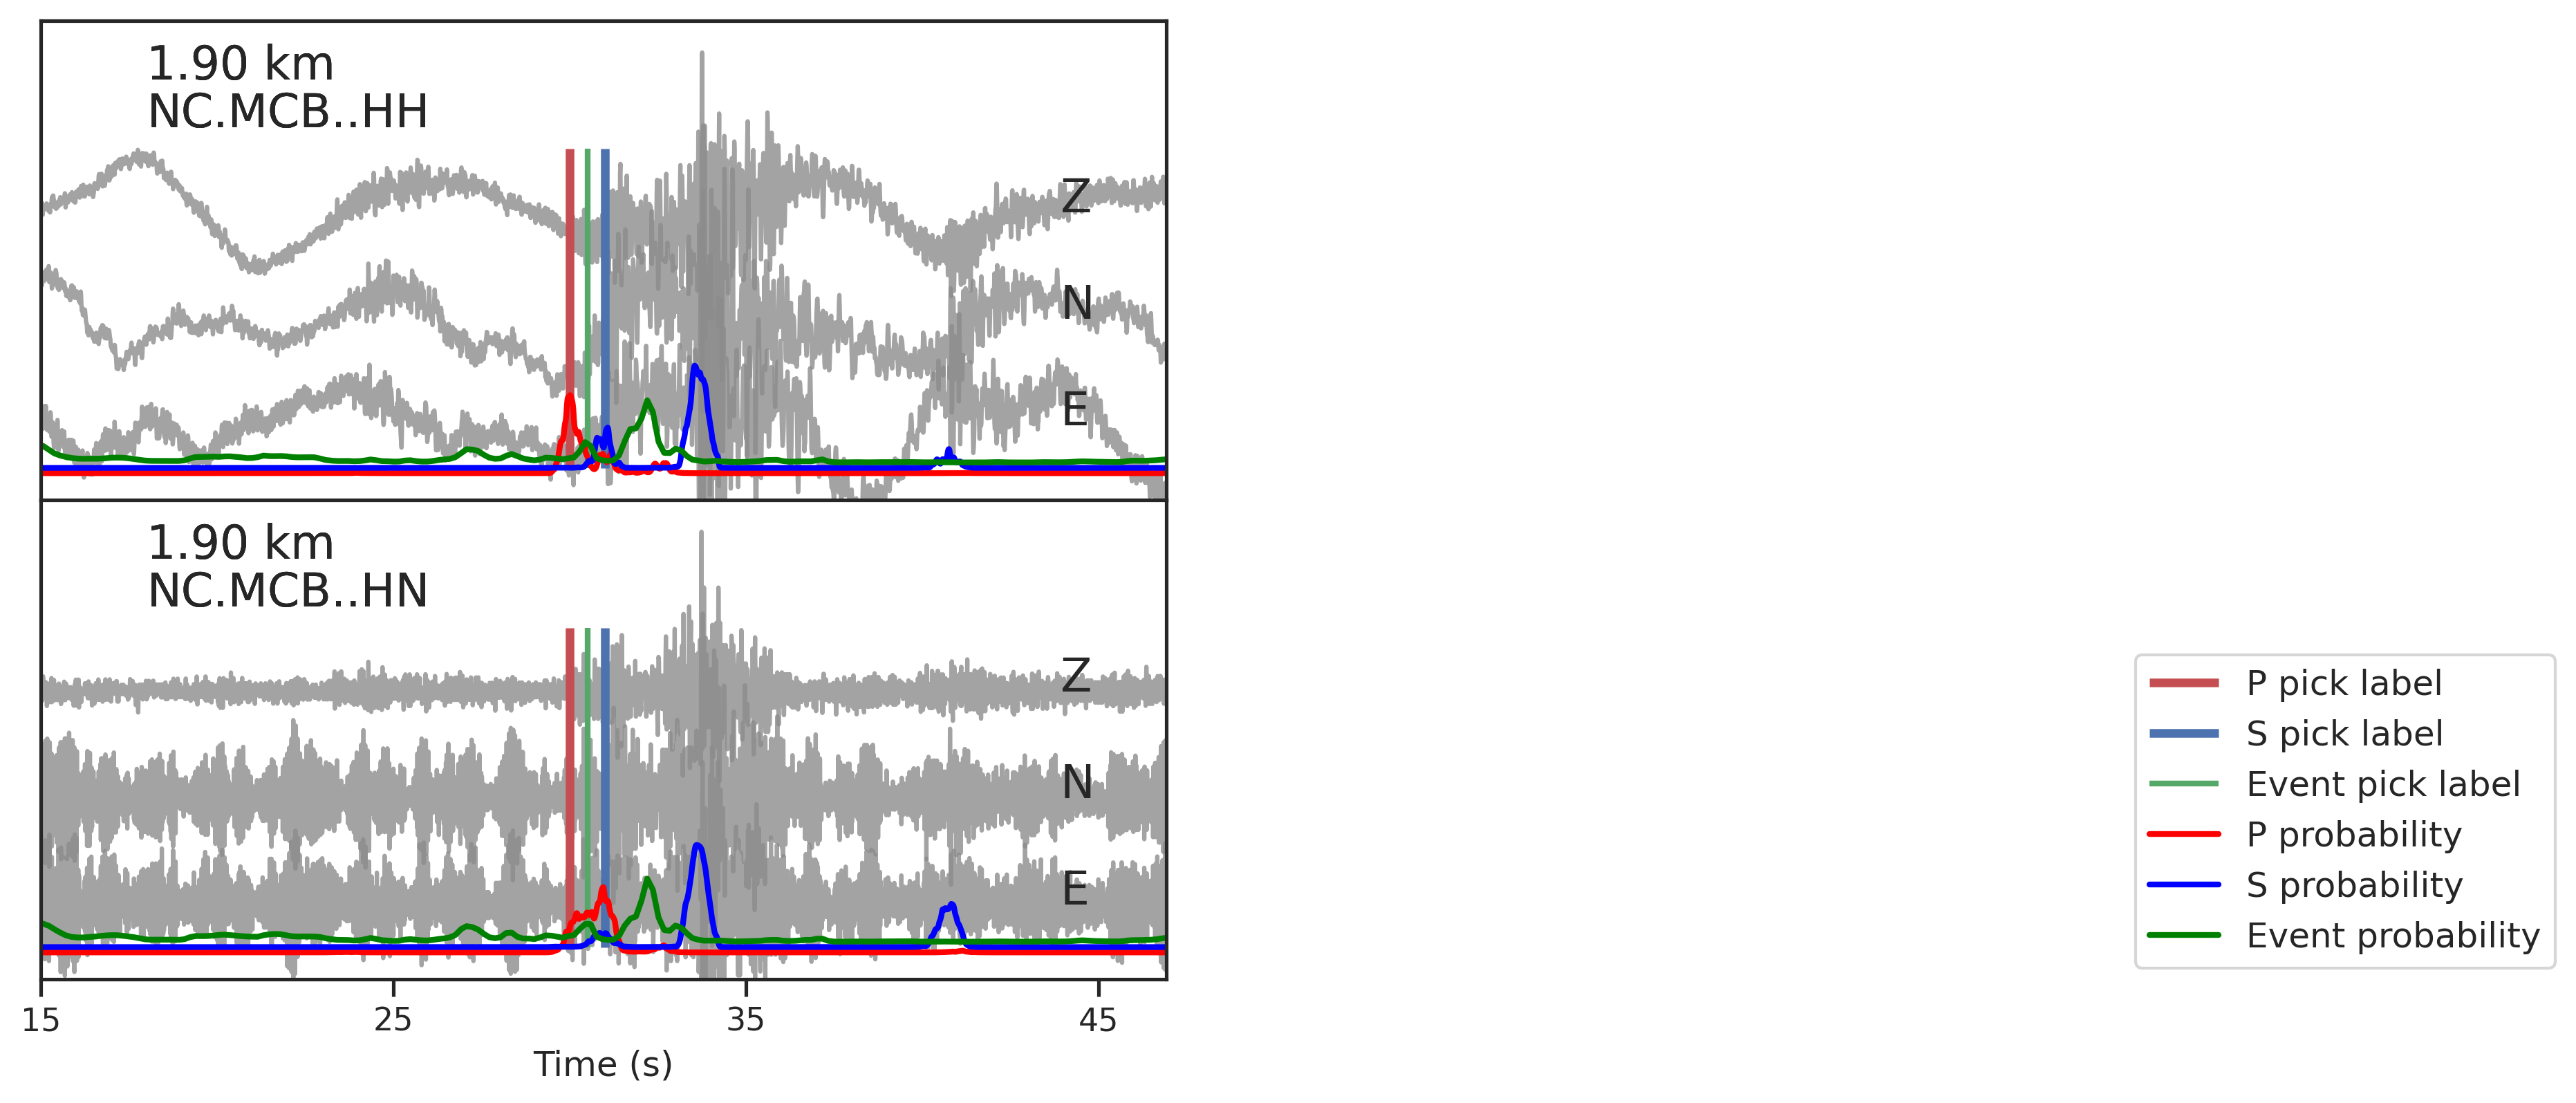

(<Figure size 2100x1800 with 2 Axes>,
 array([[<Axes: >],
        [<Axes: xlabel='Time (s)'>]], dtype=object))

In [40]:
interval_data = 0.4
start_nt = 1500
end_nt = 4692
tick_t = 1000
models = ['']
p_picks = pick_score[1:2].numpy().transpose(0, 2, 1)
s_picks = pick_score[2:3].numpy().transpose(0, 2, 1)
event_picks = event_score[None,:,:].numpy().transpose(0, 2, 1)
event_case = nc2020[selected_events[0]]
station_ids_case = list(event_case.keys())

event_picks= event_picks.reshape((len(models)*len(station_ids_case), event_picks.shape[-1]))
event_picks_interpolated = np.zeros((len(models)*len(station_ids_case), p_picks.shape[-1]))
for i in range(len(models)*len(station_ids_case)):
    f = interp1d(np.arange(event_picks.shape[-1]), event_picks[i, :], kind='linear')
    event_picks_interpolated[i, :] = f(np.linspace(0, event_picks.shape[-1]-1, p_picks.shape[-1]))

event_picks_interpolated = event_picks_interpolated.reshape((len(models), len(station_ids_case), p_picks.shape[-1]))

case_study_picking(events=[event_case], station_ids_lists=[station_ids_case], models=[""], start_nt=start_nt, end_nt=end_nt, tick_t=tick_t, interval_data=interval_data, p_picks=p_picks/2, s_picks=s_picks/2, event_picks=event_picks_interpolated/2, legend=True)

In [ ]:
interval_data = 0.4
start_nt = 1500
end_nt = 4692
tick_t = 1000
for eve in selected_events:
    pick_score = torch.load(f'/home/wanghy/tests/EQNet/tests/eqnet/test_eqnet_case_study/picks_eqnet/{eve}_score.pt').to('cpu')
    event_score = torch.load(f'/home/wanghy/tests/EQNet/tests/eqnet/test_eqnet_case_study/events_eqnet/{eve}_score.pt').to('cpu')
    models = [eve]
    p_picks = pick_score[1:2].numpy().transpose(0, 2, 1)
    s_picks = pick_score[2:3].numpy().transpose(0, 2, 1)
    event_picks = event_score[None,:,:].numpy().transpose(0, 2, 1)
    print(f"{eve}: p peak {p_picks.max()} s peak {s_picks.max()} event peak {event_picks.max()}")
    event_case = nc2020[eve]
    station_ids_case = list(event_case.keys())

    event_picks= event_picks.reshape((len(models)*len(station_ids_case), event_picks.shape[-1]))
    event_picks_interpolated = np.zeros((len(models)*len(station_ids_case), p_picks.shape[-1]))
    for i in range(len(models)*len(station_ids_case)):
        f = interp1d(np.arange(event_picks.shape[-1]), event_picks[i, :], kind='linear')
        event_picks_interpolated[i, :] = f(np.linspace(0, event_picks.shape[-1]-1, p_picks.shape[-1]))

    event_picks_interpolated = event_picks_interpolated.reshape((len(models), len(station_ids_case), p_picks.shape[-1]))

    fig, axes=case_study_picking(events=[event_case], station_ids_lists=[station_ids_case], models=models, start_nt=start_nt, end_nt=end_nt, tick_t=tick_t, interval_data=interval_data, p_picks=p_picks/2, s_picks=s_picks/2, event_picks=event_picks_interpolated/2, legend=False)
    fig.savefig(f'/home/wanghy/tests/EQNet/tests/eqnet/test_eqnet_case_study/figures_eqnet/{eve}_case.png', dpi=300)

In [15]:
event_metric_case = EventMetric()
case_dir = "/home/wanghy/tests/EQNet/tests/eqnet/test_eqnet_case_study/events_eqnet/"
case_event_picks = [os.path.join(case_dir, f) for f in os.listdir(case_dir) if f.endswith(".csv")]
dbscan = DBSCAN(eps=dbscan_epsilon, min_samples=1)

catalog_case = []

with h5py.File(h5_file, "r") as fp:
    for pick in tqdm(case_event_picks):
        event_id = re.sub(r'\.csv$', '', os.path.basename(pick))
        event = fp[event_id]
        num_stations = len(list(event.keys()))
        event_metric_case.num_event_picks_label += 1

        # skip the empty pick file
        if os.path.getsize(pick) == 0:
            event_metric_case.empty_files += 1
            event_metric_case.update_matched_picks(0, 0, 0, 0, 0, 0, 0, 0, 0)
            event_dict = {"event_id": event_id, "num_stations": num_stations, "origin_time": 0, 
                      "longitude": 0, "latitude": 0, "depth_km": 0, "magnitude": 0, "num_picks": 0}
            catalog_case.append(pd.DataFrame(event_dict, index=[0]))
            continue
        df = pd.read_csv(pick)
        assert 'event_center_index' in df.columns, f'event_center_index not in {event_id}.columns'
        assert 'p_index' in df.columns, f'p_index not in {event_id}.columns'
        assert 's_index' in df.columns, f's_index not in {event_id}.columns'
        assert 'event_original_time' in df.columns, f'event_original_time not in {event_id}.columns'
        
        stations = df["station_id"].values
        time_stamps = pd.to_datetime(df["event_original_time"])
        hypoparameters = np.zeros((len(df),8))
        hypoparameters[:,0] = df["event_index"].values
        hypoparameters[:,1] = df["event_location_x"].values
        hypoparameters[:,2] = df["event_location_y"].values
        hypoparameters[:,3] = df["event_location_z"].values
        hypoparameters[:,4] = df["event_longitude"].values
        hypoparameters[:,5] = df["event_latitude"].values
        hypoparameters[:,6] = df["epicentral_distance"].values
        hypoparameters[:,7] = df["magnitude"].values
        
        labels = dbscan.fit_predict(hypoparameters[:,:4]*np.array(time_space_weight)[None,:]) # weighted
        classes, counts = np.unique(labels, return_counts=True)
        if event.attrs["num_stations"] > 5 and len(classes) > 1:
            if classes[0] == -1:
                classes = classes[1:]
                counts = counts[1:]
            classes = classes[counts>1]
            
        event_metric_case.num_event_picks += len(classes)
        min_time_diff = np.inf
        x_diff = np.inf
        y_diff = np.inf
        z_diff = np.inf
        magnitude_pr = np.inf
        x_pred = np.inf
        y_pred = np.inf
        z_pred = np.inf
        lon_pred = np.inf
        lat_pred = np.inf
        origin_time = None
        station_ids = list(event.keys())
        label_x = event.attrs["longitude"]*degree2km*np.cos(np.radians(event.attrs["latitude"]))
        label_y = event.attrs["latitude"]*degree2km
        label_z = event.attrs["depth_km"]
        for c in classes:
            cluster_picks = hypoparameters[labels==c]
            time_stamp = time_stamps[labels==c]
            time_stamp = time_stamp.iloc[np.argsort(cluster_picks[:,6])][:10]
            cluster_picks = cluster_picks[np.argsort(cluster_picks[:,6])][:5]
            time_diff = (np.median(cluster_picks[:,0])*feature_scale - event.attrs["event_time_index"])/sample_rate
            if abs(time_diff) < abs(min_time_diff):
                #avg_center = average_location(cluster_picks[:,4:6])
                avg_center = np.median(cluster_picks[:,4:6], axis=0)
                lon_pred = avg_center[0]
                lat_pred = avg_center[1]
                x_pred = avg_center[0]*np.cos(np.radians(avg_center[1])) * degree2km
                y_pred = avg_center[1] * degree2km
                z_pred = np.median(cluster_picks[:,3])
                x_diff = (x_pred - label_x)
                y_diff = (y_pred - label_y)
                z_diff = (z_pred - label_z)
                magnitude_pr = np.median(cluster_picks[:,7])
                min_time_diff = time_diff
                origin_time = time_stamp.median()
        event_metric_case.update_matched_picks(min_time_diff, x_diff, y_diff, z_diff, x_pred, y_pred, z_pred, event.attrs["magnitude"], magnitude_pr)
        event_dict = {"event_id": event_id, "num_stations": num_stations, "origin_time": origin_time.strftime('%Y-%m-%dT%H:%M:%S.%fZ'), 
                      "longitude": lon_pred, "latitude": lat_pred, "depth_km": z_pred, "magnitude": magnitude_pr, "num_picks": len(classes)}
        catalog_case.append(pd.DataFrame(event_dict, index=[0]))
        
catalog_case = pd.concat(catalog_case, ignore_index=True)
catalog_case.to_csv("/home/wanghy/tests/EQNet/tests/eqnet/test_eqnet_case_study/events_eqnet.csv", index=False)

event_metric_case.list2numpy()

print(f"whole dataset empty files: {event_metric_case.empty_files}")
print(f"whole dataset no match files: {event_metric_case.no_match_files}")


100%|██████████| 15/15 [00:00<00:00, 61.81it/s]

whole dataset empty files: 1
whole dataset no match files: 0


In [61]:
nc2020["nc71111899"].attrs["event_time"]

'2020-02-06T13:24:33.810'

nc71111584


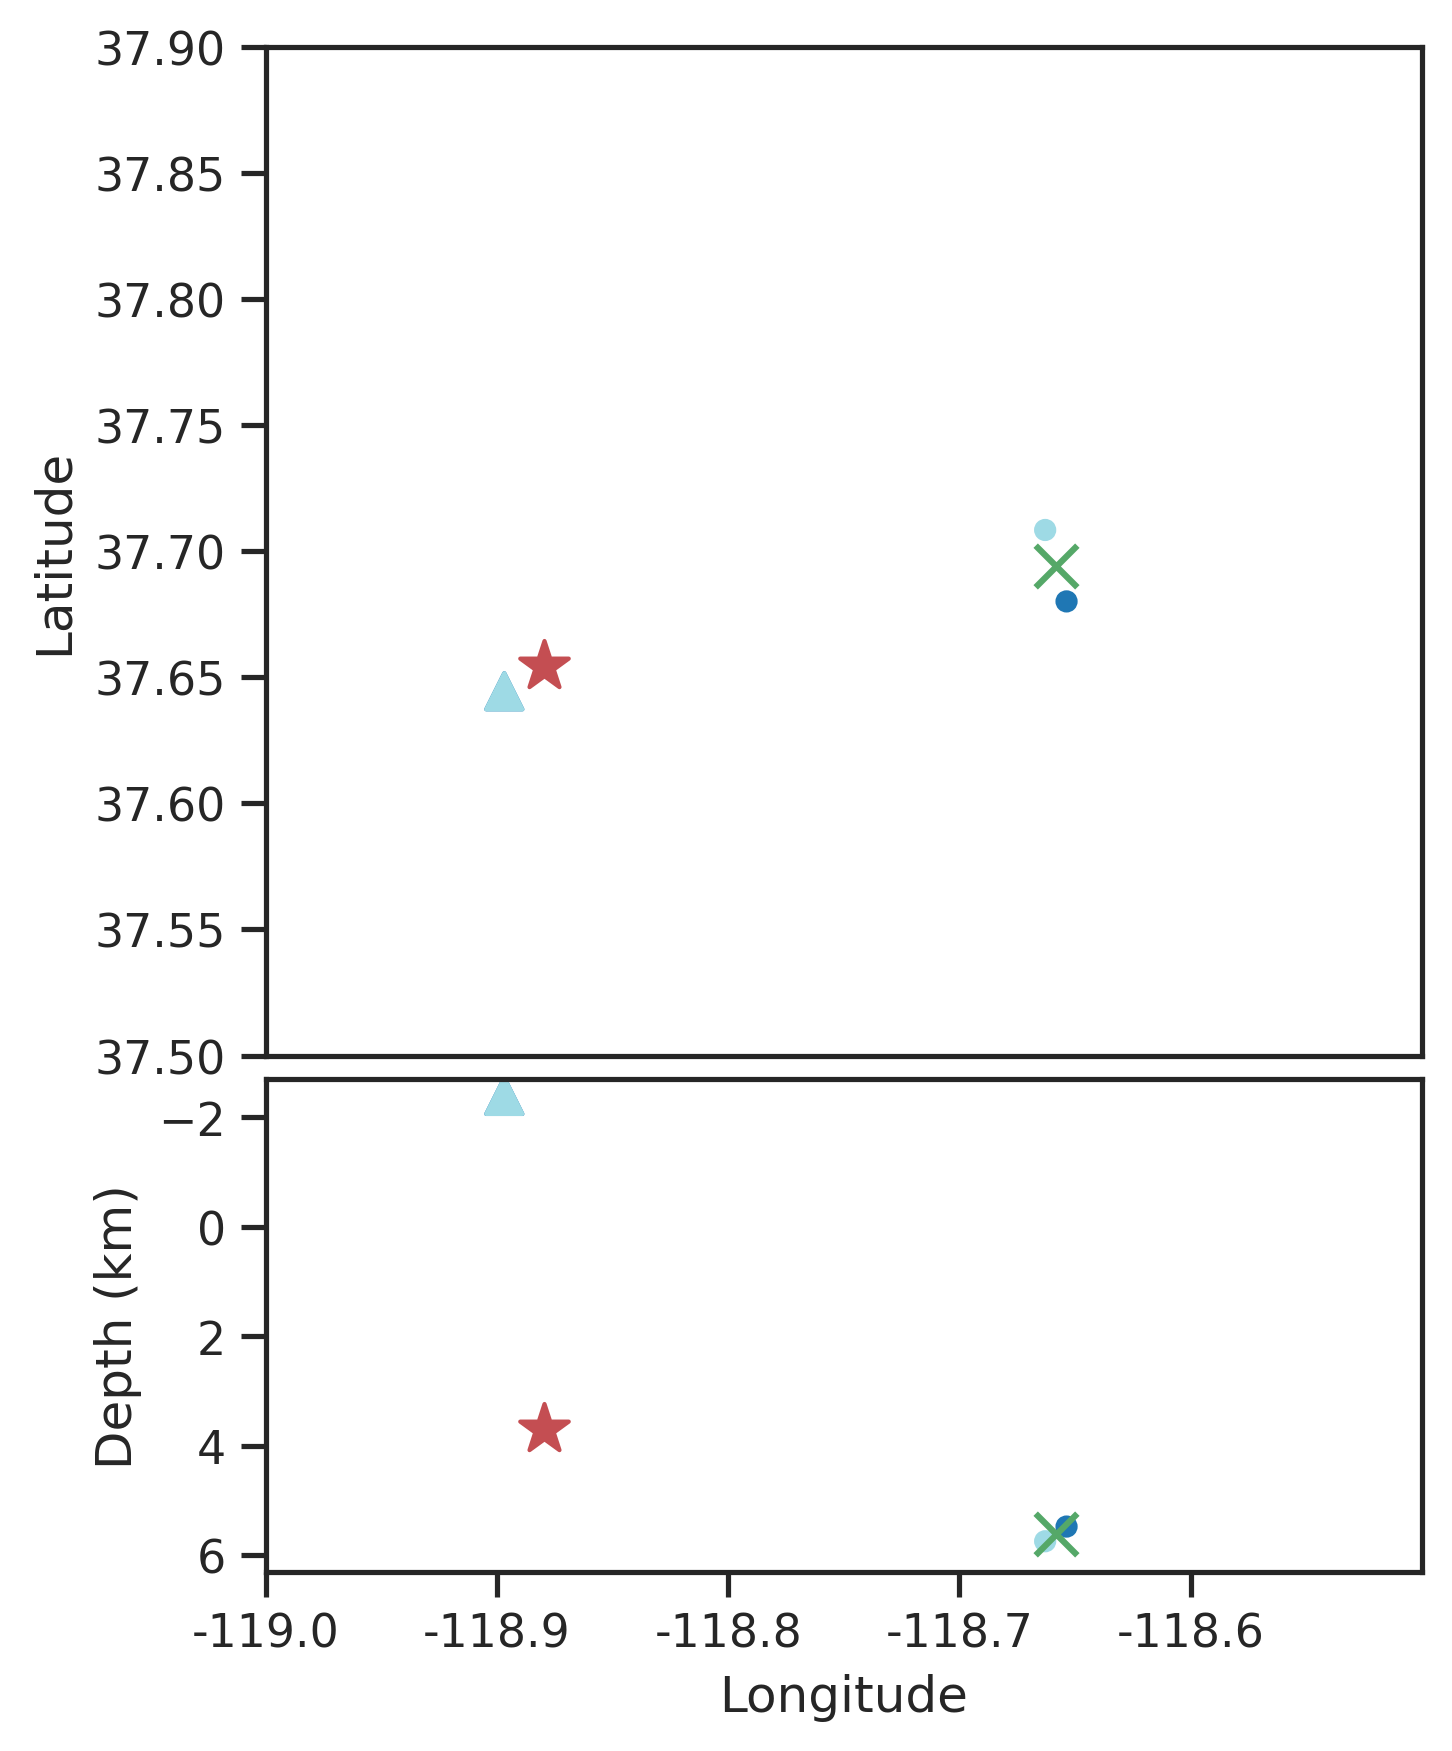

nc71111594


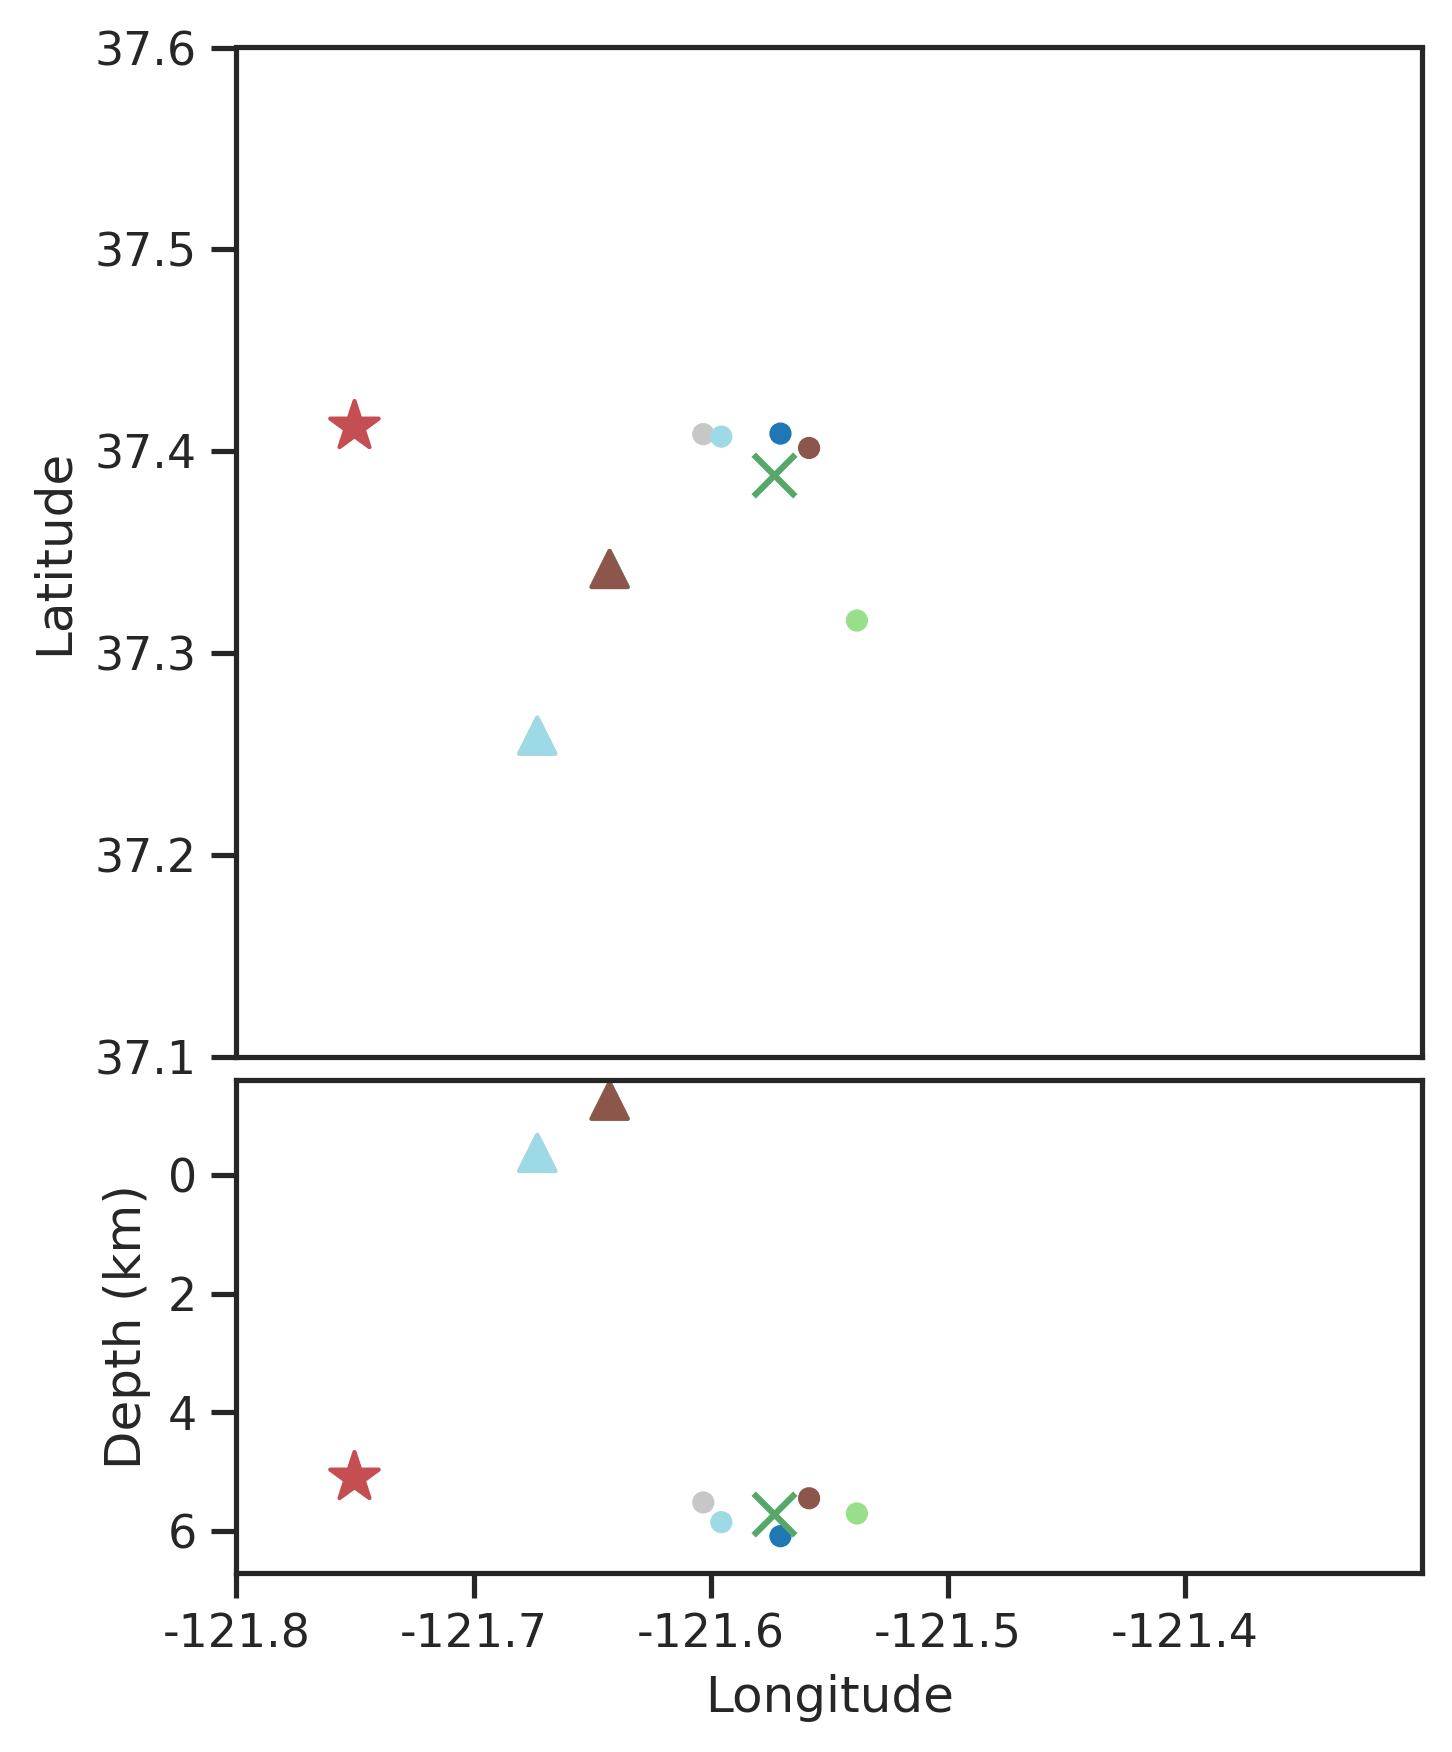

nc71111599


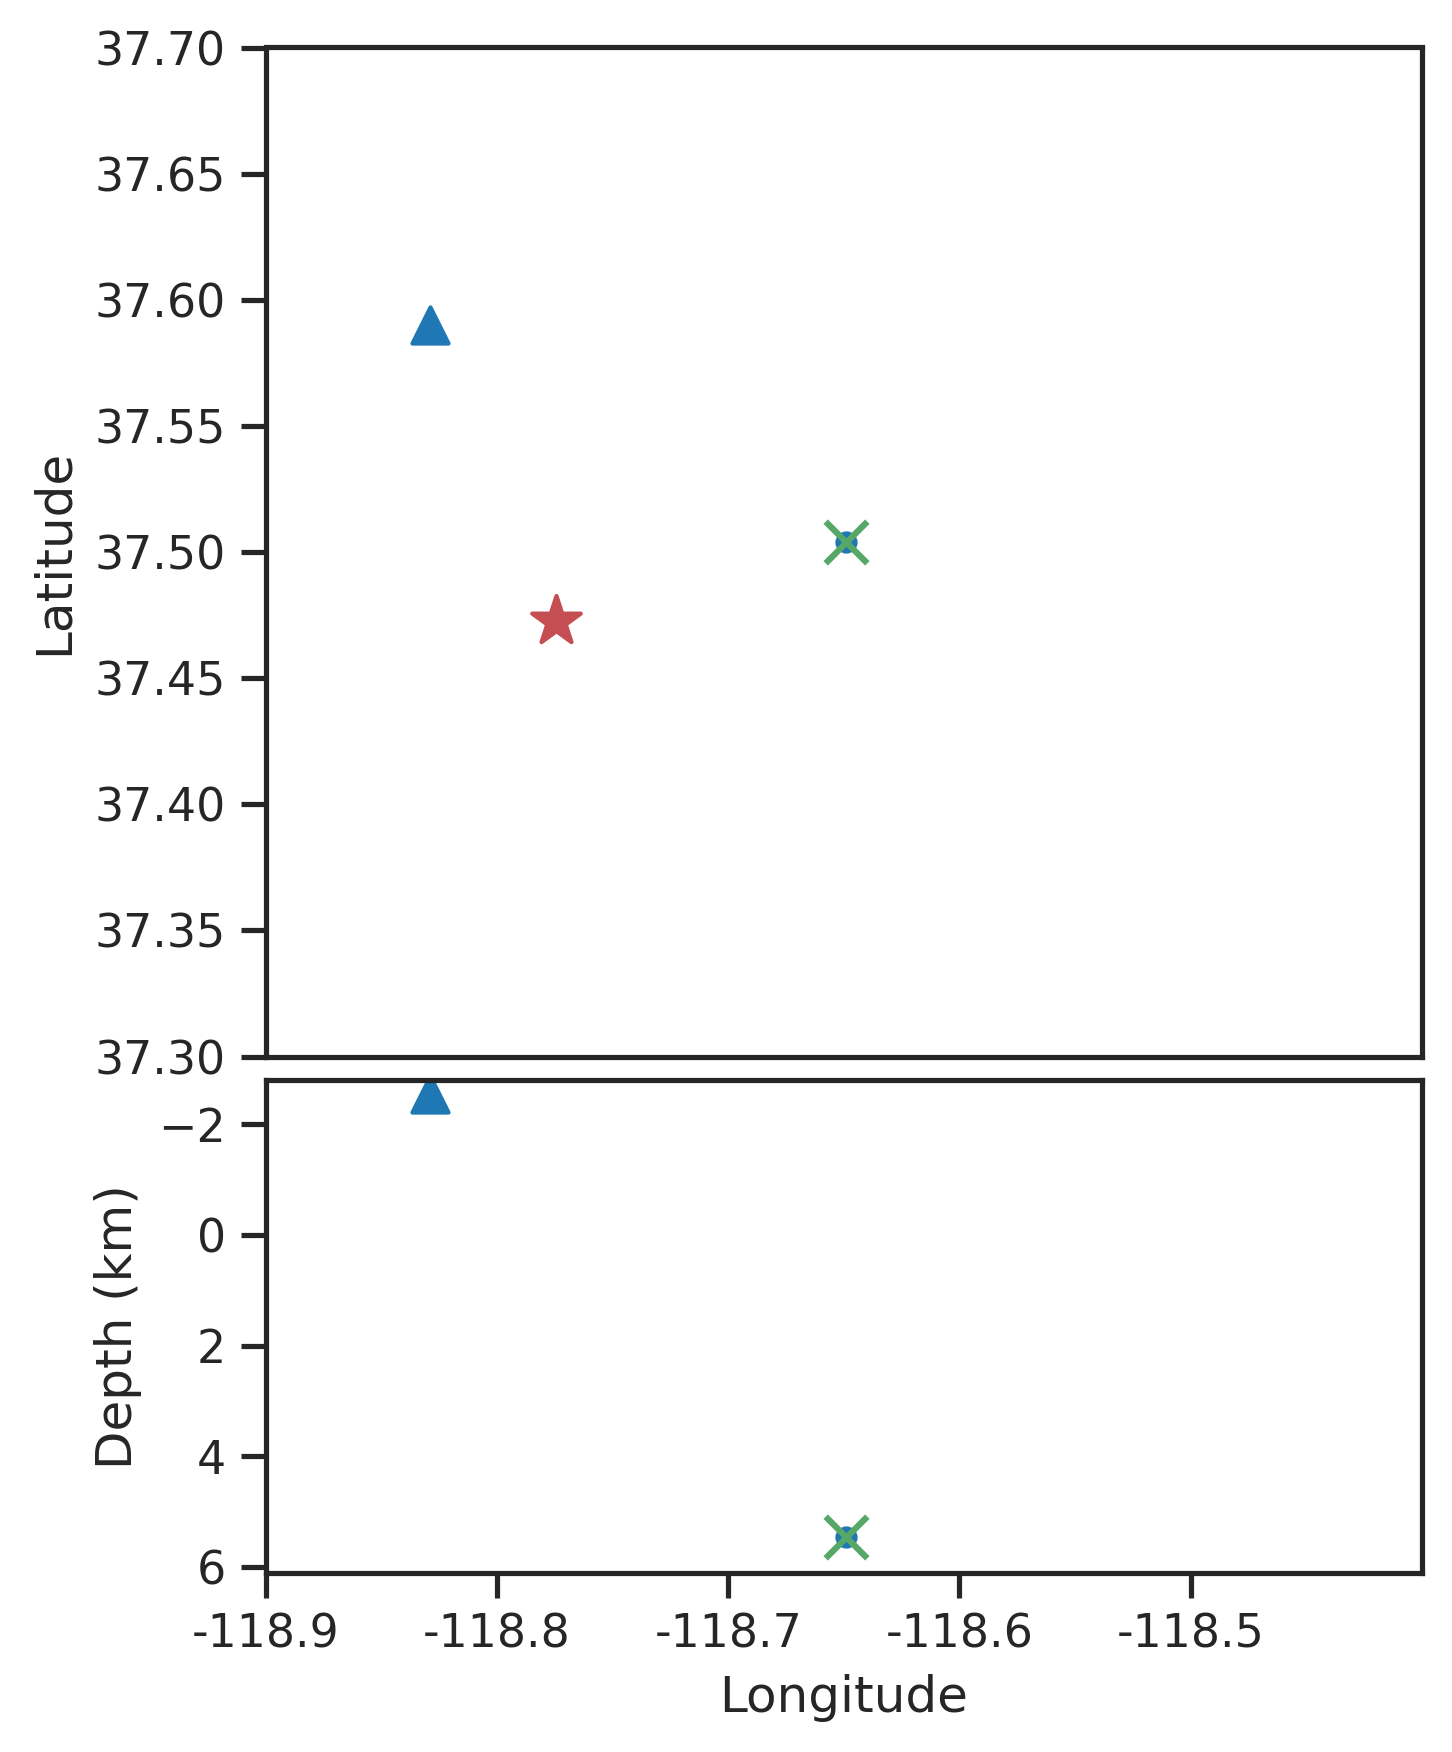

nc71111679


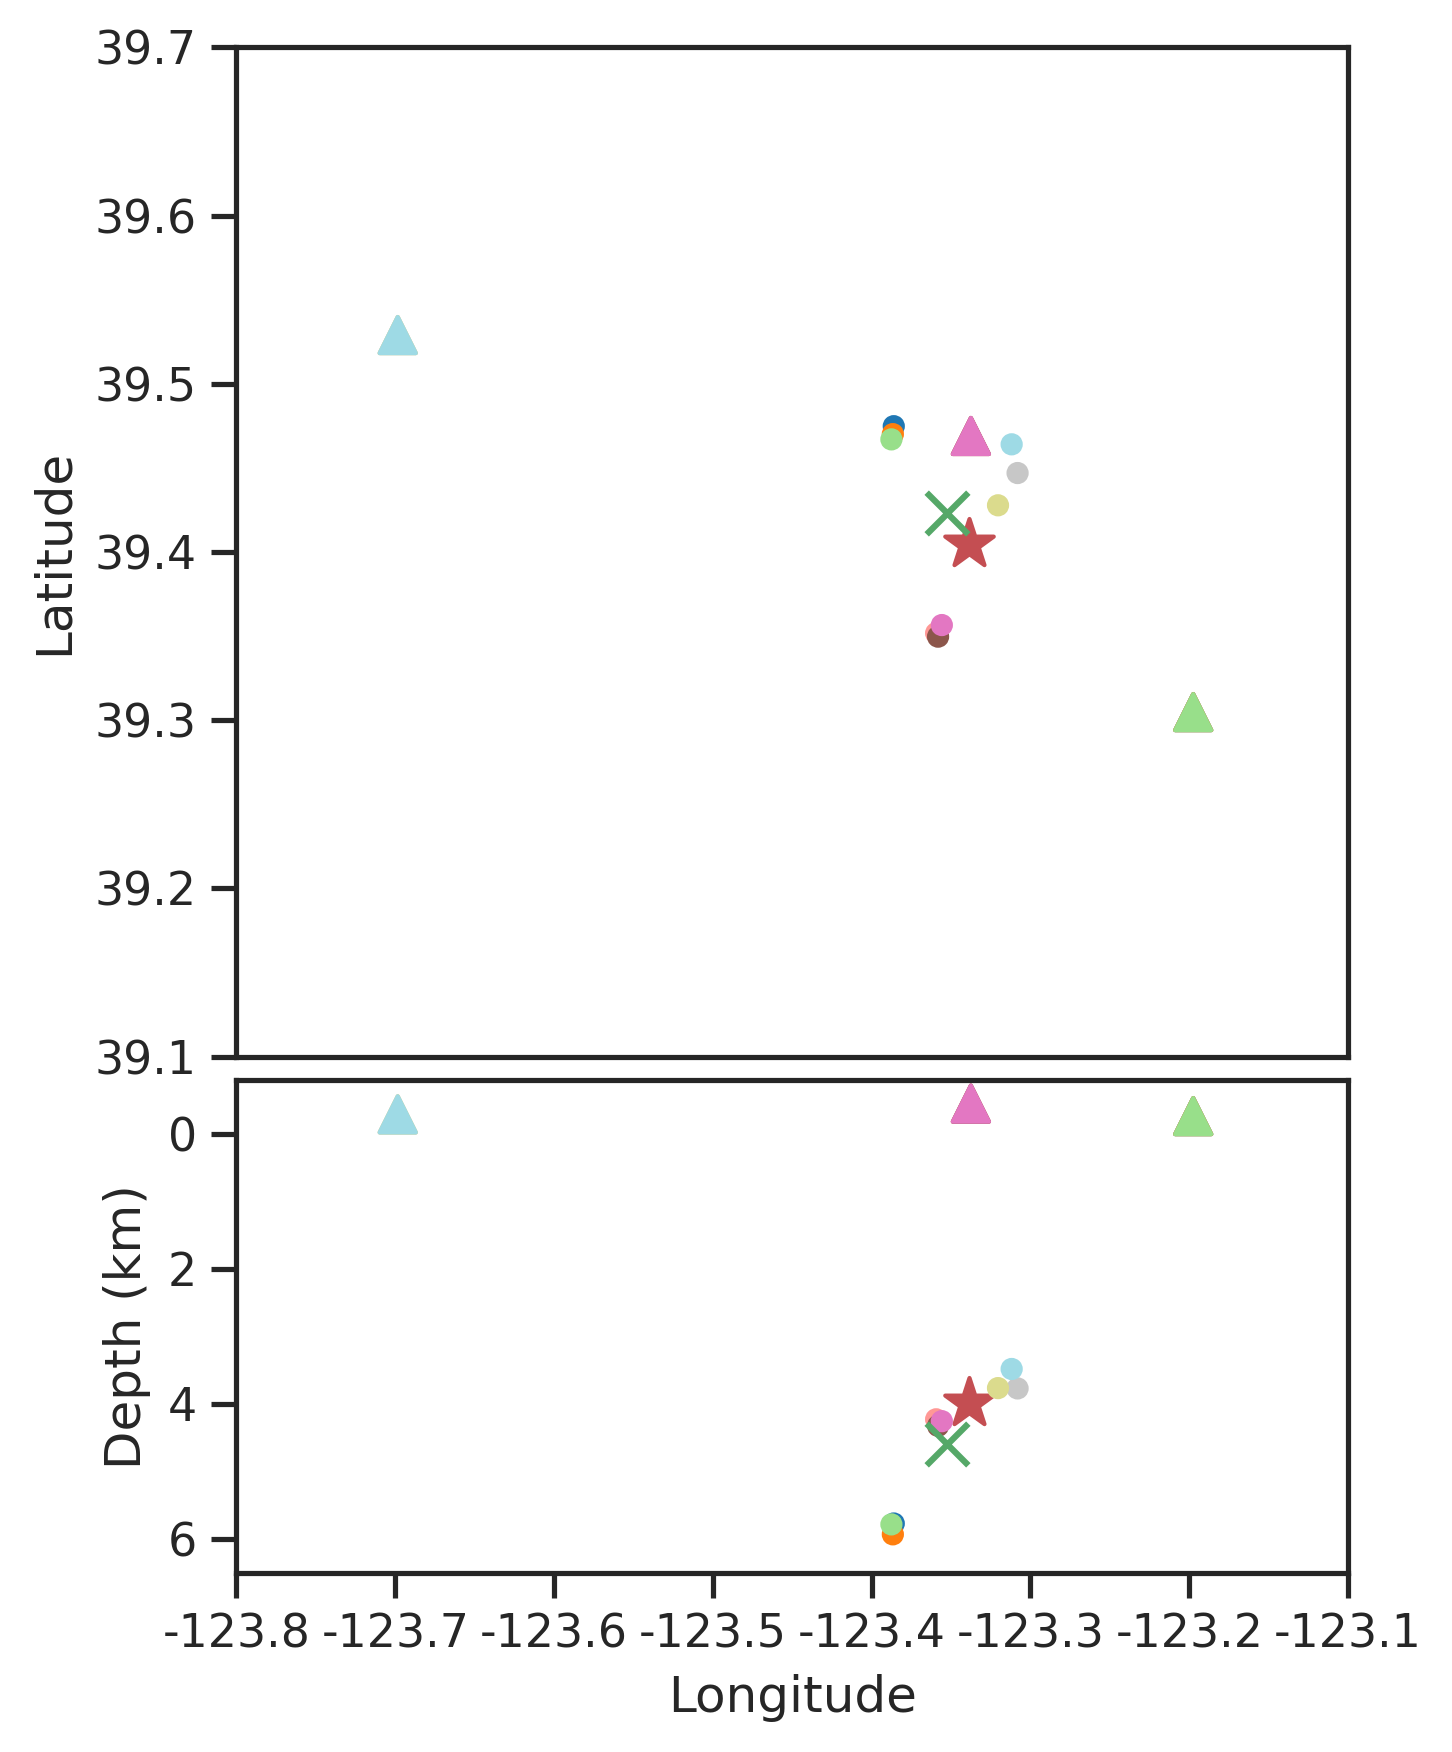

nc71111689


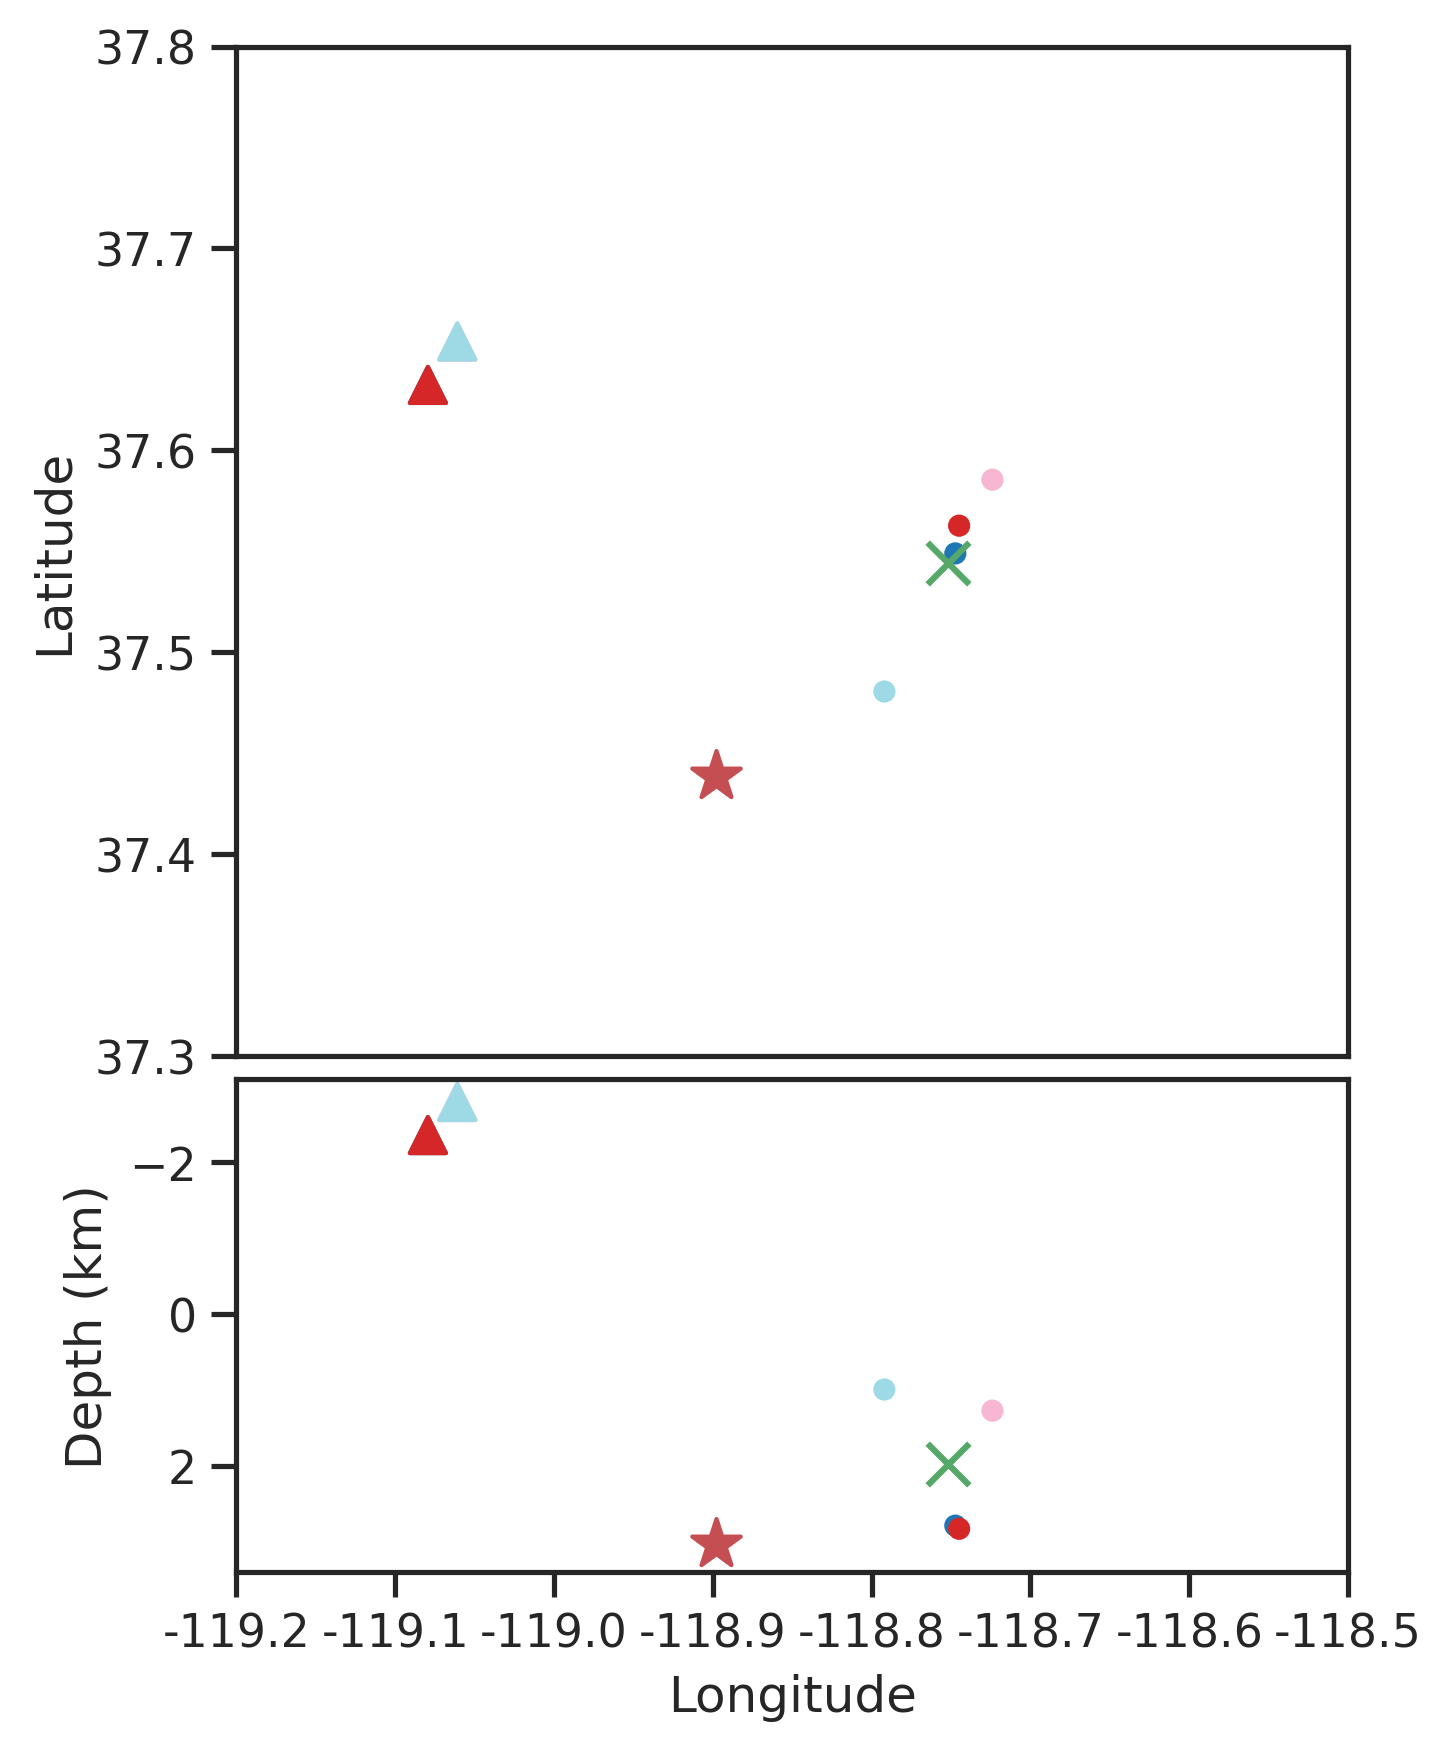

nc71111694


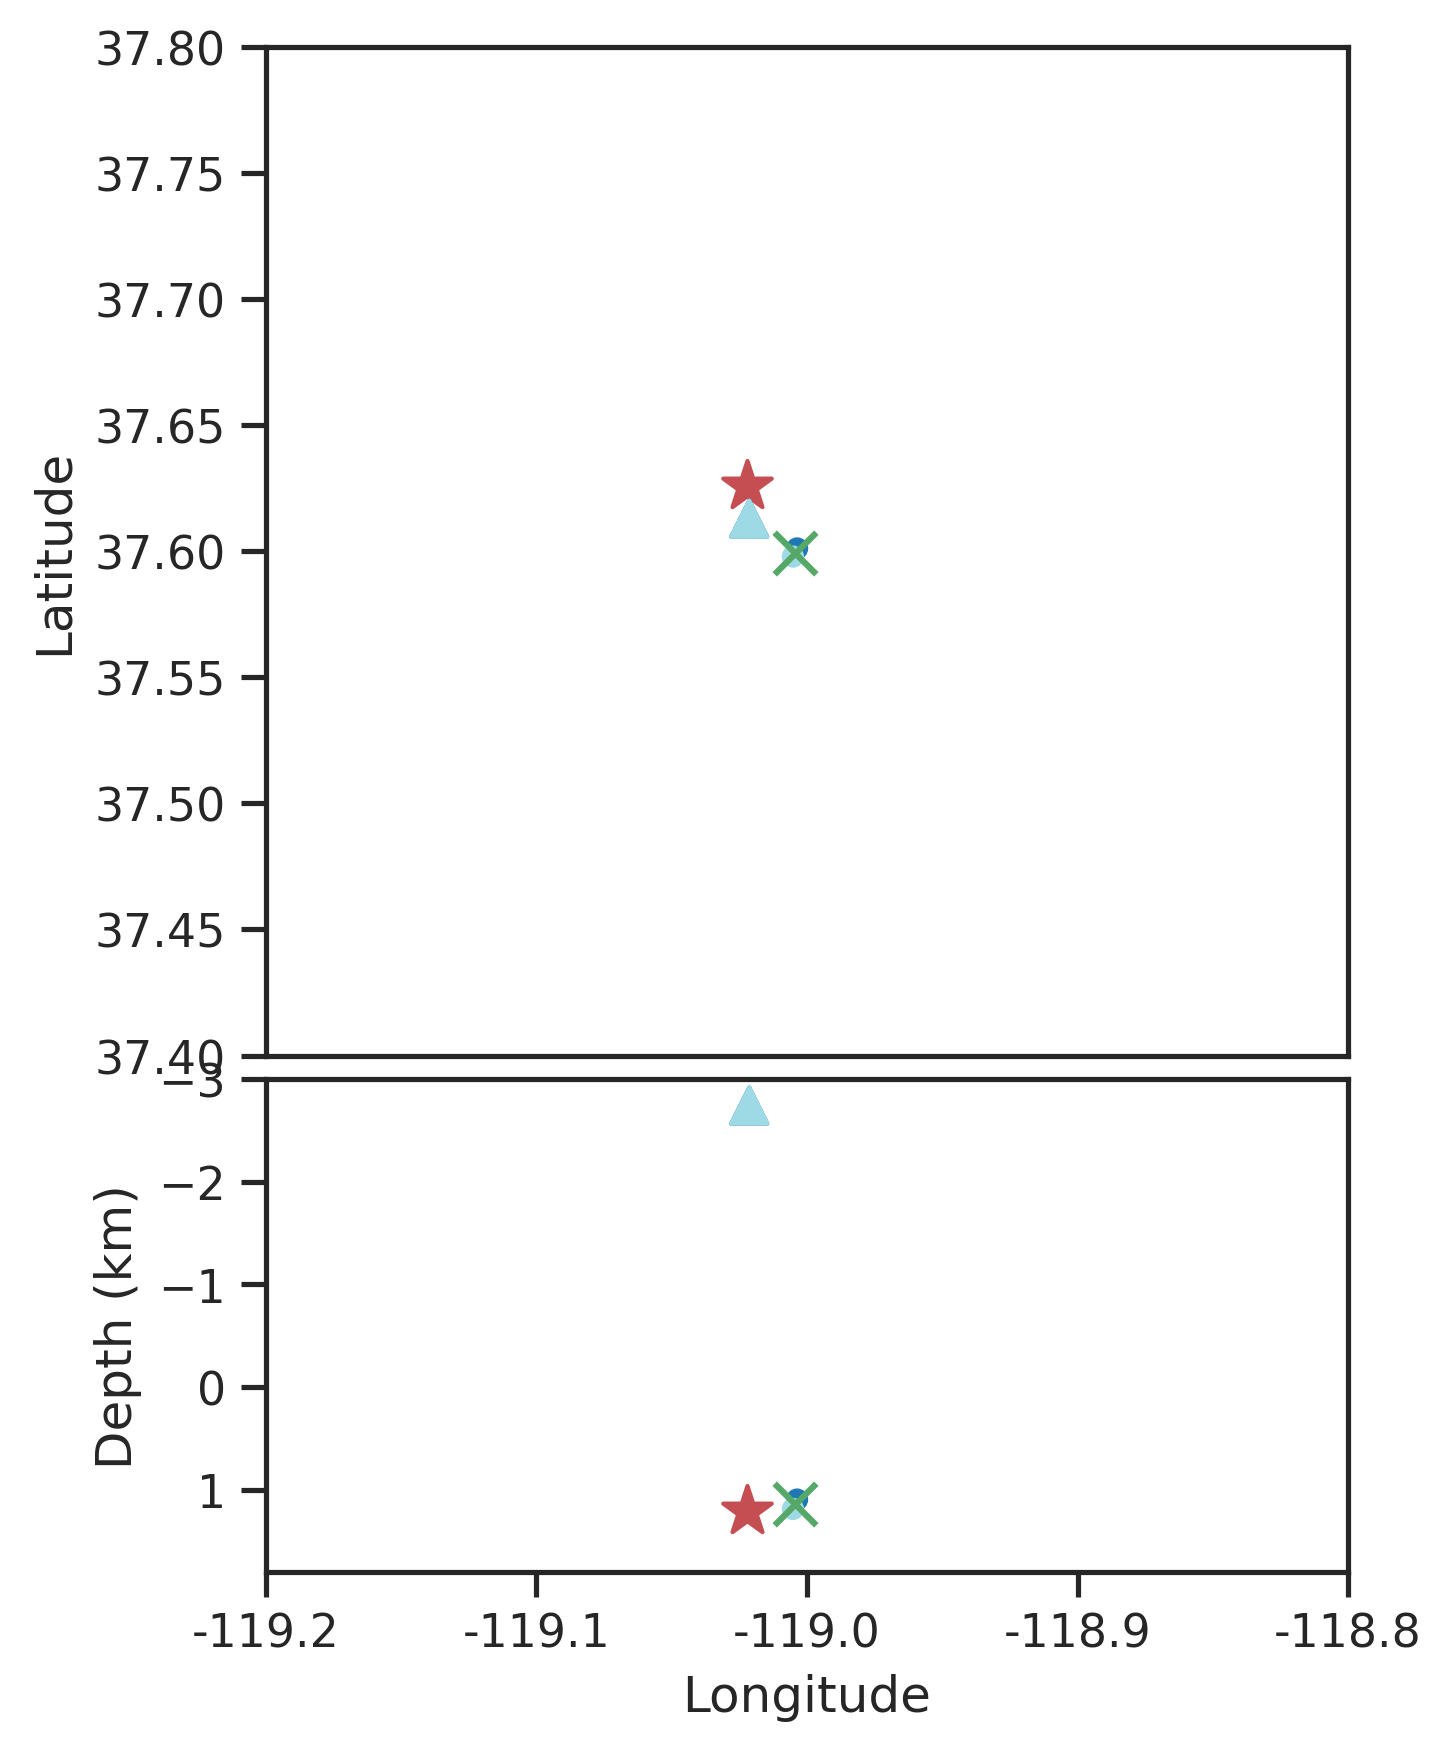

nc71111699


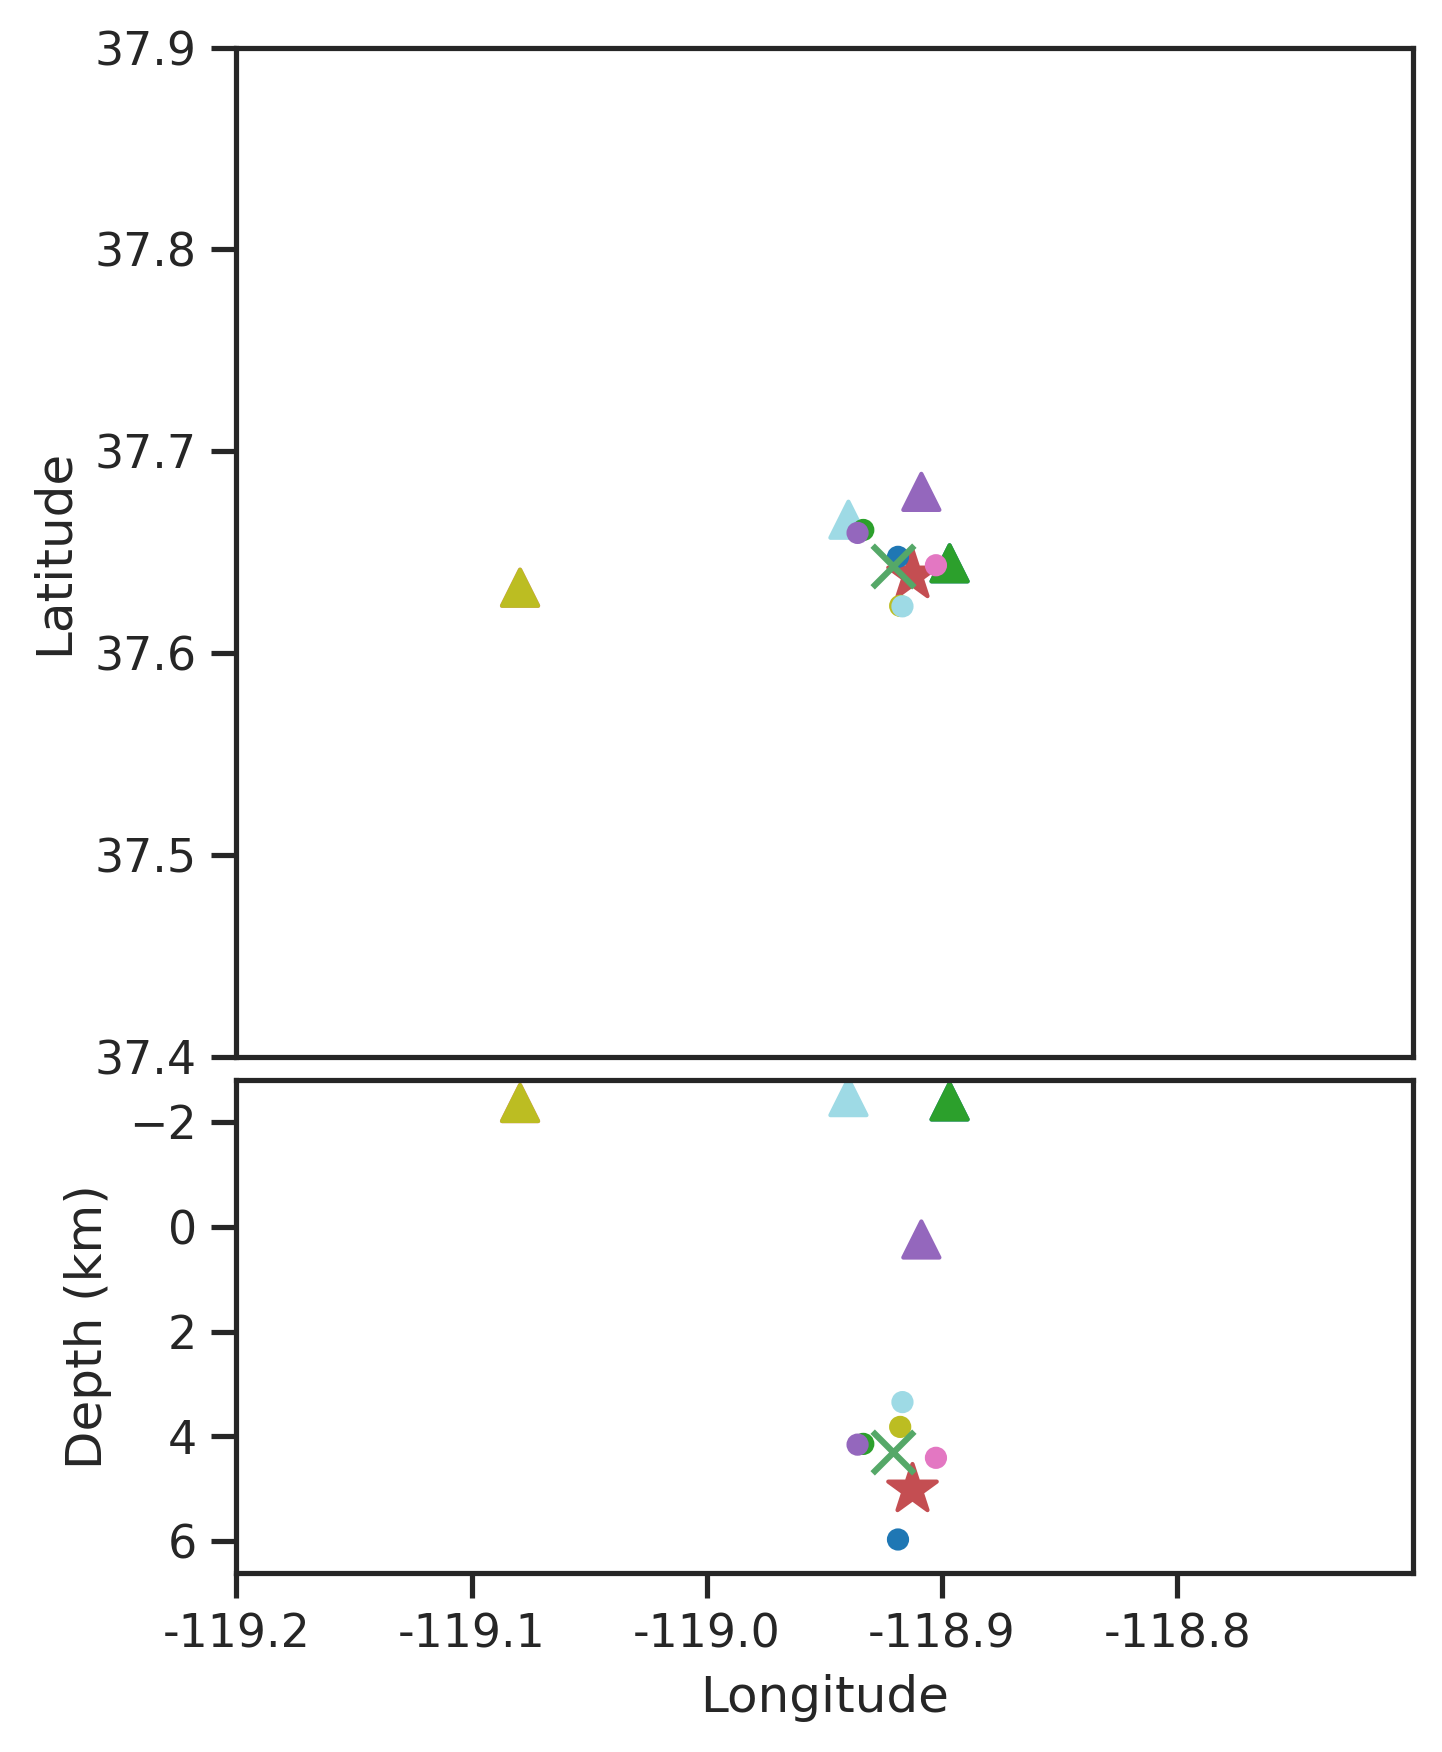

nc71111709


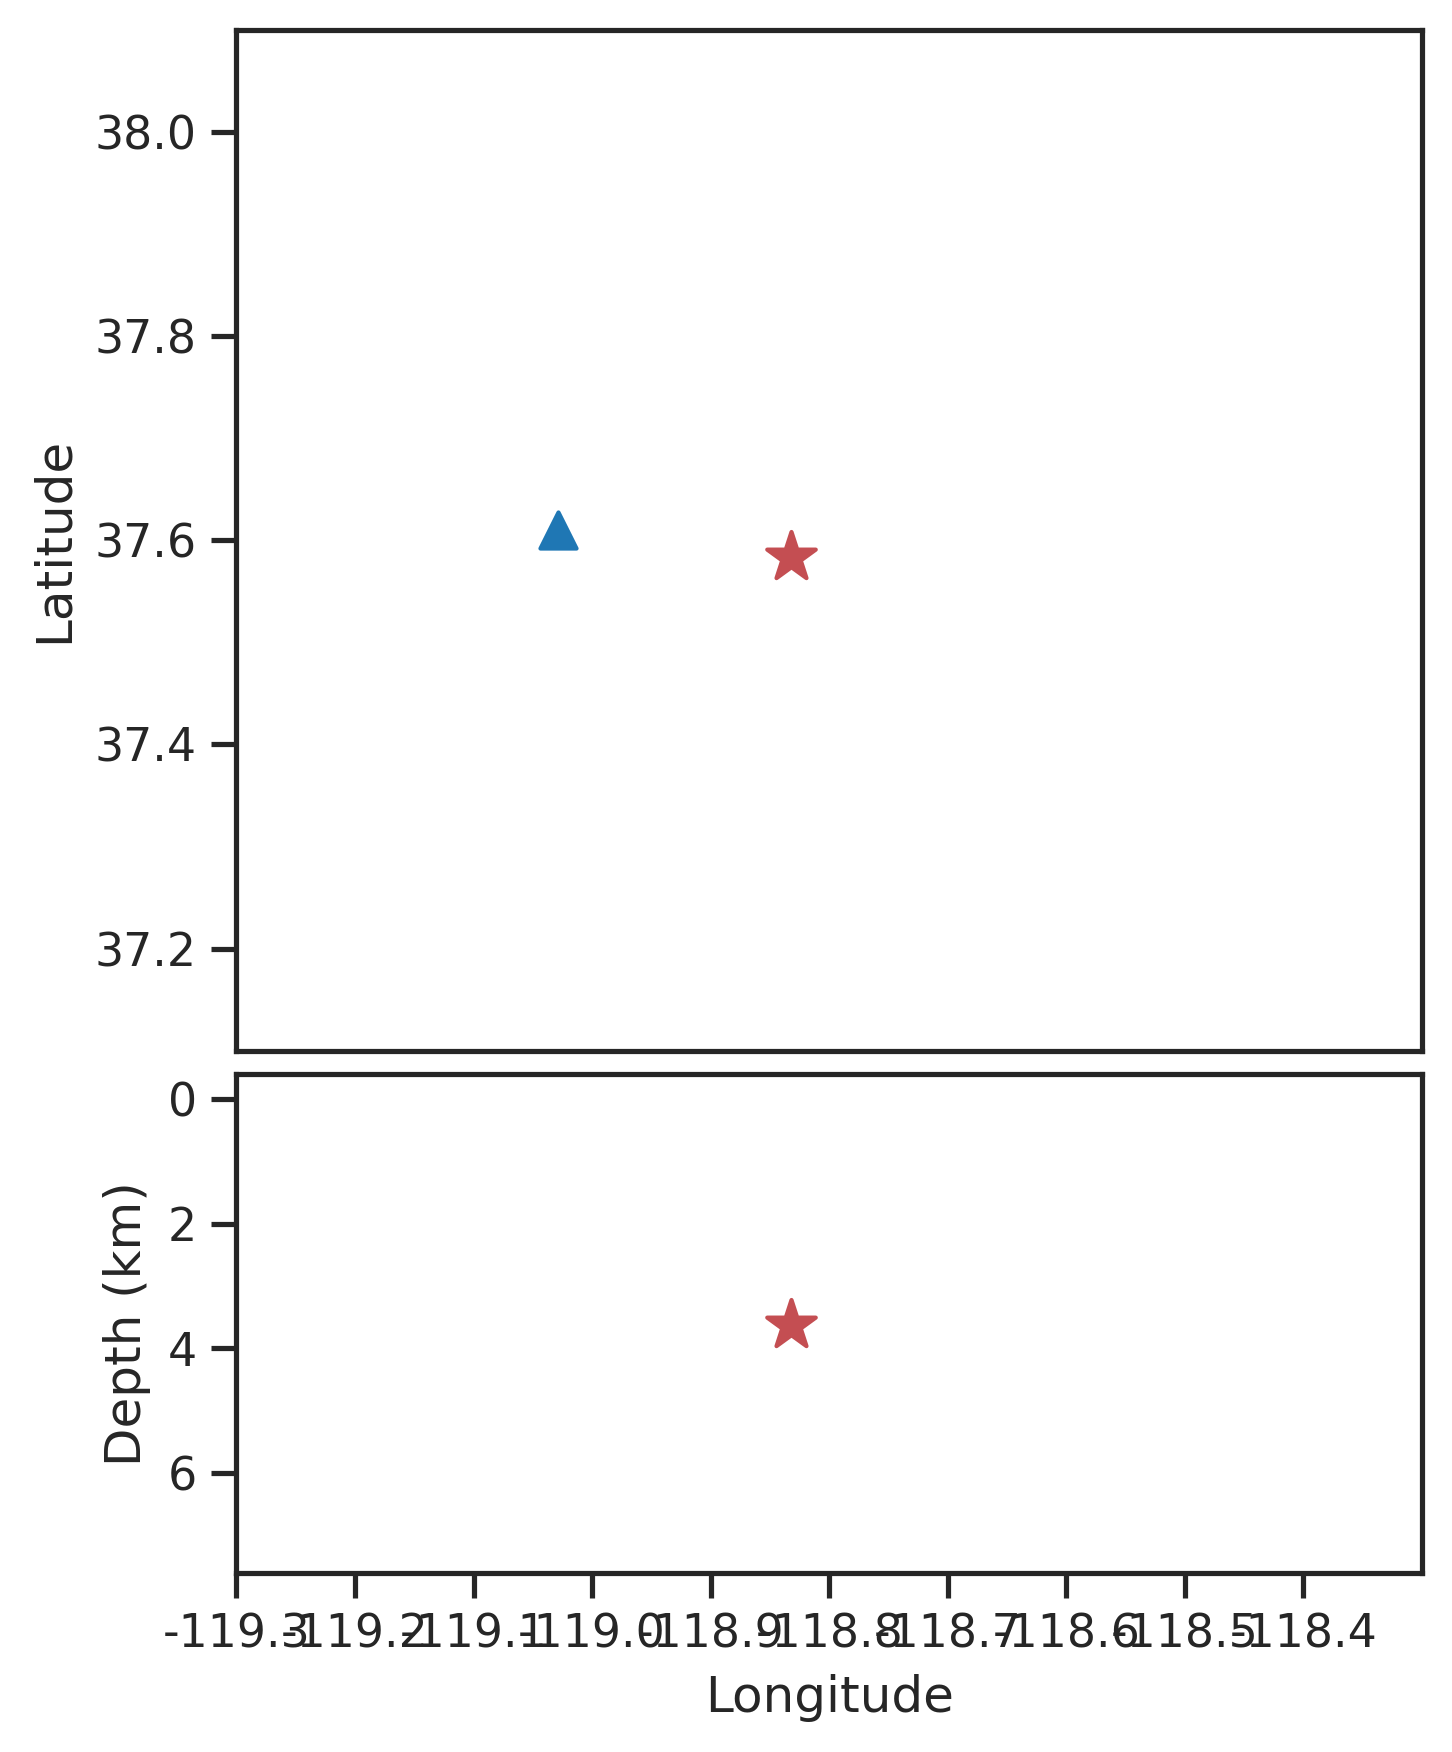

nc71111714


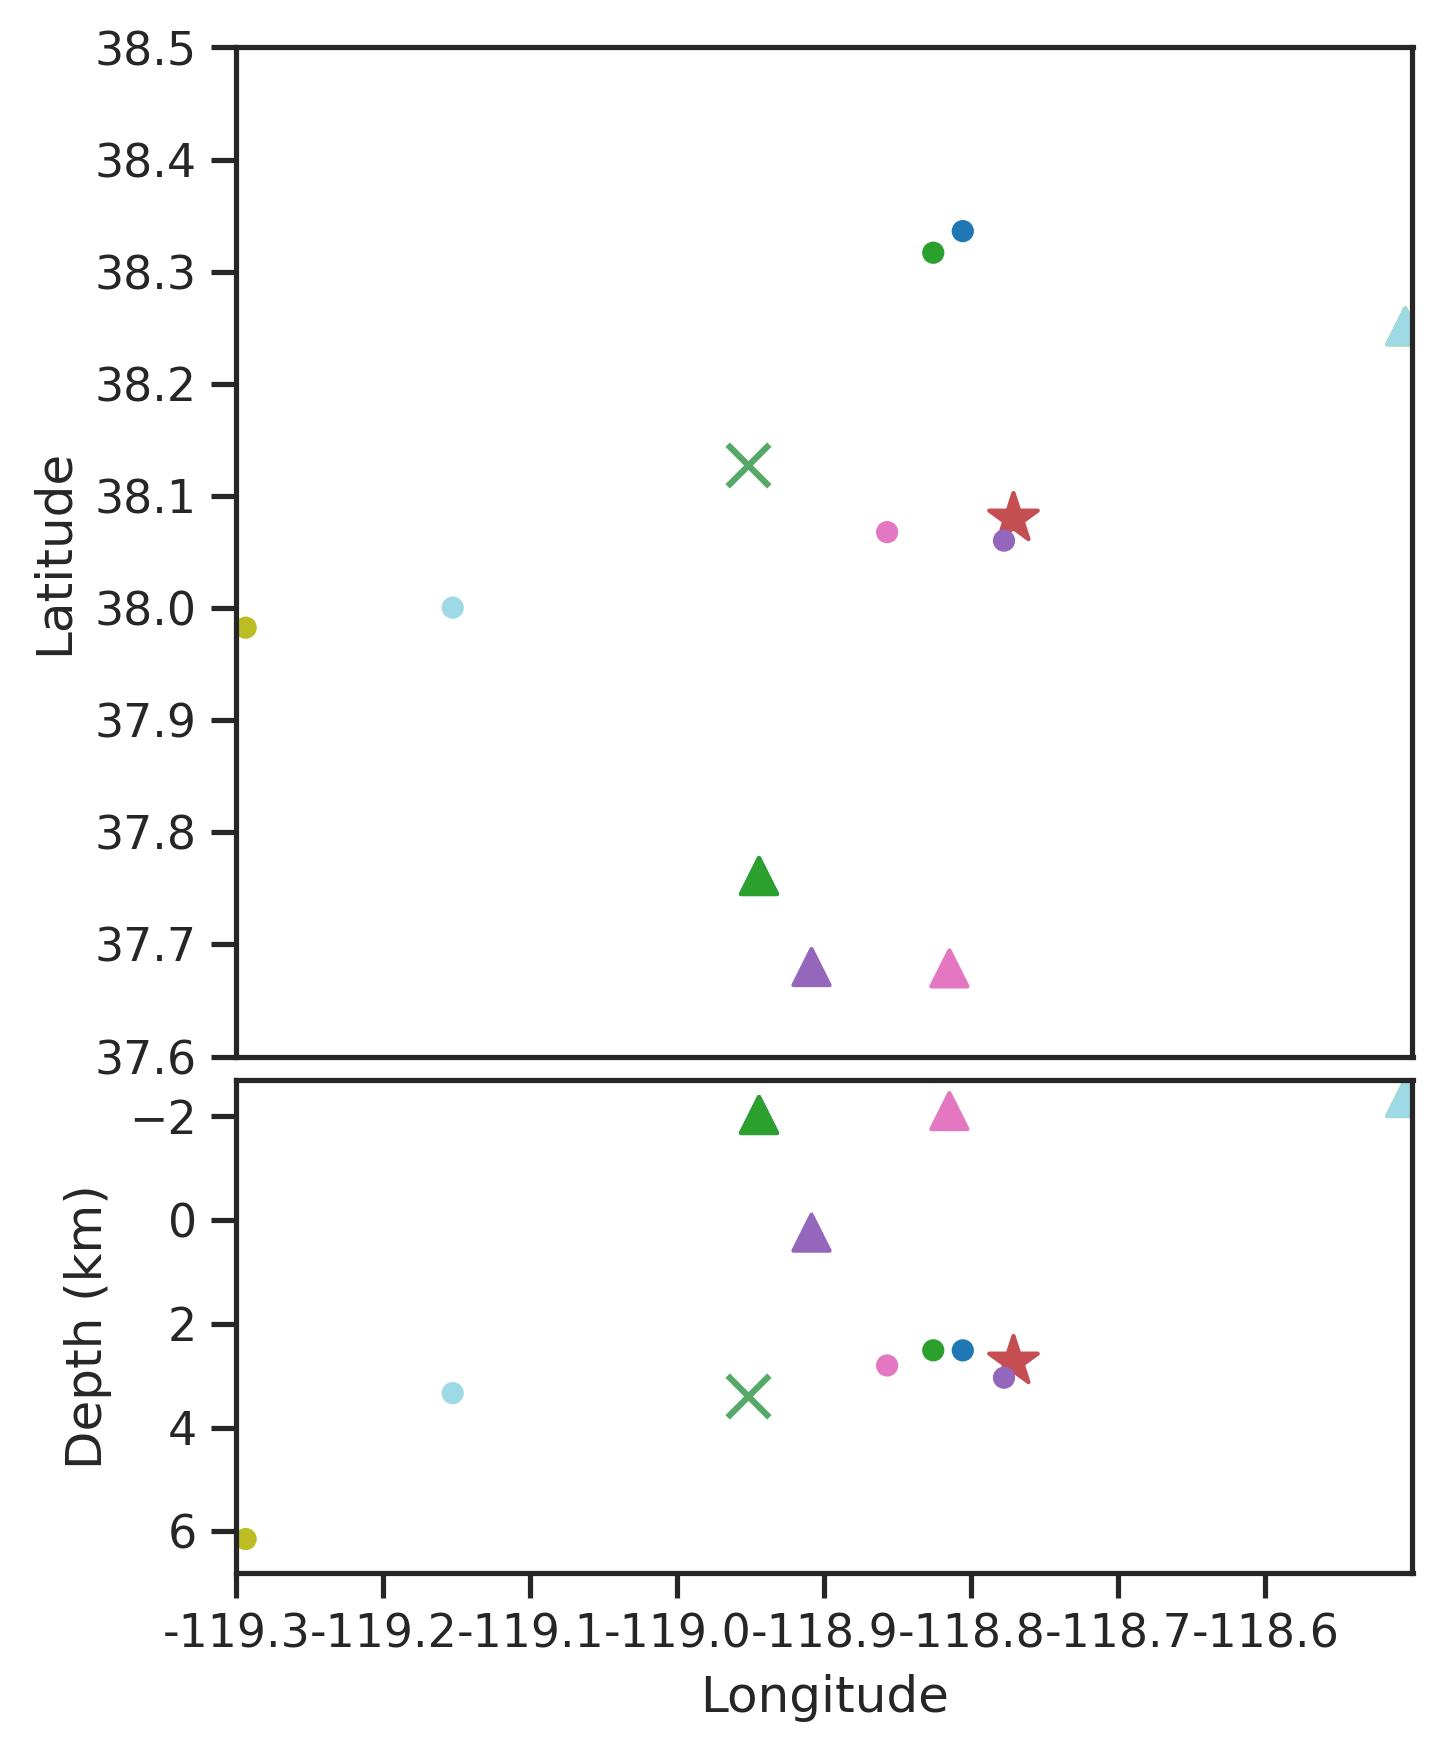

nc71111774


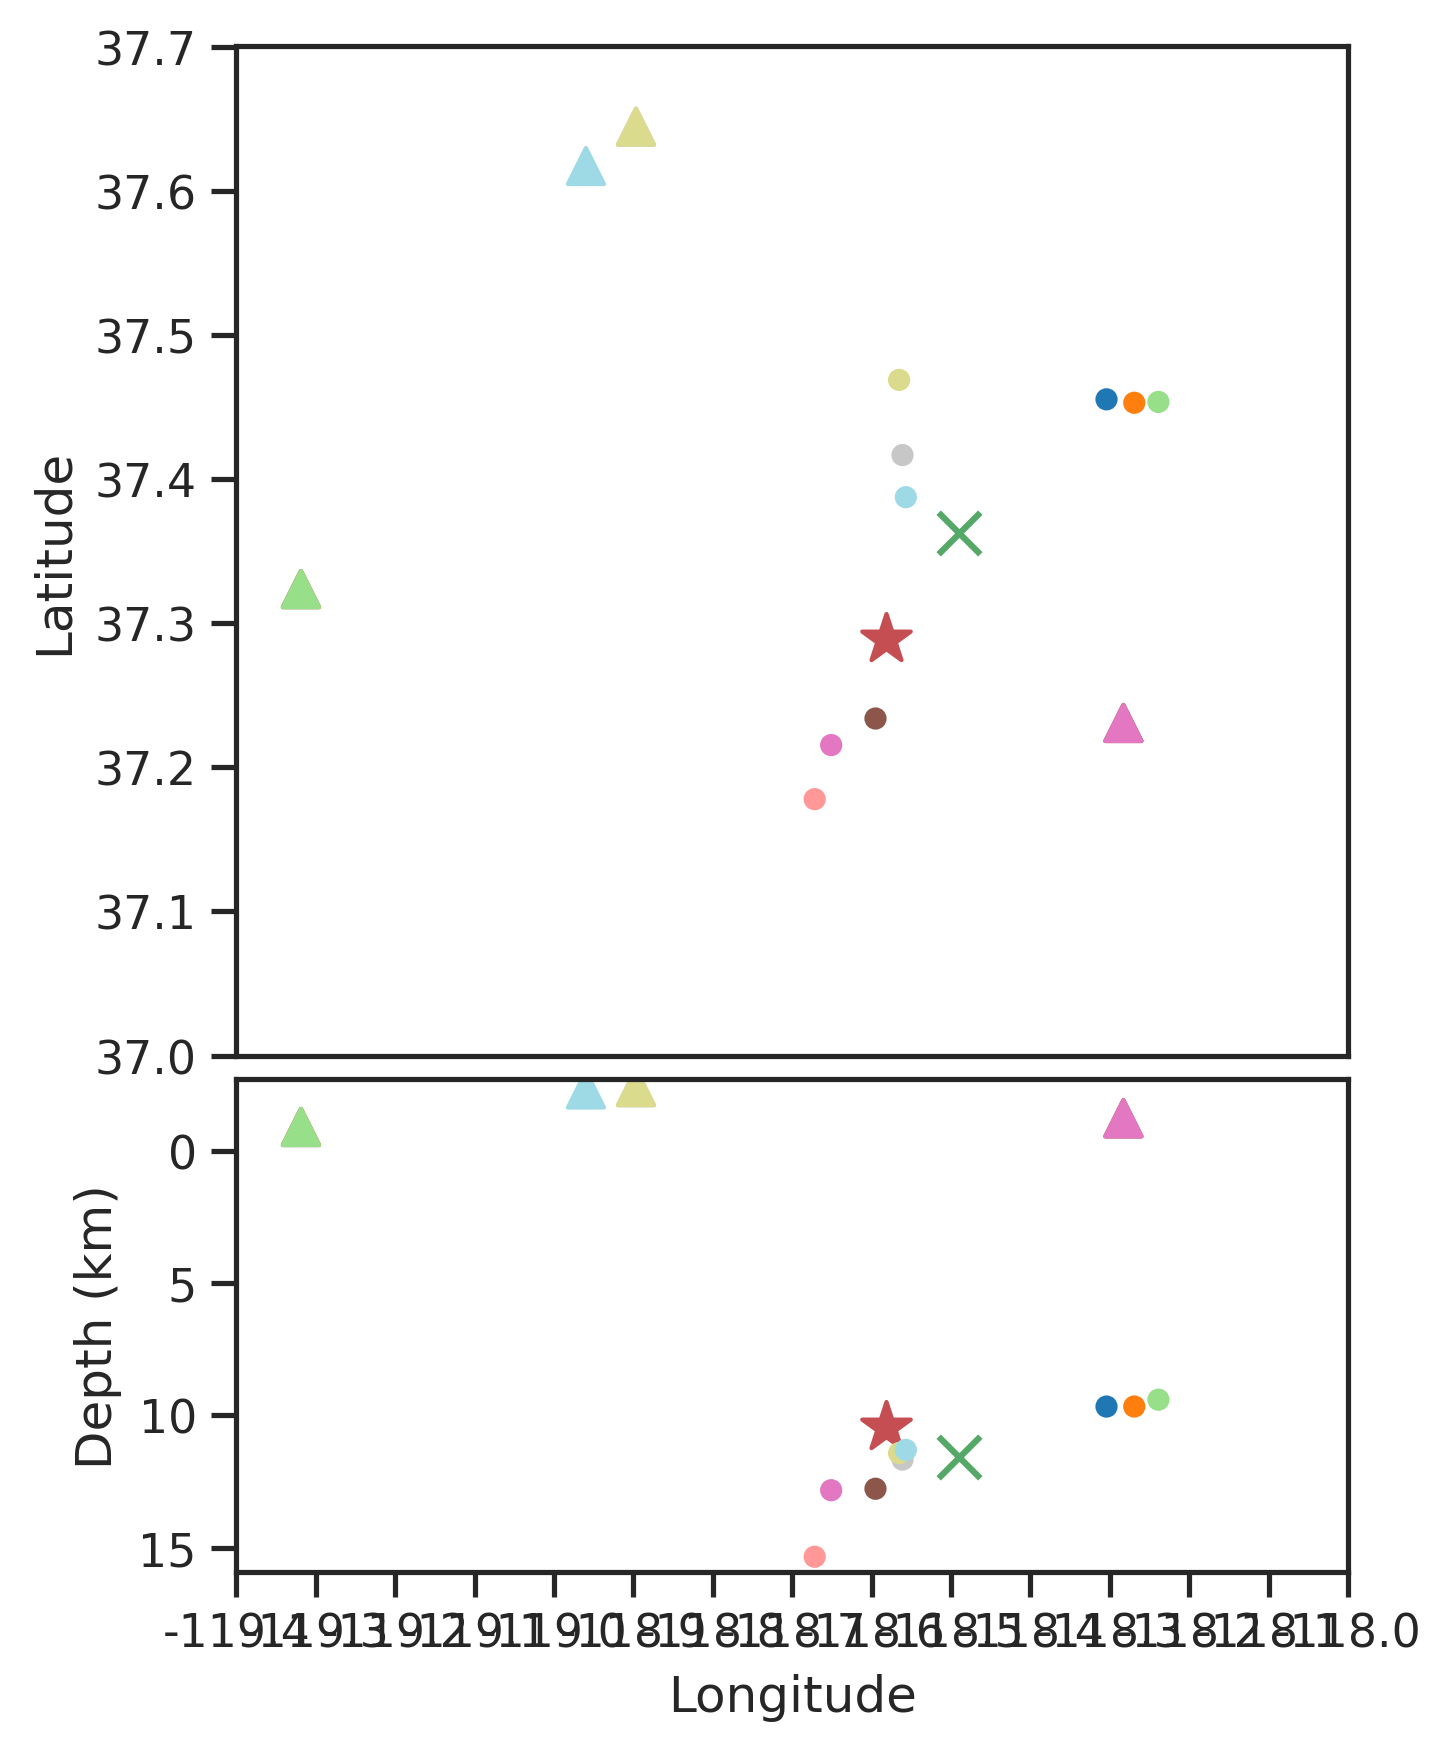

nc71111779


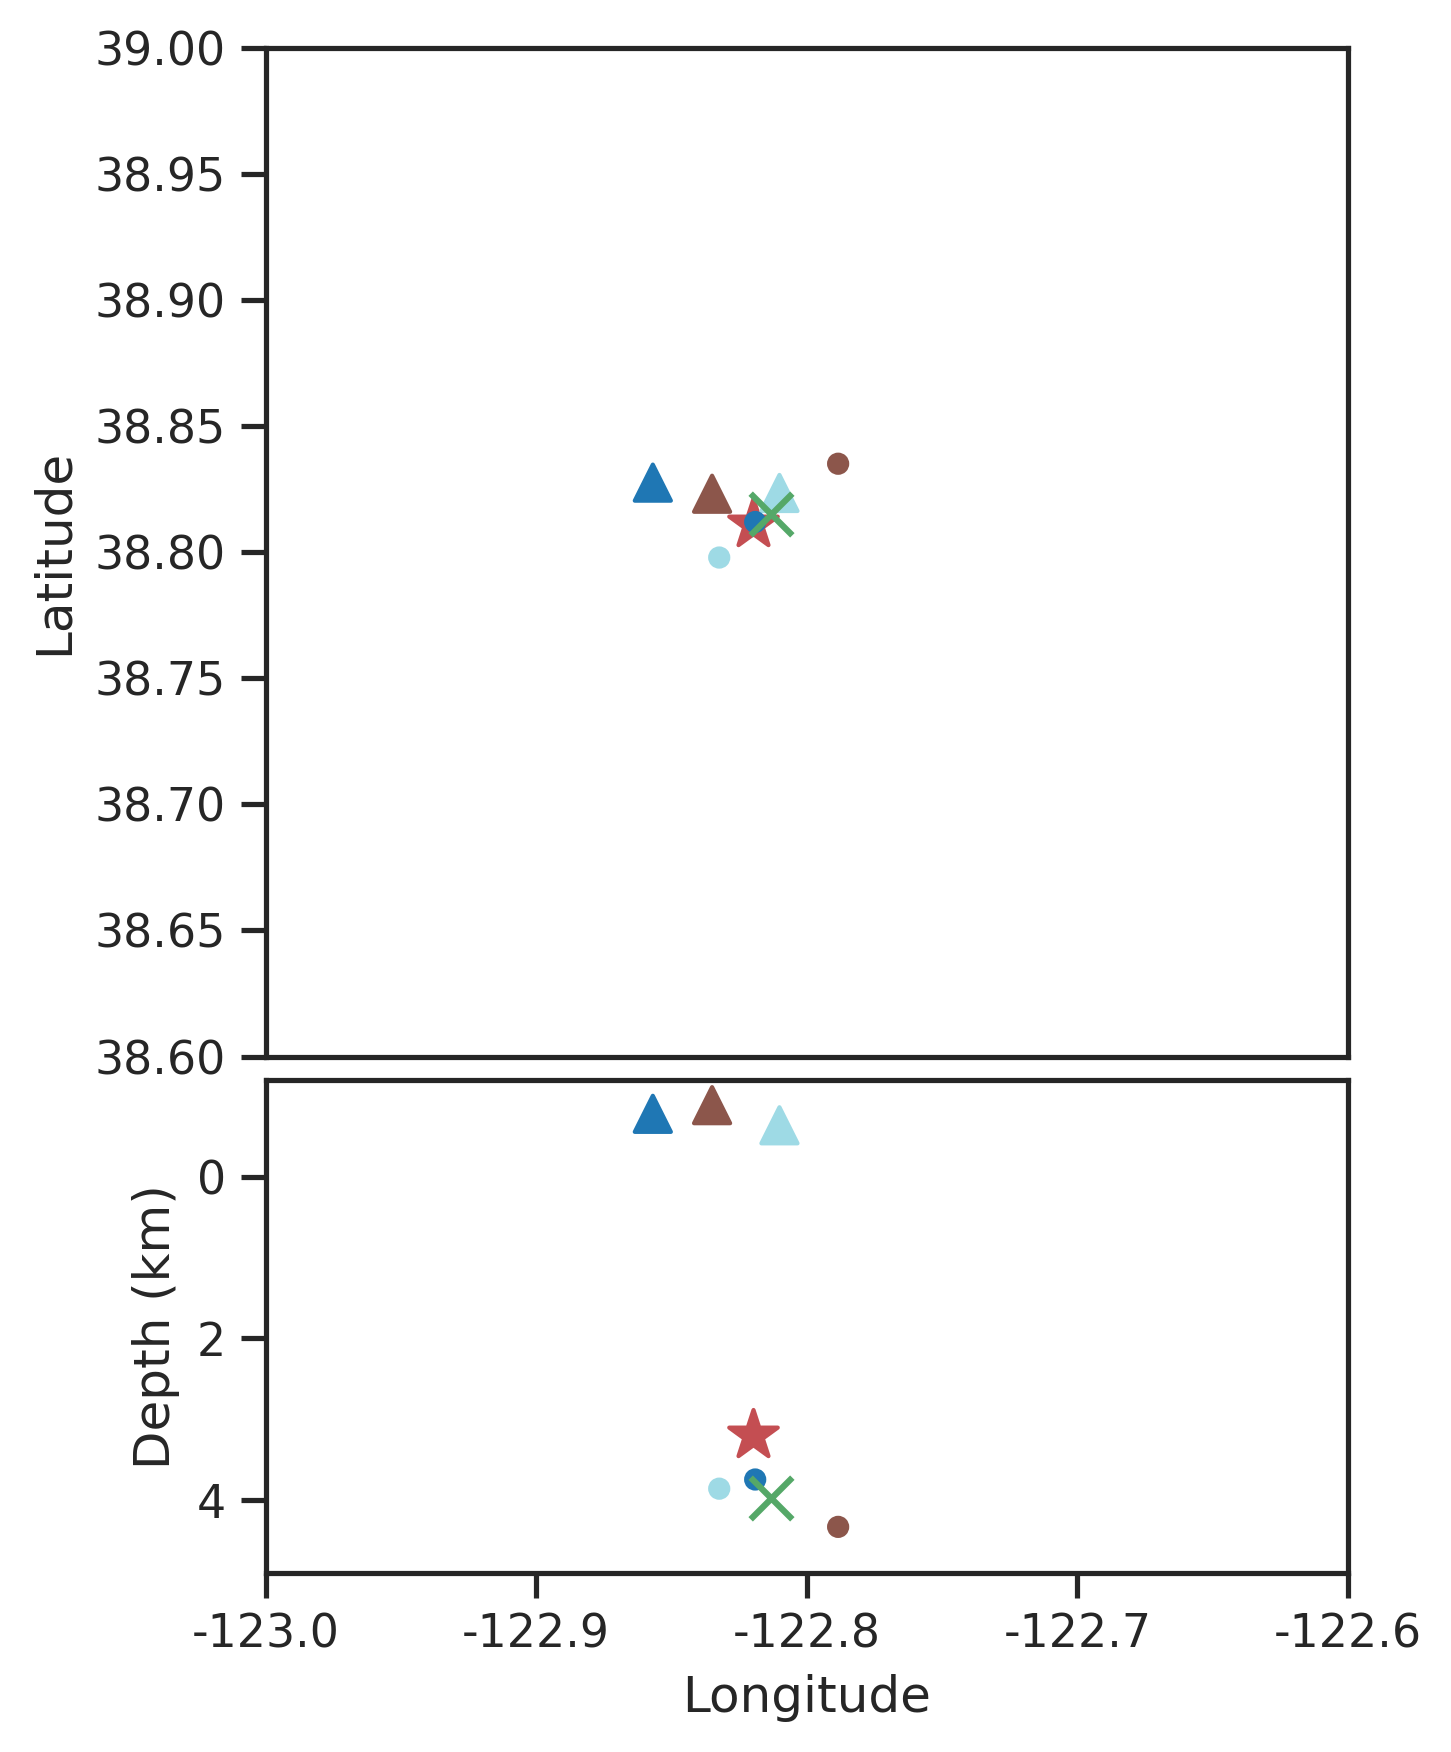

nc71111874


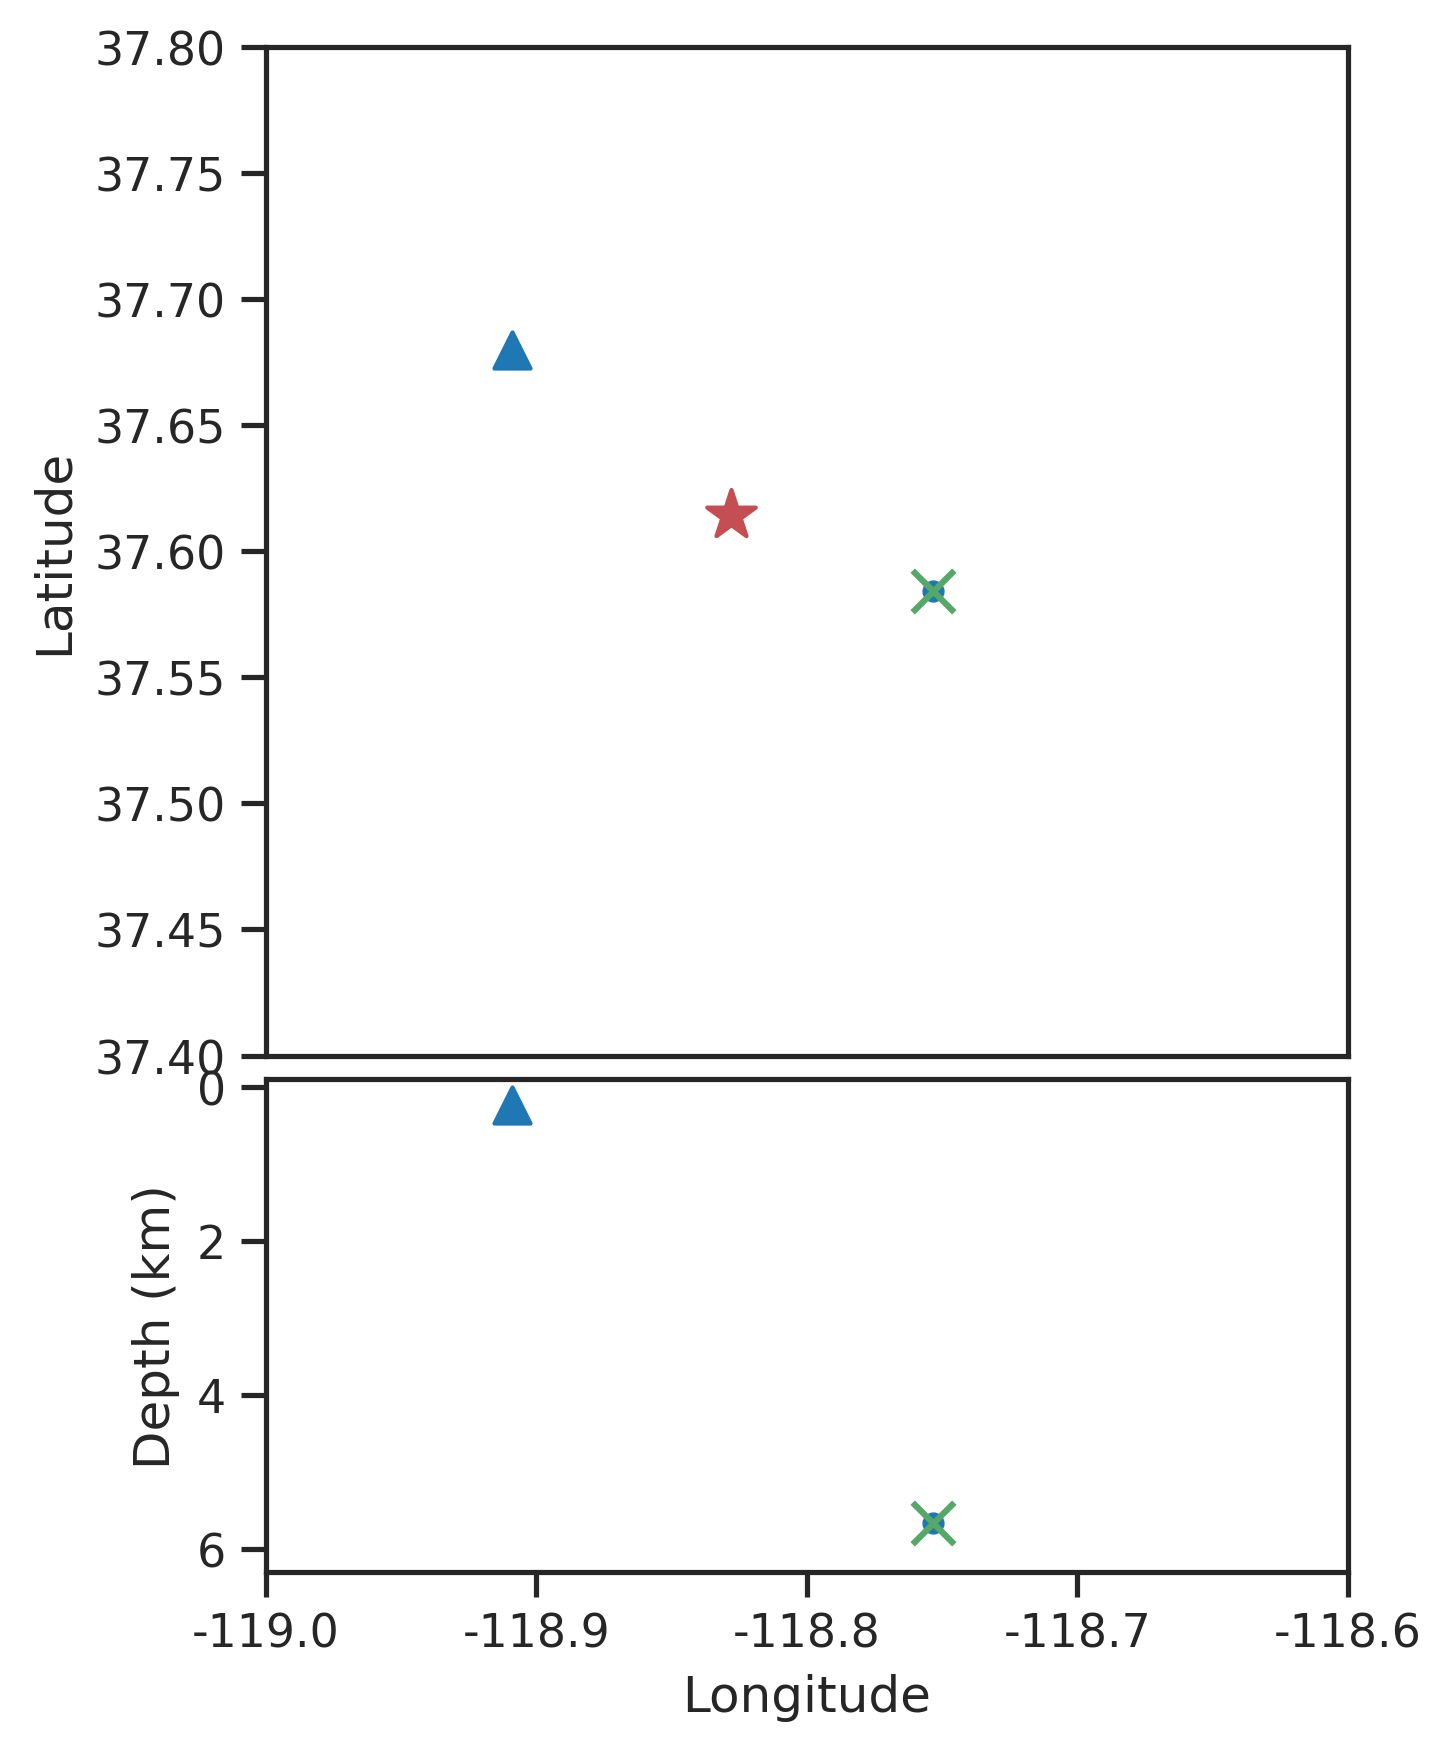

nc71111879


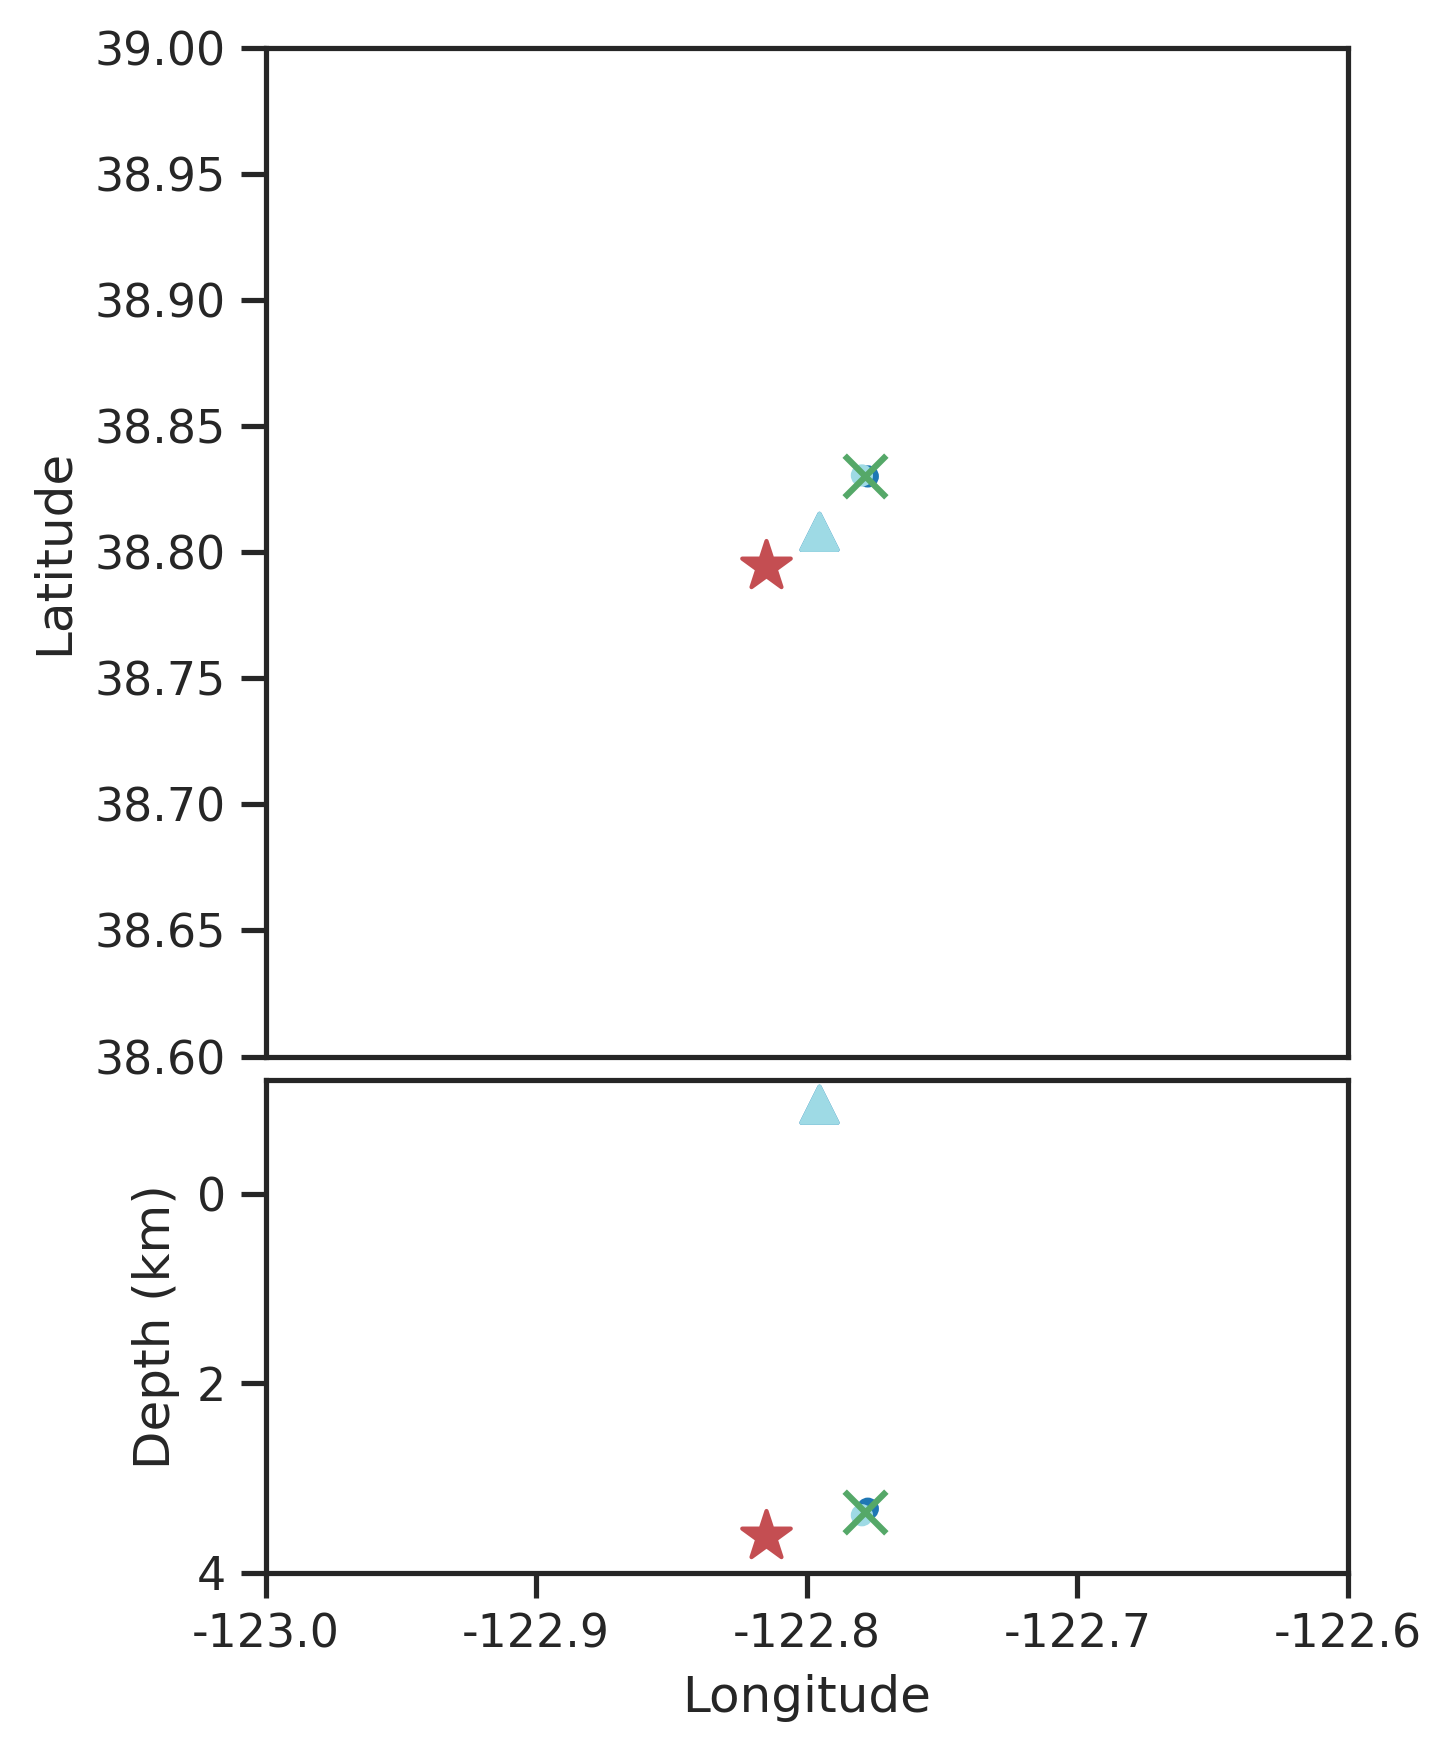

nc71111894


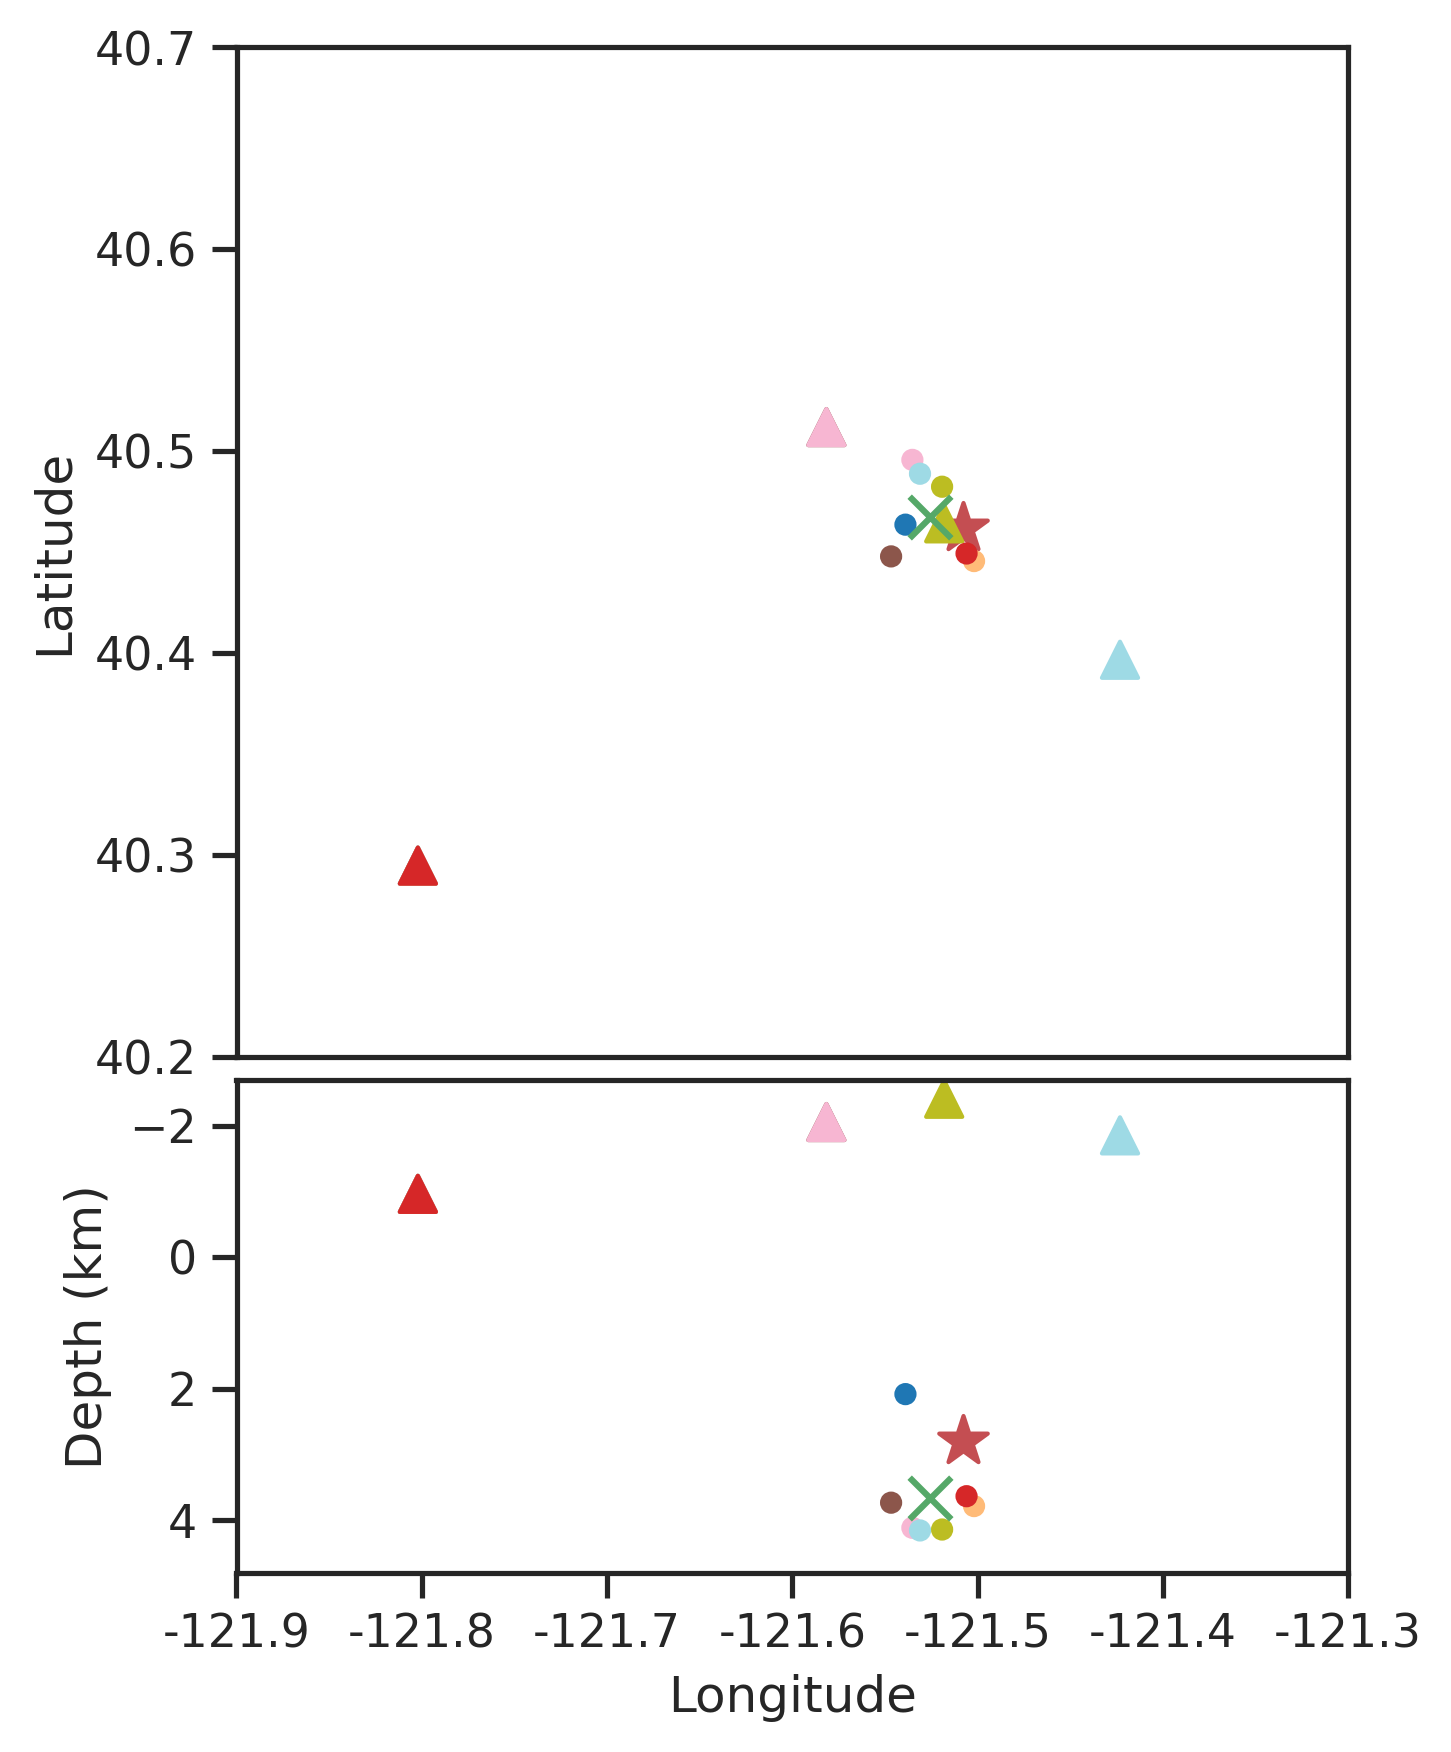

nc71111899


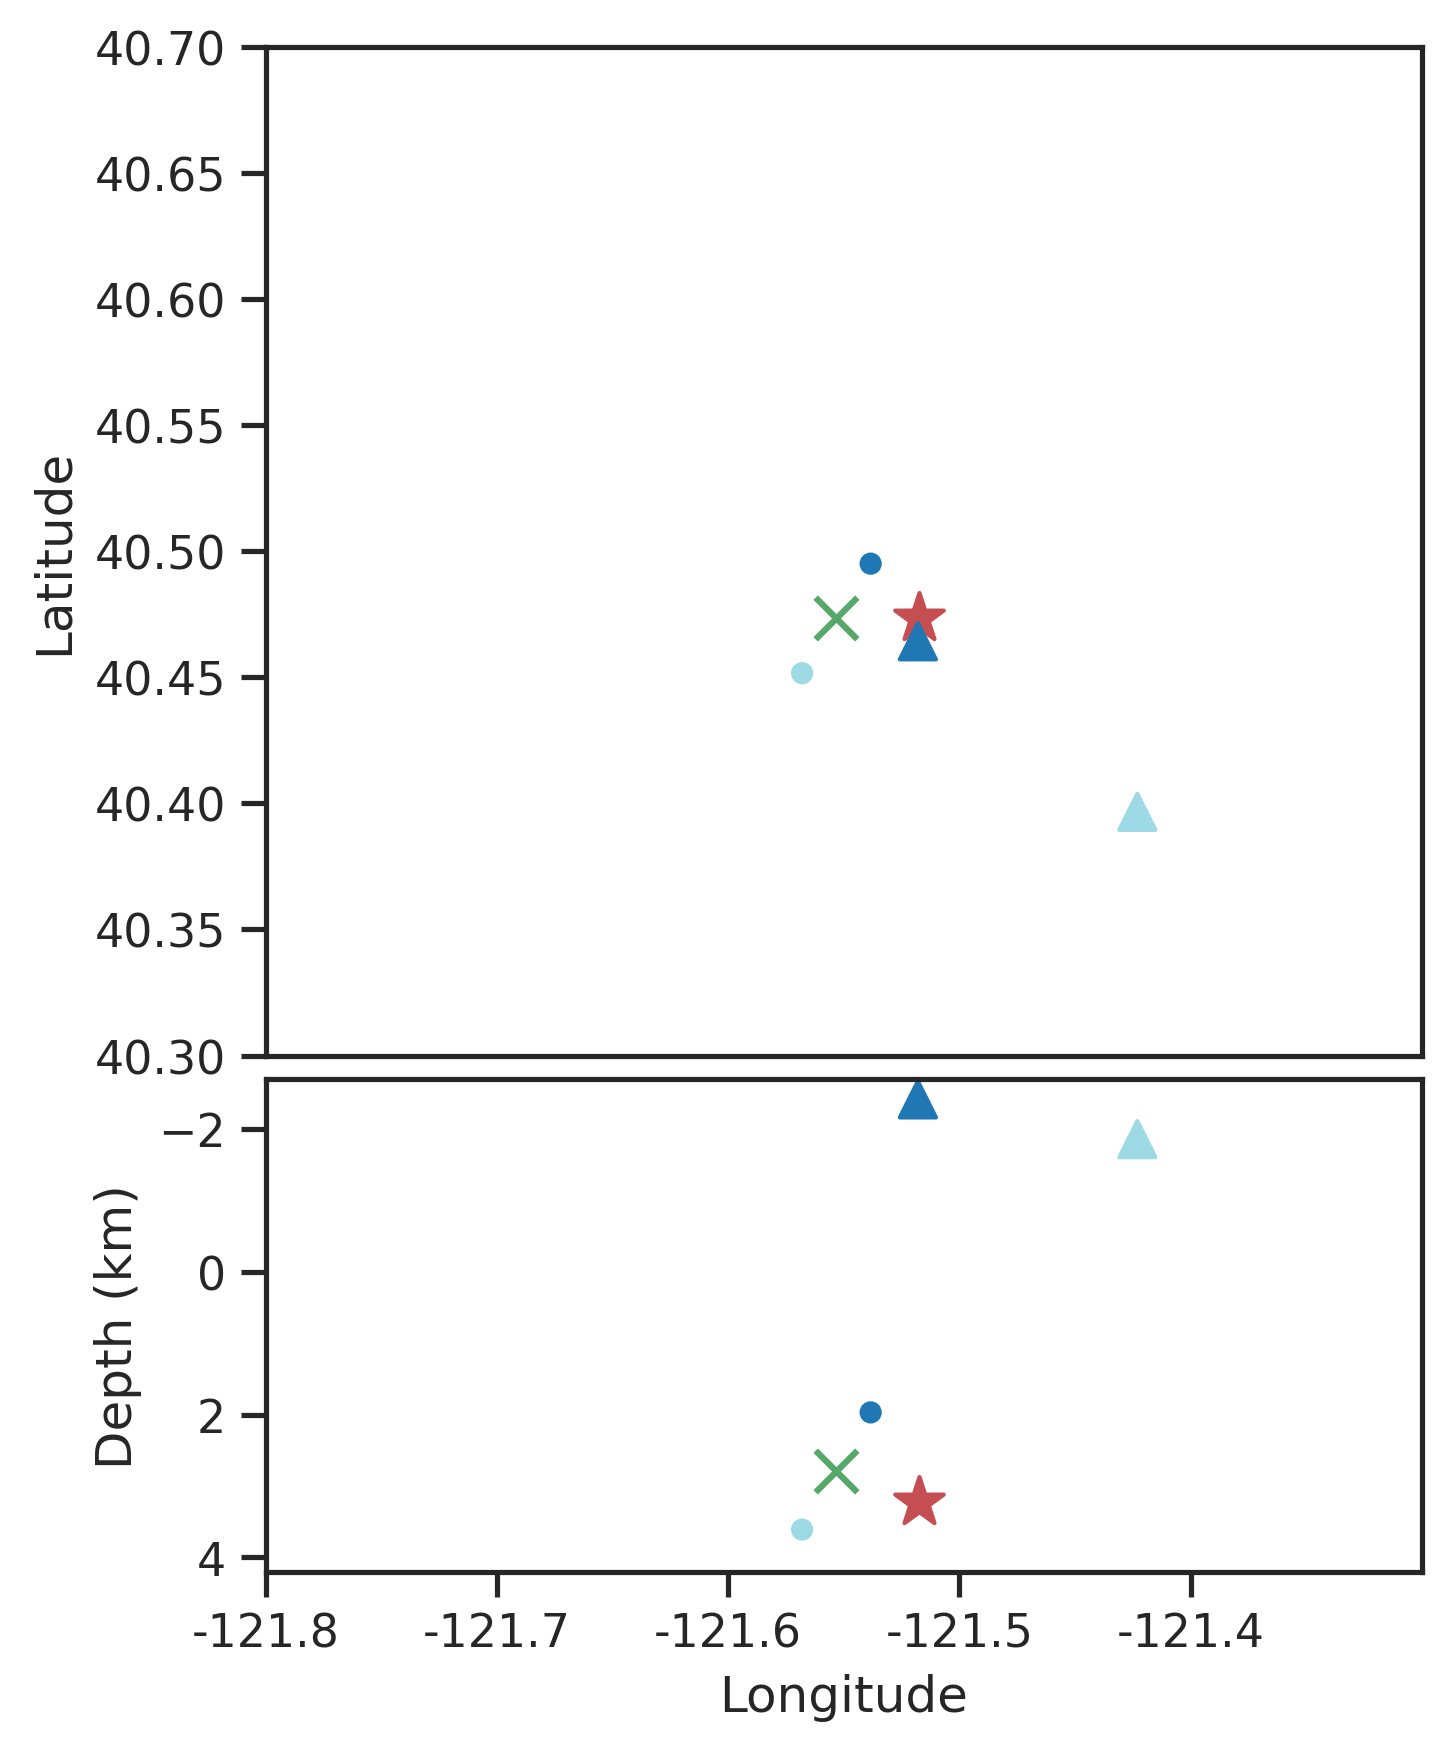

: 

In [104]:
catalog_case = pd.read_csv("/home/wanghy/tests/EQNet/tests/eqnet/test_eqnet_case_study/events_eqnet.csv")

for eve in selected_events:
    print(eve)
    models = [eve]
    event_case = nc2020[eve]
    event_case_loc = [event_case.attrs["longitude"], event_case.attrs["latitude"], event_case.attrs["depth_km"]]
    station_case_locs = np.array([(event_case[station_id].attrs["longitude"], event_case[station_id].attrs["latitude"], -event_case[station_id].attrs["elevation_m"]/1000) for station_id in list(event_case.keys())])
    try:
        event_pred_catalog = pd.read_csv(f'/home/wanghy/tests/EQNet/tests/eqnet/test_eqnet_case_study/events_eqnet/{eve}.csv')
        event_pred = [event_pred_catalog["event_longitude"].values, event_pred_catalog["event_latitude"].values, event_pred_catalog["event_location_z"].values]
        event_pred = np.array(event_pred).transpose()[np.newaxis, :, :]
        xlim = round(event_pred[:,:,0].min()-0.1, 1), round(event_pred[:,:,0].max()+0.1, 1)
        ylim = round(event_pred[:,:,1].min()-0.1, 1), round(event_pred[:,:,1].max()+0.1, 1)
        zlim = round(event_pred[:,:,2].min()-0.3, 1), round(event_pred[:,:,2].max()+0.3, 1)
        
        xlim = round(min(xlim[0], station_case_locs[:,0].min())-0.1, 1), round(max(xlim[1], station_case_locs[:,0].max())+0.1, 1)
        ylim = round(min(ylim[0], station_case_locs[:,1].min())-0.1, 1), round(max(ylim[1], station_case_locs[:,1].max())+0.1, 1)
        zlim = round(min(zlim[0], station_case_locs[:,2].min())-0.3, 1), round(max(zlim[1], station_case_locs[:,2].max())+0.3, 1)
        if eve=="nc71111714":
            xlim=xlim[0]+0.2, xlim[1]-0.1
    except:
        event_pred = np.zeros((1, 1, 3))
        xlim = round(event_case_loc[0]-0.5, 1), round(event_case_loc[0]+0.5, 1)
        ylim = round(event_case_loc[1]-0.5, 1), round(event_case_loc[1]+0.5, 1)
        zlim = round(event_case_loc[2]-4, 1), round(event_case_loc[2]+4, 1)
        
    fig, axes=case_study_location(event_locs=[event_case_loc], station_locs_lists=[station_case_locs], models=models, xlim=xlim, ylim=ylim, zlim=zlim, event_pred=event_pred, legend=False)
    fig.savefig(f'/home/wanghy/tests/EQNet/tests/eqnet/test_eqnet_case_study/figures_eqnet/{eve}_loc.png', dpi=300)

## test dataset performance

In [7]:
h5_file = "/home/wanghy/tests/quakeflow_nc/data/NC2020.h5"
pick_dir = "/home/wanghy/tests/EQNet/test_eqnet_predict_16/picks_eqnet"
event_dir = "/home/wanghy/tests/EQNet/test_eqnet_predict_16/events_eqnet"
csv_file = f"{h5_file.split('.')[0]}.csv"

dt_bar = 0.5 # s
distribution_bar = 0.5 # s
station_threshold = 10
event_dt_bar = 3 # s
dbscan_epsilon = 8 # TODO: 时间放宽到1.6s(10个采样点)
time_space_weight = [1, 0.2, 0.2, 0.3]

sample_rate = 100
feature_scale = 16
degree2km = 111.32

### Phase picking

In [8]:
# 获取csv_dir下所有的CSV文件的路径
pick_files = [os.path.join(pick_dir, f) for f in os.listdir(pick_dir) if f.endswith(".csv")]

class PickMetric:
    def __init__(self, sample_rate=100):
        self.num_p_picks = 0
        self.num_s_picks = 0
        self.num_p_picks_label = 0
        self.num_s_picks_label = 0

        self.time_res_p = []
        self.time_res_s = []
        self.magnitude_p = []
        self.snr_p = []
        self.epicenter_distance_p = []
        self.magnitude_s = []
        self.snr_s = []
        self.epicenter_distance_s = []
        self.scores_p = []
        self.scores_s = []

        self.empty_files = 0
        
        self._sample_rate=sample_rate
    
    def list2numpy(self):
        self.time_res_p = np.array(self.time_res_p)/self._sample_rate
        self.time_res_s = np.array(self.time_res_s)/self._sample_rate
        self.magnitude_p = np.array(self.magnitude_p)
        self.snr_p = np.array(self.snr_p)
        self.epicenter_distance_p =  np.array(self.epicenter_distance_p)
        self.magnitude_s = np.array(self.magnitude_s)
        self.snr_s = np.array(self.snr_s)
        self.epicenter_distance_s = np.array(self.epicenter_distance_s)
        self.scores_p = np.array(self.scores_p)
        self.scores_s = np.array(self.scores_s)
        
        return
        
    def update_matched_picks(self, min_res_p, min_res_s, min_scores_p, min_scores_s, magnitude, distance_km, snr_sta):
        self.time_res_p+=min_res_p
        self.time_res_s+=min_res_s
        self.scores_p+=min_scores_p
        self.scores_s+=min_scores_s
        self.magnitude_p+=magnitude*len(min_res_p)
        self.magnitude_s+=magnitude*len(min_res_s)
        self.epicenter_distance_p+=distance_km*len(min_res_p)
        self.epicenter_distance_s+=distance_km*len(min_res_s)
        self.snr_p+=snr_sta*len(min_res_p)
        self.snr_s+=snr_sta*len(min_res_s)

        return
    
    def calc_metrics(self, dt_bar=0.5, distribution_bar=0.5):
        index_p = abs(self.time_res_p) < dt_bar
        index_s = abs(self.time_res_s) < dt_bar
        self.tp_p_picks = self.time_res_p[index_p]
        self.tp_s_picks = self.time_res_s[index_s]
        self.tp_p_magnitude = self.magnitude_p[index_p]
        self.tp_s_magnitude = self.magnitude_s[index_s]
        self.tp_p_distance = self.epicenter_distance_p[index_p]
        self.tp_s_distance = self.epicenter_distance_s[index_s]
        self.tp_p_snr = self.snr_p[index_p]
        self.tp_s_snr = self.snr_s[index_s]
        self.tp_p_scores = self.scores_p[index_p]
        self.tp_s_scores = self.scores_s[index_s]

        true_positives_p = len(self.tp_p_picks)
        true_positives_s = len(self.tp_s_picks)
        false_positives_p = self.num_p_picks - true_positives_p
        false_positives_s = self.num_s_picks - true_positives_s
        false_negatives_p = self.num_p_picks_label - true_positives_p
        false_negatives_s = self.num_s_picks_label - true_positives_s

        precision_p = true_positives_p / (true_positives_p + false_positives_p)
        precision_s = true_positives_s / (true_positives_s + false_positives_s)
        recall_p = true_positives_p / (true_positives_p + false_negatives_p)
        recall_s = true_positives_s / (true_positives_s + false_negatives_s)
        f1_p = 2 * precision_p * recall_p / (precision_p + recall_p)
        f1_s = 2 * precision_s * recall_s / (precision_s + recall_s)

        # the distribution of time residual
        self.res_p = self.time_res_p[abs(self.time_res_p) < distribution_bar]
        self.res_s = self.time_res_s[abs(self.time_res_s) < distribution_bar]

        miu_p = self.res_p.mean()
        miu_s = self.res_s.mean()
        sigma_p = self.res_p.std()
        sigma_s = self.res_s.std()
        
        # metric dict
        self.metric_dict = {
            "num_p_picks": self.num_p_picks,
            "num_s_picks": self.num_s_picks,
            "num_p_picks_label": self.num_p_picks_label,
            "num_s_picks_label": self.num_s_picks_label,
            "true_positives_p": true_positives_p,
            "true_positives_s": true_positives_s,
            "false_positives_p": false_positives_p,
            "false_positives_s": false_positives_s,
            "false_negatives_p": false_negatives_p,
            "false_negatives_s": false_negatives_s,
            "precision_p": precision_p,
            "precision_s": precision_s,
            "recall_p": recall_p,
            "recall_s": recall_s,
            "f1_p": f1_p,
            "f1_s": f1_s,
            "miu_p": miu_p,
            "miu_s": miu_s,
            "sigma_p": sigma_p,
            "sigma_s": sigma_s,
        }
        
        return
    
    def plot_residual(self, save_path=None):
        print(f"p_picks: {self.num_p_picks}, s_picks: {self.num_s_picks}, p_picks_label: {self.num_p_picks_label}, s_picks_label: {self.num_s_picks_label}")
        print(f"TP_p: {self.metric_dict['true_positives_p']}, TP_s: {self.metric_dict['true_positives_s']}, FP_p: {self.metric_dict['false_positives_p']}, FP_s: {self.metric_dict['false_positives_s']}, FN_p: {self.metric_dict['false_negatives_p']}, FN_s: {self.metric_dict['false_negatives_s']}")
        print(f"precision_p: {self.metric_dict['precision_p']:.4f}, recall_p: {self.metric_dict['recall_p']:.4f}, f1_p: {self.metric_dict['f1_p']:.4f}")
        print(f"precision_s: {self.metric_dict['precision_s']:.4f}, recall_s: {self.metric_dict['recall_s']:.4f}, f1_s: {self.metric_dict['f1_s']:.4f}")
        print(f"miu_p: {self.metric_dict['miu_p']}, sigma_p: {self.metric_dict['sigma_p']}")
        print(f"miu_s: {self.metric_dict['miu_s']}, sigma_s: {self.metric_dict['sigma_s']}")
        
        plt.figure(figsize=(10, 5))
        plt.subplot(121)
        plt.hist(self.res_p, bins=11, range=(-distribution_bar, distribution_bar))
        plt.title("P phase")
        plt.subplot(122)
        plt.hist(self.res_s, bins=11, range=(-distribution_bar, distribution_bar))
        plt.title("S phase")
        if save_path is not None:
            plt.savefig(save_path)
        else:
            plt.show()
        
        return

In [9]:
pick_metric = PickMetric(sample_rate=sample_rate)
pick_metric_thld = PickMetric(sample_rate=sample_rate)

with h5py.File(h5_file, "r") as fp:
    for pick in tqdm(pick_files):
        event_id = re.sub(r'\.csv$', '', os.path.basename(pick))
        try:
            event = fp[event_id]
        except:
            print(f"event {event_id} not in {h5_file}")
            continue
        num_stations = len(list(event.keys()))

        # skip the empty pick file
        if os.path.getsize(pick) == 0:
            pick_metric.empty_files += 1
            pick_metric_thld.empty_files +=1 if num_stations>=station_threshold else 0
            
            for sta_id in list(event.keys()):
                phase_type_gt = event[sta_id].attrs["phase_type"]
                if len(phase_type_gt)==1 and phase_type_gt[0]=='P':
                    continue
                p_picks_gt = np.sort(event[sta_id].attrs["phase_index"][phase_type_gt=='P'])
                s_picks_gt = np.sort(event[sta_id].attrs["phase_index"][phase_type_gt=='S'])
                pick_metric.num_p_picks_label+=len(p_picks_gt)
                pick_metric.num_s_picks_label+=len(s_picks_gt)
                pick_metric_thld.num_p_picks_label += len(p_picks_gt) if num_stations>=station_threshold else 0
                pick_metric_thld.num_s_picks_label += len(s_picks_gt) if num_stations>=station_threshold else 0
            continue
        
        df = pd.read_csv(pick)
        df = df.sort_values(by=["station_id", "phase_index"], ignore_index=True)
        pick_metric.num_p_picks += df[df["phase_type"] == "P"].shape[0]
        pick_metric.num_s_picks += df[df["phase_type"] == "S"].shape[0]
        pick_metric_thld.num_p_picks += df[df["phase_type"] == "P"].shape[0] if num_stations>=station_threshold else 0
        pick_metric_thld.num_s_picks += df[df["phase_type"] == "S"].shape[0] if num_stations>=station_threshold else 0

        for sta_id in list(event.keys()):
            phase_type_gt = event[sta_id].attrs["phase_type"]
            
            if len(phase_type_gt)==1 and phase_type_gt[0]=='P':
                continue
            
            p_picks_gt = np.sort(event[sta_id].attrs["phase_index"][phase_type_gt=='P'])
            s_picks_gt = np.sort(event[sta_id].attrs["phase_index"][phase_type_gt=='S'])
            pick_metric.num_p_picks_label+=len(p_picks_gt)
            pick_metric.num_s_picks_label+=len(s_picks_gt)
            pick_metric_thld.num_p_picks_label += len(p_picks_gt) if num_stations>=station_threshold else 0
            pick_metric_thld.num_s_picks_label += len(s_picks_gt) if num_stations>=station_threshold else 0
            if sta_id not in df["station_id"].values:
                continue
            
            df_sta = df[df["station_id"] == sta_id]
            df_sta_p = df_sta[df_sta["phase_type"] == "P"]
            df_sta_s = df_sta[df_sta["phase_type"] == "S"]
            if len(df_sta_p) == 0:
                min_res_p = [np.inf]
                min_scores_p = [np.inf]
            else:
                diff_p = df_sta_p["phase_index"].values[:, None] - p_picks_gt[None, :]
                index_p = np.argmin(np.abs(diff_p), axis=0)
                #assert len(np.unique(index_p)) == len(index_p), f"duplicated matched p picks in {event_id} {sta_id} {phase_type_gt}"
                #if len(np.unique(index_p)) != len(index_p):
                #    print(f"duplicated matched p picks in {event_id} {sta_id} {phase_type_gt} {len(df_sta_p)} {index_p}")
                min_res_p = list(diff_p[index_p, np.arange(len(index_p))])
                min_scores_p = list(df_sta_p["phase_score"].values[index_p])
            if len(df_sta_s) == 0:
                min_res_s = [np.inf]
                min_scores_s = [np.inf]
            else:
                diff_s = df_sta_s["phase_index"].values[:, None] - s_picks_gt[None, :]
                index_s = np.argmin(np.abs(diff_s), axis=0)
                #assert len(np.unique(index_s)) == len(index_s), f"duplicated matched s picks in {event_id} {sta_id} {phase_type_gt}"
                #if len(np.unique(index_s)) != len(index_s):
                #    print(f"duplicated matched s picks in {event_id} {sta_id} {phase_type_gt} {len(df_sta_s)} {index_s}")
                min_res_s = list(diff_s[index_s, np.arange(len(index_s))])
                min_scores_s = list(df_sta_s["phase_score"].values[index_s])
                
            snr_sta = event[sta_id].attrs["snr"]
            snr_sta = snr_sta[snr_sta > 0]
            if len(snr_sta) > 0:
                snr_sta = snr_sta.mean()
            else:
                snr_sta = 0
            pick_metric.update_matched_picks(min_res_p, min_res_s, min_scores_p, min_scores_s, [event.attrs["magnitude"]], [event[sta_id].attrs["distance_km"]], [snr_sta])
            if num_stations>=station_threshold:
                pick_metric_thld.update_matched_picks(min_res_p, min_res_s, min_scores_p, min_scores_s, [event.attrs["magnitude"]], [event[sta_id].attrs["distance_km"]], [snr_sta])

pick_metric.list2numpy()
pick_metric_thld.list2numpy()

print(f"whole dataset empty files: {pick_metric.empty_files}")
print(f"num_station >= {station_threshold} subset empty files: {pick_metric_thld.empty_files}")

100%|██████████| 16227/16227 [01:28<00:00, 184.01it/s]


whole dataset empty files: 29
num_station >= 10 subset empty files: 0



Whole dataset:

p_picks: 95962, s_picks: 101162, p_picks_label: 94626, s_picks_label: 94626
TP_p: 90063, TP_s: 91385, FP_p: 5899, FP_s: 9777, FN_p: 4563, FN_s: 3241
precision_p: 0.9385, recall_p: 0.9518, f1_p: 0.9451
precision_s: 0.9034, recall_s: 0.9657, f1_s: 0.9335
miu_p: 9.548871345613561e-06, sigma_p: 0.06893952054485589
miu_s: 0.001547518739399245, sigma_s: 0.10366772553663559


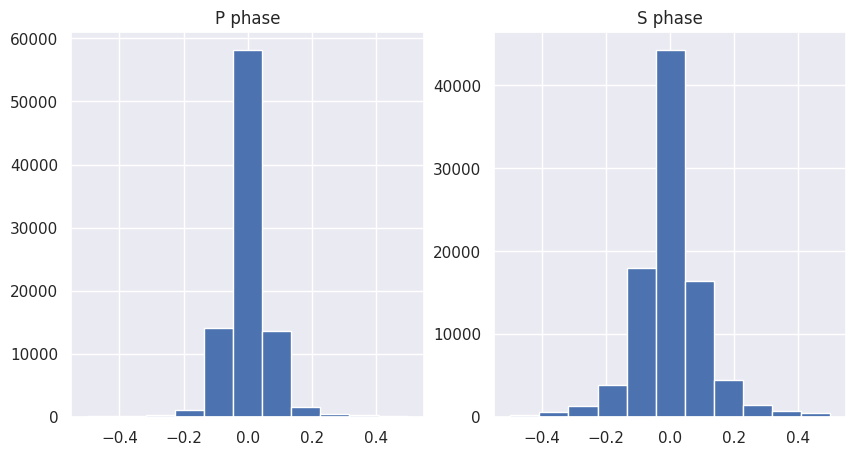


num_station >= 10 subset:

p_picks: 35547, s_picks: 37256, p_picks_label: 35420, s_picks_label: 35420
TP_p: 33710, TP_s: 34117, FP_p: 1837, FP_s: 3139, FN_p: 1710, FN_s: 1303
precision_p: 0.9483, recall_p: 0.9517, f1_p: 0.9500
precision_s: 0.9157, recall_s: 0.9632, f1_s: 0.9389
miu_p: 0.003845446455057846, sigma_p: 0.059678962834854375
miu_s: 0.005530087639593164, sigma_s: 0.10723264620834995


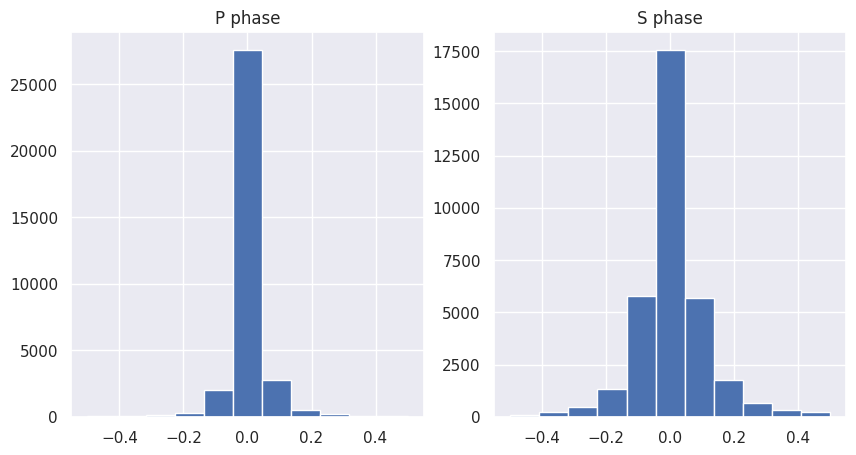

In [10]:
pick_metric.calc_metrics(dt_bar=dt_bar, distribution_bar=distribution_bar)
pick_metric_thld.calc_metrics(dt_bar=dt_bar, distribution_bar=distribution_bar)

# %%
print("\nWhole dataset:\n")
pick_metric.plot_residual()
print(f"\nnum_station >= {station_threshold} subset:\n")
pick_metric_thld.plot_residual()
print("\n")

### Event detection

In [11]:
# 获取csv_dir下所有的CSV文件的路径
event_files = [os.path.join(event_dir, f) for f in os.listdir(event_dir) if f.endswith(".csv")]

class EventMetric:
    def __init__(self):
        self.num_event_picks = 0
        self.num_event_picks_label = 0
        
        self.time_res = []
        self.x_res = []
        self.y_res = []
        self.z_res = []
        self.x = []
        self.y = []
        self.z = []  
        self.magnitude = []
        self.magnitude_pred = []
        self.snr = []
        self.epicenter_distance = []
        self.empty_files = 0
        self.no_match_files = 0
    
    def list2numpy(self):
        self.time_res = np.array(self.time_res)
        self.x_res = np.array(self.x_res)
        self.y_res = np.array(self.y_res)
        self.z_res = np.array(self.z_res)
        self.x = np.array(self.x)
        self.y = np.array(self.y)
        self.z = np.array(self.z)
        self.magnitude_pred = np.array(self.magnitude_pred)
        self.magnitude = np.array(self.magnitude)
        
        return
    
    def update_matched_picks(self, min_time_diff, x_diff, y_diff, z_diff, x_pred, y_pred, z_pred, magnitude_true, magnitude_pred):
        self.time_res.append(min_time_diff)
        self.x_res.append(x_diff)
        self.y_res.append(y_diff)
        self.z_res.append(z_diff)
        self.x.append(x_pred)
        self.y.append(y_pred)
        self.z.append(z_pred)
        self.magnitude.append(magnitude_true)
        self.magnitude_pred.append(magnitude_pred)
        if abs(min_time_diff) > 10:
            self.no_match_files += 1
        
        return
    
    def calc_metrics(self, event_dt_bar=3):
        index = abs(self.time_res) < event_dt_bar
        self.tp_picks = self.time_res[index]
        self.tp_x_res = self.x_res[index]
        self.tp_y_res = self.y_res[index]
        self.tp_z_res = self.z_res[index]
        self.tp_x = self.x[index]
        self.tp_y = self.y[index]
        self.tp_z = self.z[index]
        self.tp_magnitude = self.magnitude[index]
        self.tp_magnitude_pred = self.magnitude_pred[index]

        true_positives = len(self.tp_picks)
        false_positives = self.num_event_picks - true_positives
        false_negatives = self.num_event_picks_label - true_positives

        precision = true_positives / (true_positives + false_positives)
        recall = true_positives / (true_positives + false_negatives)
        f1 = 2 * precision * recall / (precision + recall)

        # the distribution of time residual
        miu_t = self.tp_picks.mean()
        miu_x = self.tp_x_res.mean()
        miu_y = self.tp_y_res.mean()
        miu_z = self.tp_z_res.mean()
        miu_m = (self.tp_magnitude_pred - self.tp_magnitude).mean()
        sigma_t = self.tp_picks.std()
        sigma_x = self.tp_x_res.std()
        sigma_y = self.tp_y_res.std()
        sigma_z = self.tp_z_res.std()
        sigma_m = (self.tp_magnitude_pred - self.tp_magnitude).std()
        
        # metric dict
        self.metric_dict = {
            "true_positives": true_positives,
            "false_positives": false_positives,
            "false_negatives": false_negatives,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "miu_t": miu_t,
            "miu_x": miu_x,
            "miu_y": miu_y,
            "miu_z": miu_z,
            "miu_m": miu_m,
            "sigma_t": sigma_t,
            "sigma_x": sigma_x,
            "sigma_y": sigma_y,
            "sigma_z": sigma_z,
            "sigma_m": sigma_m,
        }
        
        return
    
    def plot_residual(self, save_path=None):
        print(f"picks: {self.num_event_picks}, picks_label: {self.num_event_picks_label}")
        print(f"TP: {self.metric_dict['true_positives']}, FP: {self.metric_dict['false_positives']}, FN: {self.metric_dict['false_negatives']}")
        print(f"precision: {self.metric_dict['precision']:.4f}, recall: {self.metric_dict['recall']:.4f}, f1: {self.metric_dict['f1']:.4f}")
        print(f"miu_t: {self.metric_dict['miu_t']:.4f}, miu_x: {self.metric_dict['miu_x']:.4f}, miu_y: {self.metric_dict['miu_y']:.4f}, miu_z: {self.metric_dict['miu_z']:.4f}, miu_m: {self.metric_dict['miu_m']:.4f}")
        print(f"sigma_t: {self.metric_dict['sigma_t']:.4f}, sigma_x: {self.metric_dict['sigma_x']:.4f}, sigma_y: {self.metric_dict['sigma_y']:.4f}, sigma_z: {self.metric_dict['sigma_z']:.4f}, sigma_m: {self.metric_dict['sigma_m']:.4f}")

        fig, ax = plt.subplots(3, 2, figsize=(10, 15))
        ax[0, 0].hist(self.tp_picks, bins=11, range=(-3, 3))
        ax[0, 0].set_title("event time residual")
        ax[0, 1].hist(self.tp_x_res, bins=31, range=(-30, 30))
        ax[0, 1].set_title("event x residual")
        ax[1, 0].hist(self.tp_y_res, bins=31, range=(-30, 30))
        ax[1, 0].set_title("event y residual")
        ax[1, 1].hist(self.tp_z_res, bins=21, range=(-10, 10))
        ax[1, 1].set_title("event z residual")
        ax[2, 0].hist(self.tp_magnitude_pred-self.tp_magnitude, bins=21, range=(-2, 2))
        ax[2, 0].set_title("magnitude residual")
        if save_path is not None:
            plt.savefig(save_path)
        else:
            plt.show()
        
        return

In [12]:
def average_location(locations):
    # 将经纬度从度数转换为弧度
    locations = np.radians(locations)

    # 将经纬度转换为笛卡尔坐标
    x = np.cos(locations[:, 1]) * np.cos(locations[:, 0])
    y = np.cos(locations[:, 1]) * np.sin(locations[:, 0])
    z = np.sin(locations[:, 1])

    # 计算平均的笛卡尔坐标
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    z_mean = np.mean(z)

    # 将平均的笛卡尔坐标转换回经纬度
    lon = np.arctan2(y_mean, x_mean)
    hyp = np.sqrt(x_mean * x_mean + y_mean * y_mean)
    lat = np.arctan2(z_mean, hyp)

    # 将经纬度从弧度转换为度数
    return np.degrees([lon, lat])

In [16]:
event_metric = EventMetric()
event_metric_thld = EventMetric()

dbscan = DBSCAN(eps=dbscan_epsilon, min_samples=1)

with h5py.File(h5_file, "r") as fp:
    for pick in tqdm(event_files):
        event_id = re.sub(r'\.csv$', '', os.path.basename(pick))
        event = fp[event_id]
        num_stations = len(list(event.keys()))
        event_metric.num_event_picks_label += 1
        event_metric_thld.num_event_picks_label += 1 if num_stations>=station_threshold else 0

        # skip the empty pick file
        if os.path.getsize(pick) == 0:
            event_metric.empty_files += 1
            event_metric_thld.empty_files +=1 if num_stations>=station_threshold else 0
            continue
        df = pd.read_csv(pick)
        assert 'event_center_index' in df.columns, f'event_center_index not in {event_id}.columns'
        assert 'p_index' in df.columns, f'p_index not in {event_id}.columns'
        assert 's_index' in df.columns, f's_index not in {event_id}.columns'
        assert 'event_original_time' in df.columns, f'event_original_time not in {event_id}.columns'
        
        stations = df["station_id"].values
        hypoparameters = np.zeros((len(df),8))
        hypoparameters[:,0] = df["event_index"].values
        hypoparameters[:,1] = df["event_location_x"].values
        hypoparameters[:,2] = df["event_location_y"].values
        hypoparameters[:,3] = df["event_location_z"].values
        hypoparameters[:,4] = df["event_longitude"].values
        hypoparameters[:,5] = df["event_latitude"].values
        hypoparameters[:,6] = df["epicentral_distance"].values
        hypoparameters[:,7] = df["magnitude"].values
        
        labels = dbscan.fit_predict(hypoparameters[:,:4]*np.array(time_space_weight)[None,:]) # weighted
        classes, counts = np.unique(labels, return_counts=True)
        if event.attrs["num_stations"] > 5 and len(classes) > 1:
            if classes[0] == -1:
                classes = classes[1:]
                counts = counts[1:]
            classes = classes[counts>1]
            
        event_metric.num_event_picks += len(classes)
        event_metric_thld.num_event_picks += len(classes) if num_stations>=station_threshold else 0
        min_time_diff = np.inf
        x_diff = np.inf
        y_diff = np.inf
        z_diff = np.inf
        magnitude_pr = np.inf
        x_pred = np.inf
        y_pred = np.inf
        z_pred = np.inf
        station_ids = list(event.keys())
        label_x = event.attrs["longitude"]*degree2km*np.cos(np.radians(event.attrs["latitude"]))
        label_y = event.attrs["latitude"]*degree2km
        label_z = event.attrs["depth_km"]
        for c in classes:
            cluster_picks = hypoparameters[labels==c]
            cluster_picks = cluster_picks[np.argsort(cluster_picks[:,6])][:5]
            time_diff = (np.median(cluster_picks[:,0])*feature_scale - event.attrs["event_time_index"])/sample_rate
            if abs(time_diff) < abs(min_time_diff):
                #avg_center = average_location(cluster_picks[:,4:6])
                avg_center = np.median(cluster_picks[:,4:6], axis=0)
                x_pred = avg_center[0]*np.cos(np.radians(avg_center[1])) * degree2km
                y_pred = avg_center[1] * degree2km
                z_pred = np.median(cluster_picks[:,3])
                x_diff = (x_pred - label_x)
                y_diff = (y_pred - label_y)
                z_diff = (z_pred - label_z)
                magnitude_pr = np.median(cluster_picks[:,7])
                min_time_diff = time_diff
        event_metric.update_matched_picks(min_time_diff, x_diff, y_diff, z_diff, x_pred, y_pred, z_pred, event.attrs["magnitude"], magnitude_pr)
        if num_stations>=station_threshold:
            event_metric_thld.update_matched_picks(min_time_diff, x_diff, y_diff, z_diff, x_pred, y_pred, z_pred, event.attrs["magnitude"], magnitude_pr)
        
event_metric.list2numpy()
event_metric_thld.list2numpy()

print(f"whole dataset empty files: {event_metric.empty_files}")
print(f"whole dataset no match files: {event_metric.no_match_files}")
print("\n")
print(f"num_station >= {station_threshold} subset empty files: {event_metric_thld.empty_files}")
print(f"num_station >= {station_threshold} subset no match files: {event_metric_thld.no_match_files}")

100%|██████████| 16227/16227 [00:36<00:00, 441.77it/s]

whole dataset empty files: 114
whole dataset no match files: 96


num_station >= 10 subset empty files: 1
num_station >= 10 subset no match files: 8



Whole dataset:

picks: 20458, picks_label: 16227
TP: 15946, FP: 4512, FN: 281
precision: 0.7795, recall: 0.9827, f1: 0.8693
miu_t: 0.0861, miu_x: 0.8122, miu_y: 1.5714, miu_z: -0.3553, miu_m: 0.0299
sigma_t: 0.3626, sigma_x: 23.3523, sigma_y: 15.6502, sigma_z: 2.9736, sigma_m: 0.3396


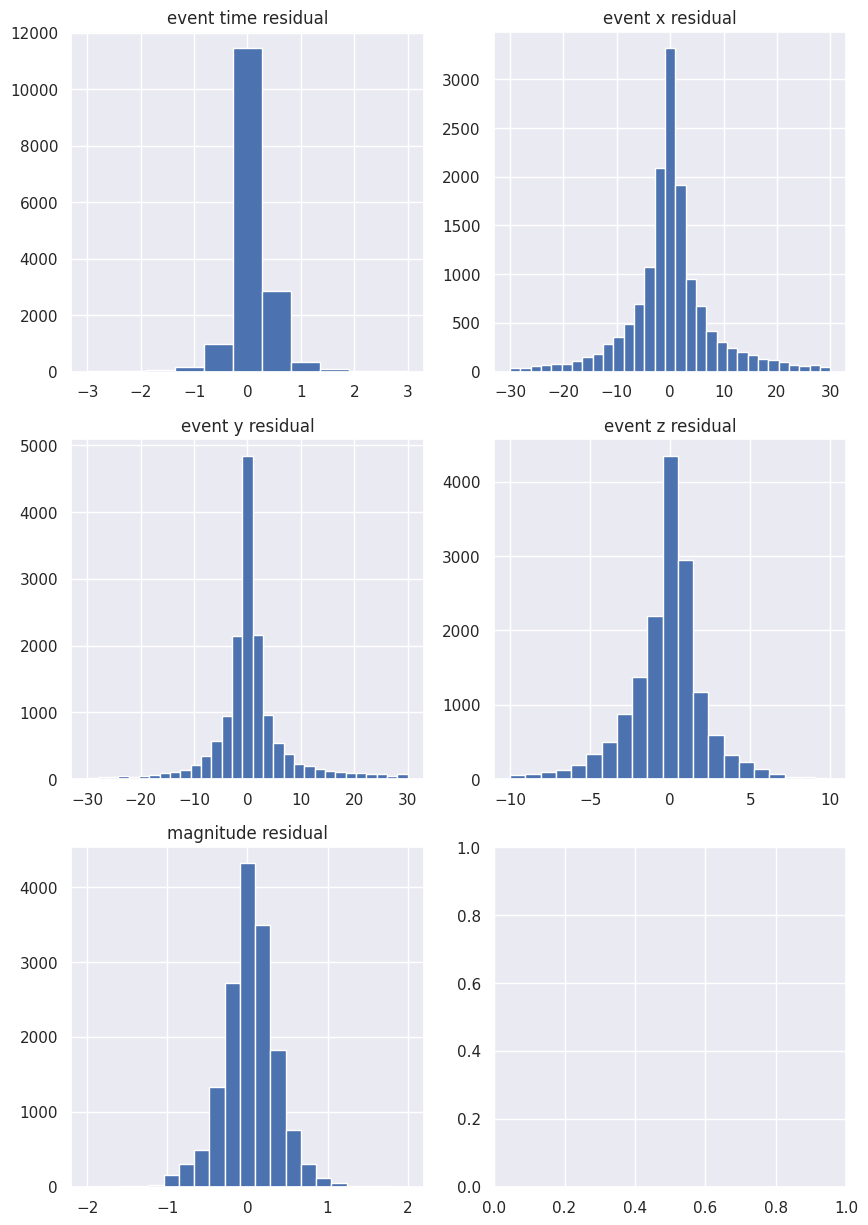


num_station >= 10 subset:

picks: 3652, picks_label: 2584
TP: 2573, FP: 1079, FN: 11
precision: 0.7045, recall: 0.9957, f1: 0.8252
miu_t: 0.1292, miu_x: 3.7810, miu_y: 2.6486, miu_z: -1.1559, miu_m: -0.0087
sigma_t: 0.3335, sigma_x: 31.1965, sigma_y: 19.6802, sigma_z: 3.8599, sigma_m: 0.2737


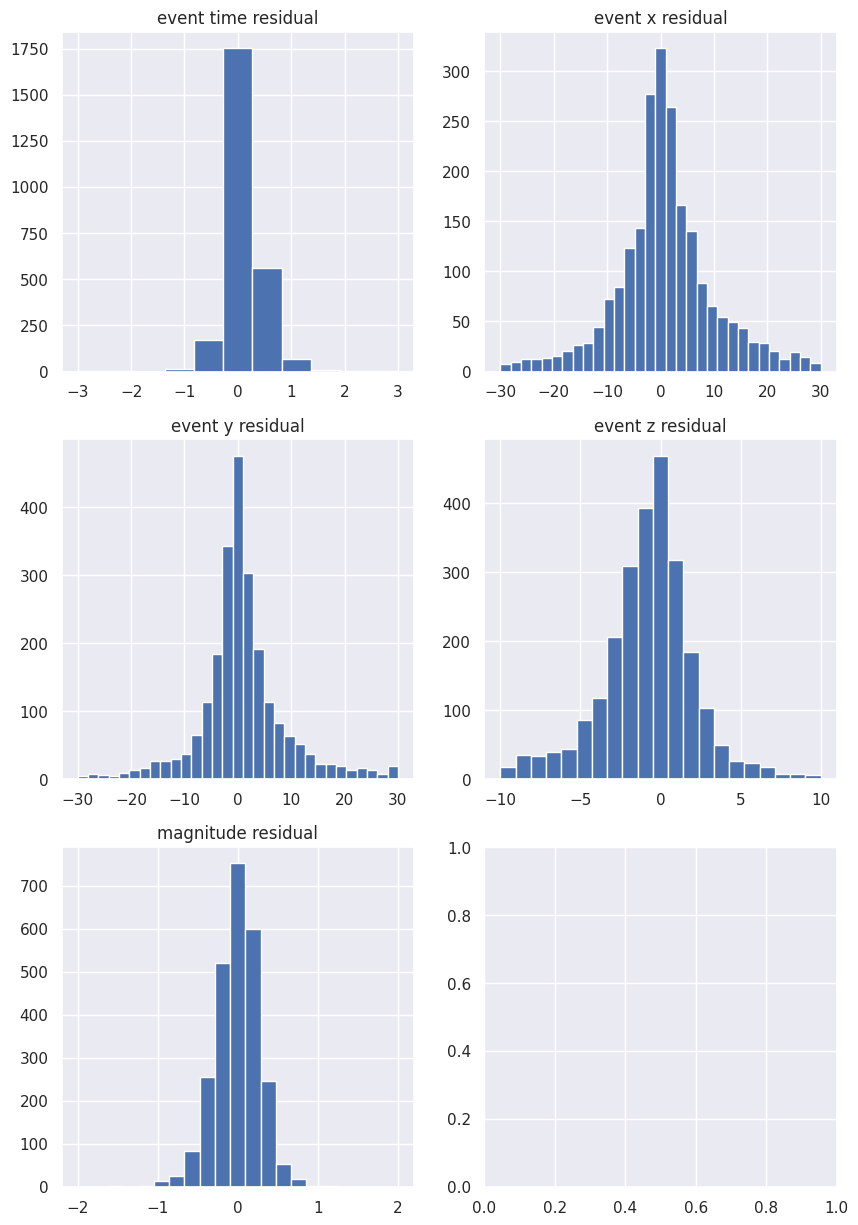

In [17]:
event_metric.calc_metrics(event_dt_bar=event_dt_bar)
event_metric_thld.calc_metrics(event_dt_bar=event_dt_bar)

# %%
print("\nWhole dataset:\n")
event_metric.plot_residual()
print(f"\nnum_station >= {station_threshold} subset:\n")
event_metric_thld.plot_residual()

In [18]:
p_recall_precision = np.array([[0.9694, 0.9625, 0.9594, 0.9559, 0.9517, 0.9479, 0.9432, 0.9371, 0.9293, 0.9201, 0.8955, ],
                                [0.8789, 0.9088, 0.9183, 0.9265, 0.9332, 0.9394, 0.9445, 0.9498, 0.9540, 0.9584, 0.9678, ]])
s_recall_precision = np.array([[0.9755, 0.9722, 0.9702, 0.9685, 0.9661, 0.9629, 0.9594, 0.9534, 0.9448, 0.9327, 0.8954, ],
                                [0.8256, 0.8648, 0.8781, 0.8886, 0.8977, 0.9063, 0.9150, 0.9227, 0.9293, 0.9368, 0.9511, ]])
event_recall_precision = np.array([[0.9904, 0.9868, 0.9831, 0.9779, 0.9719, 0.9656, 0.9577, 0.9489, 0.9376, 0.9276, 0.8992,],
                                    [0.4752, 0.6942, 0.7410, 0.7691, 0.7916, 0.8113, 0.8273, 0.8422, 0.8553, 0.8677, 0.8923,]])                  

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


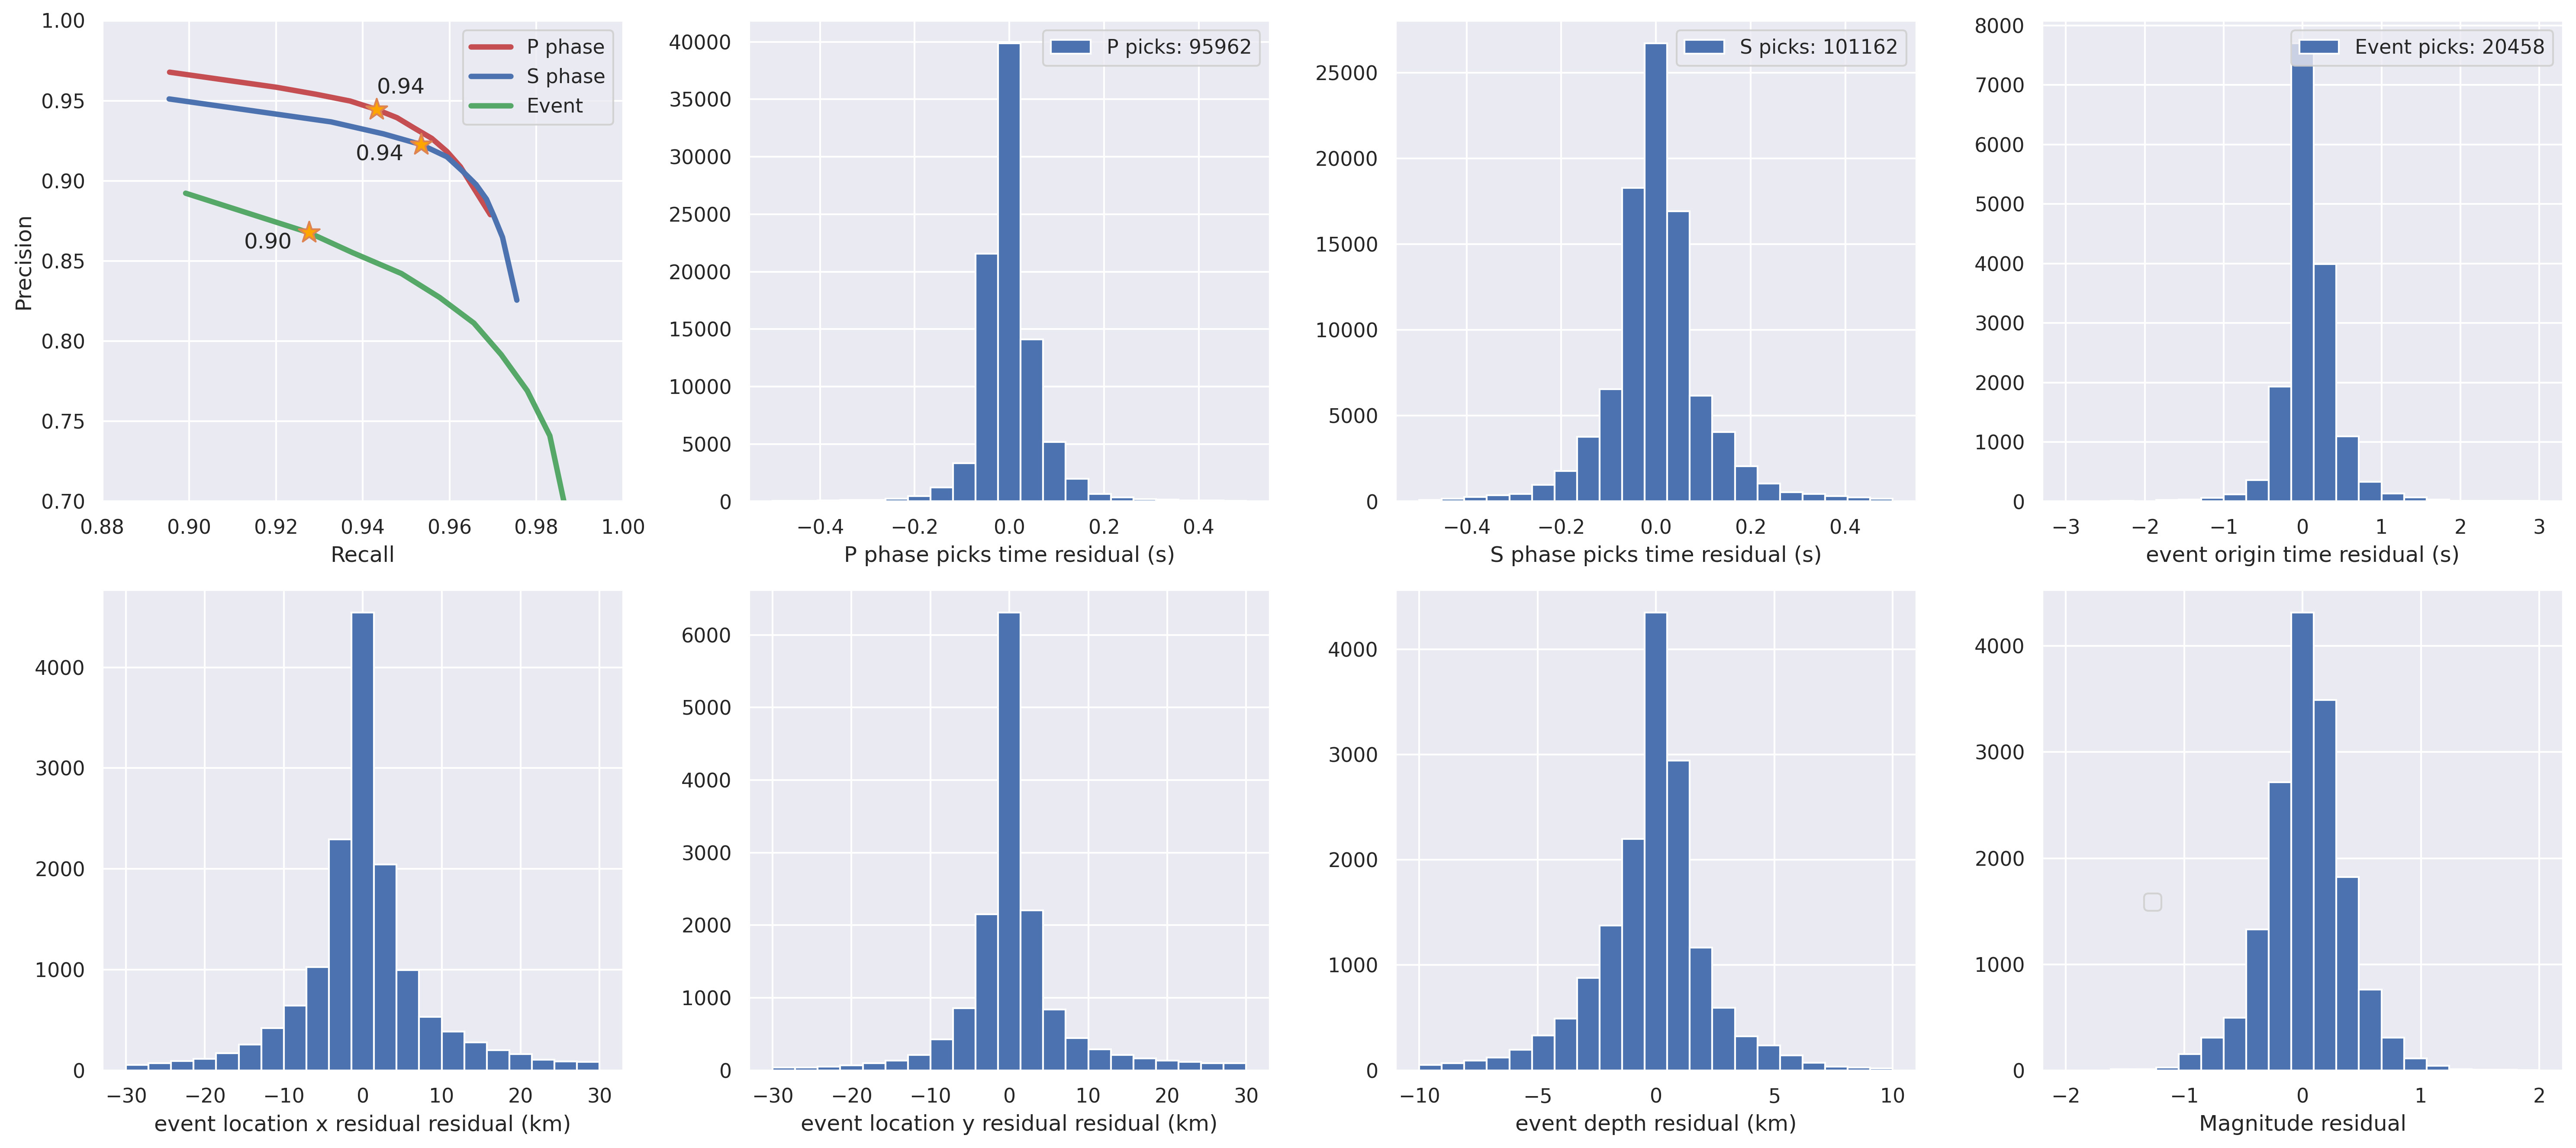

In [19]:
fig, ax = plt.subplots(2, 4, figsize=(20, 9), dpi=300)
ax[0, 0].plot(p_recall_precision[0], p_recall_precision[1], label="P phase", linewidth=3, c="C3")
ax[0, 0].plot(s_recall_precision[0], s_recall_precision[1], label="S phase", linewidth=3, c="C0")
ax[0, 0].plot(event_recall_precision[0], event_recall_precision[1], label="Event", linewidth=3, c="C2")
# use star to mark the highest f1 score point and the f1 score
p_f1 = 2 * p_recall_precision[0] * p_recall_precision[1] / (p_recall_precision[0] + p_recall_precision[1])
s_f1 = 2 * s_recall_precision[0] * s_recall_precision[1] / (s_recall_precision[0] + s_recall_precision[1])
event_f1 = 2 * event_recall_precision[0] * event_recall_precision[1] / (event_recall_precision[0] + event_recall_precision[1])
# 黑色描边, 描边细一点
ax[0, 0].scatter(p_recall_precision[0][p_f1.argmax()], p_recall_precision[1][p_f1.argmax()], marker="*", s=150, c="orange", edgecolors="C1", linewidths=1, zorder=10)
ax[0, 0].scatter(s_recall_precision[0][s_f1.argmax()], s_recall_precision[1][s_f1.argmax()], marker="*", s=150, c="orange", edgecolors="C1", linewidths=1, zorder=10)
ax[0, 0].scatter(event_recall_precision[0][event_f1.argmax()], event_recall_precision[1][event_f1.argmax()], marker="*", s=150, c="orange", edgecolors="C1", linewidths=1, zorder=10)

ax[0, 0].text(p_recall_precision[0][p_f1.argmax()], p_recall_precision[1][p_f1.argmax()]+0.01, f"{p_f1.max():.2f}", fontsize=12)
ax[0, 0].text(s_recall_precision[0][s_f1.argmax()]-0.015, s_recall_precision[1][s_f1.argmax()]-0.01, f"{s_f1.max():.2f}", fontsize=12)
ax[0, 0].text(event_recall_precision[0][event_f1.argmax()]-0.015, event_recall_precision[1][event_f1.argmax()]-0.01, f"{event_f1.max():.2f}", fontsize=12)
ax[0, 0].legend()
ax[0, 0].set_xlim(0.88, 1.0)
ax[0, 0].set_ylim(0.7, 1.0)
ax[0, 0].set_xlabel("Recall")
ax[0, 0].set_ylabel("Precision")

ax[0, 1].hist(pick_metric.res_p, bins=21, range=(-distribution_bar, distribution_bar), label=f"P picks: {pick_metric.num_p_picks}")
ax[0, 1].legend(loc="upper right")
ax[0, 1].set_xlabel("P phase picks time residual (s)")
ax[0, 2].hist(pick_metric.res_s, bins=21, range=(-distribution_bar, distribution_bar), label=f"S picks: {pick_metric.num_s_picks}")
ax[0, 2].legend(loc="upper right")
ax[0, 2].set_xlabel("S phase picks time residual (s)")
ax[0, 3].hist(event_metric.tp_picks, bins=21, range=(-3, 3), label=f"Event picks: {event_metric.num_event_picks}")
ax[0, 3].legend(loc="upper right")
ax[0, 3].set_xlabel("event origin time residual (s)")
ax[1, 0].hist(event_metric.tp_x_res, bins=21, range=(-30, 30))
ax[1, 0].set_xlabel("event location x residual residual (km)")
ax[1, 1].hist(event_metric.tp_y_res, bins=21, range=(-30, 30))
ax[1, 1].set_xlabel("event location y residual residual (km)")
ax[1, 2].hist(event_metric.tp_z_res, bins=21, range=(-10, 10))
ax[1, 2].set_xlabel("event depth residual (km)")
ax[1, 3].hist(event_metric.tp_magnitude_pred-event_metric.tp_magnitude, bins=21, range=(-2, 2))
ax[1, 3].set_xlabel("Magnitude residual")

plt.legend(loc="center right", bbox_to_anchor=(0.25, 0.35), fontsize=12)
plt.tight_layout()
plt.show()

In [35]:
sns.color_palette("deep")

[(0.2980392156862745, 0.4470588235294118, 0.6901960784313725),
 (0.8666666666666667, 0.5176470588235295, 0.3215686274509804),
 (0.3333333333333333, 0.6588235294117647, 0.40784313725490196),
 (0.7686274509803922, 0.3058823529411765, 0.3215686274509804),
 (0.5058823529411764, 0.4470588235294118, 0.7019607843137254),
 (0.5764705882352941, 0.47058823529411764, 0.3764705882352941),
 (0.8549019607843137, 0.5450980392156862, 0.7647058823529411),
 (0.5490196078431373, 0.5490196078431373, 0.5490196078431373),
 (0.8, 0.7254901960784313, 0.4549019607843137),
 (0.39215686274509803, 0.7098039215686275, 0.803921568627451)]